In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os
print(os.getcwd())
print(os.listdir())

/Users/paint/Desktop
['untitled folder', '0712 (1)(1).mov', 'umamusume-uma-musume.gif', 'd1bf2715b795d2c3bc80f519cae787ef.jpg', '25anomaly.csv', 'Unlabeled Belgium Terrain Map.png', '5824b290b0d00b6c77d50fa08a7f9153.jpg', 'bulky-hammer-9758173_1280.png', 'giphy (1).gif', 'color_uncertainties_pauebbay.csv', 'edqt082026080743', 'IMG_8513.heic', 'krebs cycle (3).png', '.DS_Store', 'Oguri Eating Uma Musume - AGON DESU CHANNEL (720p).mp4', 'full_barrel-Photoroom_1__30230-removebg-preview.png', 'wallpaper.png', 'proxy', 'MyTable_19_pauebbay.csv', 'DataSetExport-DO Saturation.YSI_Calc@39565997-Maximum-%-20260820195020.csv', 'superanomalous_stars.csv', 'ANOMALYMODELINGnumb4.ipynb', 'top300knn.csv', '.localized', 'MyTable_30_pauebbay.csv', '$RECYCLE.BIN', 'videoplayback (9).mp4', 'top300svm.csv', 'tachyonslab', 'IMG_8514.heic', 'agnes', 'Screenshot 2026-10-09 at 10.29.16\u202fPM.png', 'motion.zip', 'Oguri Cap sneeze.mp4', 'Sugar_JE2_BE2.webp', 'lofstellar.numbers', 'edqt082026080439.zip', 'agne

In [3]:
import os
print(os.path.expanduser("~/Desktop"))

/Users/paint/Desktop


In [4]:
import os
print(os.listdir(os.path.expanduser("~/Desktop")))

['untitled folder', '0712 (1)(1).mov', 'umamusume-uma-musume.gif', 'd1bf2715b795d2c3bc80f519cae787ef.jpg', '25anomaly.csv', 'Unlabeled Belgium Terrain Map.png', '5824b290b0d00b6c77d50fa08a7f9153.jpg', 'bulky-hammer-9758173_1280.png', 'giphy (1).gif', 'color_uncertainties_pauebbay.csv', 'edqt082026080743', 'IMG_8513.heic', 'krebs cycle (3).png', '.DS_Store', 'Oguri Eating Uma Musume - AGON DESU CHANNEL (720p).mp4', 'full_barrel-Photoroom_1__30230-removebg-preview.png', 'wallpaper.png', 'proxy', 'MyTable_19_pauebbay.csv', 'DataSetExport-DO Saturation.YSI_Calc@39565997-Maximum-%-20260820195020.csv', 'superanomalous_stars.csv', 'ANOMALYMODELINGnumb4.ipynb', 'top300knn.csv', '.localized', 'MyTable_30_pauebbay.csv', '$RECYCLE.BIN', 'videoplayback (9).mp4', 'top300svm.csv', 'tachyonslab', 'IMG_8514.heic', 'agnes', 'Screenshot 2026-10-09 at 10.29.16\u202fPM.png', 'motion.zip', 'Oguri Cap sneeze.mp4', 'Sugar_JE2_BE2.webp', 'lofstellar.numbers', 'edqt082026080439.zip', 'agnestransporant', 'NS-3 

In [5]:
df = pd.read_csv('/Users/paint/Desktop/lofstellar.csv', comment="#", on_bad_lines='skip')

In [6]:
df.isnull().sum()

objid        0
ra           0
dec          0
u            0
g            0
r            0
i            0
z            0
run          0
rerun        0
camcol       0
field        0
specobjid    0
class        0
redshift     0
plate        0
mjd          0
fiberid      0
dtype: int64

In [7]:
stars = df[df['class']=='STAR']

In [8]:
stars['u-g'] = stars['u'] - stars['g']
stars['g-r'] = stars['g'] - stars['r']
stars['r-i'] = stars['r'] - stars['i']
stars['i-z'] = stars['i'] - stars['z']

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/498600974.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['u-g'] = stars['u'] - stars['g']
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/498600974.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['g-r'] = stars['g'] - stars['r']
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/498600974.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using 

In [9]:
home_dir = os.path.expanduser("~/Desktop")
desktop_path = os.path.join(home_dir, "starsdataset.csv")

stars.to_csv(desktop_path, index=False)

In [10]:
starsX = stars.drop(['objid','ra','dec',
                     'run','rerun','camcol','field'
                     ,'specobjid','plate'
                     ,'mjd','fiberid','class','redshift'], axis=1)



from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(starsX)

In [11]:
#
#   ------------------- ONE-CLASS SVM -------------------
#

In [12]:
from sklearn.svm import OneClassSVM

X_svm = X_scaled

oc_svm = OneClassSVM(kernel='rbf', gamma=.1, nu=.05)

oc_svm.fit(X_scaled)

y_pred = oc_svm.predict(X_scaled)


svm_scores = oc_svm.decision_function(X_scaled)


stars['svm_scores'] = svm_scores



/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/2901529935.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['svm_scores'] = svm_scores


In [13]:
svm_scores_ranked = stars.sort_values(by='svm_scores', ascending=True).head(300)

svm_scores_ranked

,objid,ra,dec,u,g,r,i,z,run,rerun,...,class,redshift,plate,mjd,fiberid,u-g,g-r,r-i,i-z,svm_scores
96983,1237662195075579947,220.714568,36.883426,18.90096,19.20051,20.37618,18.79337,26.51354,3893,301,...,STAR,-0.000024,5173,56046,125,-0.29955,-1.17567,1.58281,-7.72017,-203.379843
80363,1237661386000302218,231.372816,45.984669,19.38833,19.51513,24.80203,21.02037,17.96841,3705,301,...,STAR,-0.000187,8510,57846,486,-0.12680,-5.28690,3.78166,3.05196,-203.379774
58798,1237680297269919879,332.848424,18.661936,19.14684,17.59798,23.73106,21.26742,16.44646,8108,301,...,STAR,-0.000195,7574,56945,229,1.54886,-6.13308,2.46364,4.82096,-203.379684
61064,1237654599960494090,167.655166,3.668510,17.61061,17.47520,19.68389,24.10461,22.73707,2125,301,...,STAR,0.000080,581,52356,50,0.13541,-2.20869,-4.42072,1.36754,-203.379648
55132,1237655128772051260,257.773375,31.072983,19.13785,18.20921,22.27007,20.31893,25.33364,2248,301,...,STAR,-0.000019,975,52411,567,0.92864,-4.06086,1.95114,-5.01471,-203.379628
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9120,1237662306200125584,240.602807,26.945961,15.32899,11.47435,11.09069,10.95665,11.41484,3919,301,...,STAR,0.000049,3005,54876,122,3.85464,0.38366,0.13404,-0.45819,-181.543962
30806,1237662306200060023,240.475437,27.073145,15.55195,13.71675,13.15882,14.24368,13.45190,3919,301,...,STAR,-0.000298,3005,54876,129,1.83520,0.55793,-1.08486,0.79178,-181.349292
95172,1237667727509094651,84.454490,5.674204,15.54053,11.98844,10.68000,10.21224,10.72633,5181,301,...,STAR,0.000228,2841,54451,232,3.55209,1.30844,0.46776,-0.51409,-180.751035
44107,1237662193983619131,166.777687,40.422021,14.03423,11.02281,10.61304,10.54864,10.79281,3893,301,...,STAR,-0.000017,3000,54892,623,3.01142,0.40977,0.06440,-0.24417,-180.544756


In [14]:
svm_scores_ranked[['objid','ra','dec']].to_csv("top300svm.csv",index=False)

In [15]:
#
#   ------------------- K NEAREST NEIGHBORS EVAL -------------------
#

In [16]:
from pyod.models.knn import KNN


model = KNN(n_neighbors=10, contamination=.01)

model.fit(X_scaled)

labels = model.labels_
scores = model.decision_scores_

In [17]:
anomaly = labels[labels == 1]

len(anomaly)

381

In [18]:
stars['knn_score'] = scores
stars['knn_label'] = labels

anomaly_df = stars[stars['knn_label'] == 1]

anomaly_df

knn_scores_ranked = stars.sort_values(by='knn_score', ascending=False).head(300)


knn_scores_ranked

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/3535923965.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['knn_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/3535923965.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['knn_label'] = labels


,objid,ra,dec,u,g,r,i,z,run,rerun,...,plate,mjd,fiberid,u-g,g-r,r-i,i-z,svm_scores,knn_score,knn_label
21532,1237673807043297393,119.206941,17.109716,18.46669,17.88514,25.49612,24.87711,16.09237,6597,301,...,2729,54419,8,0.58155,-7.61098,0.61901,8.78474,-203.357126,30.012634,1
5653,1237661362368938016,193.192880,47.670968,19.57635,18.92036,26.79265,26.89399,19.18876,3699,301,...,3367,54998,440,0.65599,-7.87229,-0.10134,7.70523,-203.351005,28.043195,1
39566,1237656906352820288,354.854438,-0.970122,18.43040,18.09878,28.20384,21.92753,18.93126,2662,301,...,4213,55449,292,0.33162,-10.10506,6.27631,2.99627,-203.378270,25.887129,1
78843,1237660635457912912,155.067265,43.228822,18.67755,17.77039,27.06385,19.21938,17.20647,3530,301,...,1358,52994,236,0.90716,-9.29346,7.84447,2.01291,-203.356071,25.003721,1
51128,1237671935508152426,259.325460,33.104779,16.80535,18.85506,24.80205,18.99215,22.82690,6161,301,...,10904,58402,977,-2.04971,-5.94699,5.80990,-3.83475,-203.345148,21.974550,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17722,1237650761860317225,195.164109,-2.258495,15.63452,14.28735,13.76672,15.06573,13.50104,1231,301,...,339,51692,354,1.34717,0.52063,-1.29901,1.56469,-190.610770,2.874144,1
75955,1237671128585076830,172.143033,-7.442756,16.47968,15.08543,14.47367,17.08592,14.07241,5973,301,...,2861,54583,494,1.39425,0.61176,-2.61225,3.01351,-190.081883,2.859348,1
13981,1237671067918860337,21.380111,39.783366,17.10360,15.01994,14.29070,17.41673,14.05692,5959,301,...,2336,53712,491,2.08366,0.72924,-3.12603,3.35981,-189.754956,2.857887,1
76188,1237673413508792557,71.926286,22.632469,18.70948,16.36913,15.21741,15.52837,14.38776,6505,301,...,2681,54397,567,2.34035,1.15172,-0.31096,1.14061,-152.223544,2.857058,1


In [19]:
knn_scores_ranked[['objid','ra','dec']].to_csv("top300knn.csv",index=False)

In [20]:
#
#  ----------------- ISOLATION FOREST EVALUATION  -----------------
#

In [21]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=200, contamination=.01, random_state=42)

iso.fit(X_scaled)

IsolationForest(contamination=0.01, n_estimators=200, random_state=42)

In [22]:
iso_scores = -iso.decision_function(X_scaled)

stars['iso_score'] = iso_scores

iso_score_ranked = stars.sort_values('iso_score', ascending=False).head(300)

iso_score_ranked

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/2136625933.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['iso_score'] = iso_scores


,objid,ra,dec,u,g,r,i,z,run,rerun,...,mjd,fiberid,u-g,g-r,r-i,i-z,svm_scores,knn_score,knn_label,iso_score
64248,1237662195056181268,162.964344,40.688391,13.61358,9.98800,9.005167,12.118810,8.947795,3893,301,...,54843,346,3.62558,0.982833,-3.113643,3.171015,-203.171911,10.535759,1,0.127188
91904,1237662195056377939,163.649802,40.830382,14.80243,10.83143,10.008550,13.788540,9.893856,3893,301,...,54843,432,3.97100,0.822880,-3.779990,3.894684,-203.229241,9.400229,1,0.121619
4458,1237662341085986883,239.423127,28.548438,12.26240,10.51139,10.068540,13.417860,10.225510,3927,301,...,54876,384,1.75101,0.442850,-3.349320,3.192350,-203.254798,8.899781,1,0.102800
4184,1237671071143625021,41.344043,73.167363,15.42768,12.04763,9.919155,8.896696,9.537069,5960,301,...,54453,402,3.38005,2.128475,1.022459,-0.640373,-199.542833,4.876302,1,0.097272
95168,1237667727509094713,84.661773,5.635899,14.97052,13.59141,10.679360,12.675950,10.959340,5181,301,...,54451,191,1.37911,2.912050,-1.996590,1.716610,-203.162319,8.559119,1,0.096473
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29774,1237678580355957258,336.137585,22.359669,18.80324,19.12608,19.645060,19.924960,20.578840,7708,301,...,56478,370,-0.32284,-0.518980,-0.279900,-0.653880,-33.754800,0.867176,0,0.008881
43866,1237661385991979015,204.513450,54.961379,16.35170,15.61639,12.520460,12.062310,13.055520,3705,301,...,54844,575,0.73531,3.095930,0.458150,-0.993210,-197.317595,3.489739,1,0.008562
43863,1237661385992044612,204.858476,54.858797,16.51629,14.87237,12.803380,12.369770,12.886250,3705,301,...,54844,605,1.64392,2.068990,0.433610,-0.516480,-182.679653,3.967401,1,0.008269
75955,1237671128585076830,172.143033,-7.442756,16.47968,15.08543,14.473670,17.085920,14.072410,5973,301,...,54583,494,1.39425,0.611760,-2.612250,3.013510,-190.081883,2.859348,1,0.008137


In [23]:
iso_score_ranked[['objid','ra','dec']].to_csv("top300iso.csv",index=False)

In [24]:
#
# ----------------------- LOCAL OUTLIER FACTOR  -----------------------
#

In [25]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=30, 
                         contamination=.01)

y_pred = lof.fit_predict(X_scaled)

In [26]:
stars['lofscores'] = -lof.negative_outlier_factor_

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/3241484115.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['lofscores'] = -lof.negative_outlier_factor_


In [27]:
lof_scores_sorted = stars.sort_values('lofscores', ascending=False).head(300)

lof_scores_sorted

,objid,ra,dec,u,g,r,i,z,run,rerun,...,fiberid,u-g,g-r,r-i,i-z,svm_scores,knn_score,knn_label,iso_score,lofscores
22978,1237664874046095462,130.310191,23.333959,18.76793,17.97481,17.08627,20.53817,22.82405,4517,301,...,298,0.79312,0.88854,-3.45190,-2.28588,-203.373758,13.715455,1,-0.005458,7.819947
46621,1237673756041412705,109.723918,30.601169,17.19667,15.96626,15.91377,15.95114,17.29091,6585,301,...,594,1.23041,0.05249,-0.03737,-1.33977,-180.526041,4.621787,1,-0.142820,7.180329
60854,1237659118249705639,216.168799,49.499440,16.32169,16.20484,15.74571,15.39983,15.18680,3177,301,...,285,0.11685,0.45913,0.34588,0.21303,-75.912559,2.063080,0,-0.146597,6.823405
6415,1237658303278743603,159.434587,57.198794,17.11016,16.71652,16.39649,16.15305,15.96478,2987,301,...,198,0.39364,0.32003,0.24344,0.18827,-17.359755,1.298682,0,-0.207524,6.352122
14201,1237664286709907585,135.364657,10.145299,17.77773,16.78414,16.78859,16.38667,16.34748,4380,301,...,513,0.99359,-0.00445,0.40192,0.03919,-4.479220,1.274596,0,-0.232252,6.241767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
742,1237655125545975880,184.220774,5.011627,18.80213,17.78021,17.11151,16.94287,16.90841,2247,301,...,186,1.02192,0.66870,0.16864,0.03446,18.997034,0.584892,0,-0.272867,2.827045
19887,1237650760242626604,178.950084,-3.651897,18.61739,14.98552,13.49015,13.16122,12.42532,1231,301,...,58,3.63187,1.49537,0.32893,0.73590,-164.827479,3.213211,1,0.033963,2.826477
74501,1237651538182471692,221.359687,62.087657,17.82431,15.77776,15.36135,15.19644,15.16363,1412,301,...,182,2.04655,0.41641,0.16491,0.03281,-1.151183,0.893327,0,-0.192298,2.821640
95394,1237661064413249716,142.774424,8.764108,18.37943,18.06945,18.37132,18.63201,19.34775,3630,301,...,958,0.30998,-0.30187,-0.26069,-0.71574,-39.571475,1.440800,0,-0.077367,2.819965


In [28]:
lof_scores_sorted[['objid','ra','dec']].to_csv("top300lof.csv",index=False)

In [29]:
#
# --------------- JACCARD SIMILARITY ---------------
#

In [30]:
lof_ids = set(lof_scores_sorted['objid'])
iso_ids = set(iso_score_ranked['objid'])
knn_ids = set(knn_scores_ranked['objid'])   
svm_ids = set(svm_scores_ranked['objid'])

In [31]:
def jaccard(set1, set2):
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    return intersection / union

In [32]:
print("LOF vs KNN:", jaccard(lof_ids, knn_ids))
print("LOF vs Iso:", jaccard(lof_ids, iso_ids))
print("LOF vs SVM:", jaccard(lof_ids, svm_ids))
print("KNN vs Iso:", jaccard(knn_ids, iso_ids))
print("KNN vs SVM:", jaccard(knn_ids, svm_ids))
print("Iso vs SVM:", jaccard(iso_ids, svm_ids))

LOF vs KNN: 0.1111111111111111
LOF vs Iso: 0.04895104895104895
LOF vs SVM: 0.08892921960072596
KNN vs Iso: 0.3824884792626728
KNN vs SVM: 0.7647058823529411
Iso vs SVM: 0.4354066985645933


In [33]:


# Total number of stars in your dataset
N = len(stars)

# Number of permutations
n_perm = 10000

# Function to compute random Jaccard
def random_jaccard(top_size, ids1, ids2):
    rand_overlaps = []
    all_ids = list(stars['objid'])
    for _ in range(n_perm):
        # Randomly pick sets of same size
        rand1 = set(np.random.choice(all_ids, size=top_size, replace=False))
        rand2 = set(np.random.choice(all_ids, size=top_size, replace=False))
        # Compute Jaccard
        j = len(rand1 & rand2) / len(rand1 | rand2)
        rand_overlaps.append(j)
    rand_overlaps = np.array(rand_overlaps)
    # p-value: fraction of random overlaps >= observed
    p_value = np.mean(rand_overlaps >= jaccard(ids1, ids2))
    return p_value, rand_overlaps

# Example: LOF vs KNN
p_lof_knn, rand_lof_knn = random_jaccard(300, lof_ids, knn_ids)
print("LOF vs KNN Jaccard p-value:", p_lof_knn)

LOF vs KNN Jaccard p-value: 0.0


In [34]:
p_lof_iso, _ = random_jaccard(300, lof_ids, iso_ids)
p_lof_svm, _ = random_jaccard(300, lof_ids, svm_ids)
p_knn_iso, _ = random_jaccard(300, knn_ids, iso_ids)
p_knn_svm, _ = random_jaccard(300, knn_ids, svm_ids)
p_iso_svm, _ = random_jaccard(300, iso_ids, svm_ids)



In [35]:
print(p_iso_svm)
print(p_knn_svm)
print(p_knn_iso)
print(p_lof_svm)
print(p_lof_iso)

0.0
0.0
0.0
0.0
0.0


In [36]:
#
# HYPER-PARAMETER CHANGING
# 

In [37]:
"""

nus = [0.01, 0.03, 0.05, 0.1]
gammas = [0.01, 0.1]

results = []

for nu in nus:
    for gamma in gammas:
        model = OneClassSVM(kernel='rbf', nu=nu, gamma=gamma)
        model.fit(X)

        scores = model.decision_function(X)

        results.append({
            "nu": nu,
            "gamma": gamma,
            "scores": scores
        })

"""

rows = []
results = []
neighbors = [5, 10, 20, 30, 50]
for neighbor in neighbors:
    knnrob = KNN(n_neighbors=neighbor, contamination=0.01)
    knnrob.fit(X_scaled)
    scores = knnrob.decision_function(X_scaled)

    for s in scores:
        rows.append({
            'neighbor': neighbor,
            'score': s
        })
    stars['temp_score'] = scores
    
    top_ids = set(
        stars.sort_values('temp_score', ascending=False)
             .head(300)['objid']
    )
    
    j = jaccard(knn_ids, top_ids)
    
    results.append({
        'neighbors': neighbor,
        'jaccard': j
    })

knnrobust = pd.DataFrame(rows)
jaccards = pd.DataFrame(results)

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/2889055574.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/2889055574.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/2889055574.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_index

In [38]:
jaccards

,neighbors,jaccard
0,5,0.823708
1,10,0.954397
2,20,0.875000
3,30,0.829268
4,50,0.729107


In [39]:
rows = []
results=[]
lof_neighbors = [10, 15, 20, 30, 40, 50]

for neighbor in lof_neighbors:
    lofrob = LocalOutlierFactor(n_neighbors=neighbor,
                                 contamination=.01,
                                 )
    lofrob.fit(X_scaled)

    scores = -lofrob.negative_outlier_factor_
    j = jaccard(lof_ids, top_ids)
    for s in scores:
        rows.append({
            'neighbor': neighbor,
            'score': s})
    stars['temp_score'] = scores
    
    top_ids = set(
        stars.sort_values('temp_score', ascending=False)
             .head(300)['objid']
    )
    
   
    
    results.append({
        'neighbors': neighbor,
        'jaccard': j
    })
        
jaccards = pd.DataFrame(results)


/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/1724721058.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/1724721058.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/1724721058.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_index

In [40]:
lofrobust = pd.DataFrame(rows)

jaccards

,neighbors,jaccard
0,10,0.086957
1,15,0.405152
2,20,0.550388
3,30,0.694915
4,40,1.000000
5,50,0.764706


In [41]:
rows = []
results=[]
n_estim = [50, 100, 200, 500]
contaminat = [0.01, 0.03, 0.05]

for n in n_estim:
    for contam in contaminat:
        isorob = IsolationForest(n_estimators=n, contamination=contam)
        isorob.fit(X_scaled)

        scores = -isorob.decision_function(X_scaled)
        j = jaccard(iso_ids, top_ids)
        for s in scores:
            rows.append({
            'contamination': contam,
            'n_estimators': n,
            'score': s
        })
            
    stars['temp_score'] = scores
    
    top_ids = set(
        stars.sort_values('temp_score', ascending=False)
             .head(300)['objid']
    )
    
        
    
    results.append({
        'n_estimator': n,
        'contaminators': contam,
        'jaccard': j
    })
isorobust = pd.DataFrame(rows)
jaccards = pd.DataFrame(results)

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/3807095483.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/3807095483.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/3807095483.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_index

In [42]:
isorobust
jaccards

,n_estimator,contaminators,jaccard
0,50,0.05,0.060071
1,100,0.05,0.734104
2,200,0.05,0.759531
3,500,0.05,0.791045


In [43]:

nus = [0.01, 0.03, 0.05, 0.1]
gammas = [0.01, 0.1]

rows = []
results=[]
for nu in nus:
    for gamma in gammas:
        
        model = OneClassSVM(kernel='rbf', nu=nu, gamma=gamma)
        model.fit(X_scaled)

        scores = model.decision_function(X_scaled)
        stars['temp_score'] = scores

        top_ids = set(
        stars.sort_values('temp_score', ascending=False)
             .head(300)['objid']
    )
        
        j = jaccard(svm_ids, top_ids)


        results.append({
        'nu': nu,
        'gamma': gamma,
        'jaccard': j
    })
        for s in scores:
            rows.append({
                "nu": nu,
            "gamma": gamma,
            "scores": s
        })
        
    
        
svmrobust = pd.DataFrame(rows)
jaccards = pd.DataFrame(results)

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/4258346636.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/4258346636.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/4258346636.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_index

In [44]:
results = []

nus = [0.01, 0.03, 0.05, 0.1]
gammas = [0.01, 0.1]

for nu in nus:
    for gamma in gammas:

        model = OneClassSVM(kernel='rbf', nu=nu, gamma=gamma)
        model.fit(X_scaled)

        scores = model.decision_function(X_scaled)
        stars['temp_score'] = scores

        top_ids = set(
            stars.sort_values('temp_score', ascending=True)
                 .head(300)['objid']
        )

        j = jaccard(svm_ids, top_ids)

        results.append({
            'nu': nu,
            'gamma': gamma,
            'jaccard': j
        })

svmrobust = pd.DataFrame(results)

/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/1141601164.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/1141601164.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['temp_score'] = scores
/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/1141601164.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_index

In [45]:
svmrobust


,nu,gamma,jaccard
0,0.01,0.01,0.769912
1,0.01,0.10,0.639344
2,0.03,0.01,0.780415
3,0.03,0.10,0.941748
4,0.05,0.01,0.754386
5,0.05,0.10,1.000000
6,0.10,0.01,0.744186
7,0.10,0.10,0.923077


In [46]:
import scipy.spatial.distance as dist
import numpy as np

# Define the locus centroid from the full stellar population
color_cols = ['u-g', 'g-r', 'r-i', 'i-z']
centroid = stars[color_cols].median().values  # median is more robust than mean

# Function to compute Euclidean distance from centroid
def locus_distance(df):
    vectors = df[color_cols].values
    return np.array([dist.euclidean(v, centroid) for v in vectors])

# Apply to each model's top 300
svm_scores_ranked['locus_dist'] = locus_distance(svm_scores_ranked)
knn_scores_ranked['locus_dist'] = locus_distance(knn_scores_ranked)
iso_score_ranked['locus_dist'] = locus_distance(iso_score_ranked)
lof_scores_sorted['locus_dist'] = locus_distance(lof_scores_sorted)

# Also compute for the full population as a baseline
stars['locus_dist'] = locus_distance(stars)



/var/folders/33/vjsdscbn3md0jcbry4j1t5wh0000gp/T/ipykernel_7739/3288086372.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stars['locus_dist'] = locus_distance(stars)


In [47]:
print(svm_scores_ranked['locus_dist'].median())
print(knn_scores_ranked['locus_dist'].median())
print(iso_score_ranked['locus_dist'].median())
print(lof_scores_sorted['locus_dist'].median())


3.154626054419575
3.039482552519944
2.4485994073118764
0.6751197507466148


In [48]:
stars['locus_dist'].median()

0.27401717464421543

In [49]:
# 
# ----------- distance calculation -----------
# 

In [50]:
from scipy.stats import mannwhitneyu

for name, df in [('LOF', lof_scores_sorted), ('ISO', iso_score_ranked), 
                  ('KNN', knn_scores_ranked), ('SVM', svm_scores_ranked)]:
    stat, p = mannwhitneyu(df['locus_dist'], stars['locus_dist'], alternative='greater')
    print(f"{name}: p = {p:.4e}")

LOF: p = 7.1328e-72
ISO: p = 1.4379e-185
KNN: p = 3.4249e-186
SVM: p = 2.7326e-189


In [51]:
#
# ----- figures ------
#

In [52]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

stars['PC1'] = X_pca[:, 0]
stars['PC2'] = X_pca[:, 1]

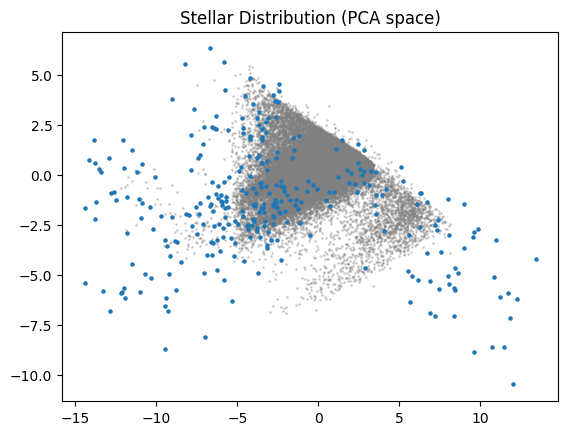

In [53]:
svm_outliers = stars.loc[svm_scores_ranked.index]
plt.scatter(stars['PC1'], stars['PC2'], s=1, alpha=0.3, c='gray')
plt.scatter(
    svm_outliers['PC1'],
    svm_outliers['PC2'],
    s=5,
    label='SVM anomalies'
)

plt.title("Stellar Distribution (PCA space)")
plt.show()

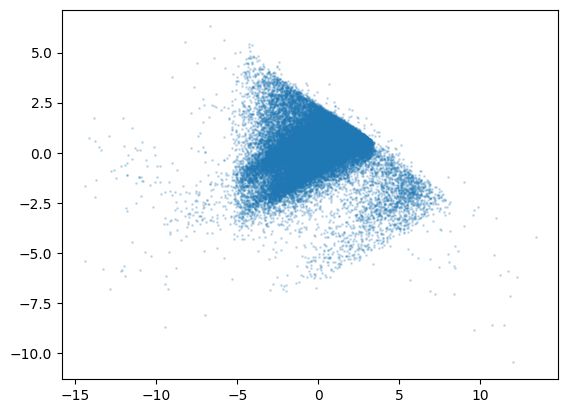

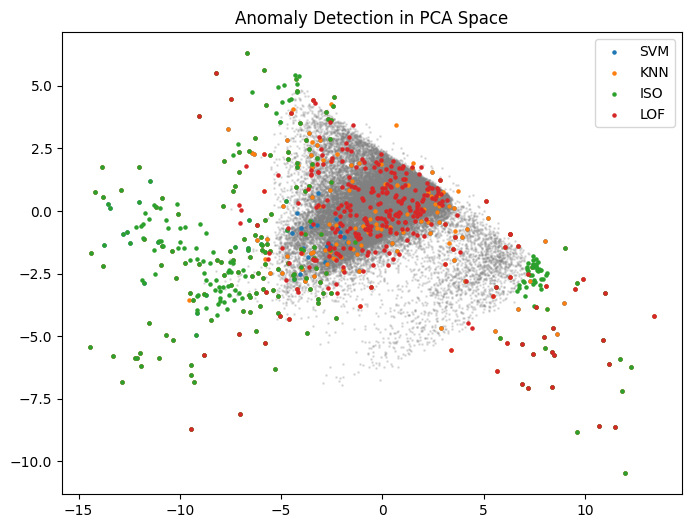

In [54]:
svm_outliers = stars.loc[svm_scores_ranked.index]
knn_outliers = stars.loc[knn_scores_ranked.index]
iso_outliers = stars.loc[iso_score_ranked.index]
lof_outliers = stars.loc[lof_scores_sorted.index]
plt.scatter(stars['PC1'], stars['PC2'], s=1, alpha=0.2)

plt.figure(figsize=(8,6))

# base stars
plt.scatter(stars['PC1'], stars['PC2'], s=1, alpha=0.2, color='gray')

# overlays (CORRECT)
plt.scatter(svm_outliers['PC1'], svm_outliers['PC2'], s=5, label='SVM')
plt.scatter(knn_outliers['PC1'], knn_outliers['PC2'], s=5, label='KNN')
plt.scatter(iso_outliers['PC1'], iso_outliers['PC2'], s=5, label='ISO')
plt.scatter(lof_outliers['PC1'], lof_outliers['PC2'], s=5, label='LOF')

plt.legend()
plt.title("Anomaly Detection in PCA Space")
plt.show()

In [55]:
stars['consensus'] = (
    stars['objid'].isin(svm_scores_ranked['objid']).astype(int) +
    stars['objid'].isin(knn_scores_ranked['objid']).astype(int) +
    stars['objid'].isin(iso_score_ranked['objid']).astype(int) +
    stars['objid'].isin(lof_scores_sorted['objid']).astype(int)
)

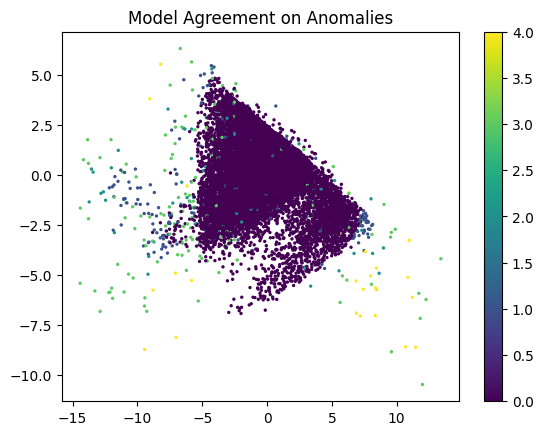

In [56]:
plt.scatter(stars['PC1'], stars['PC2'], c=stars['consensus'], cmap='viridis', s=2)
plt.colorbar()
plt.title("Model Agreement on Anomalies")
plt.show()

In [57]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

models = ['LOF', 'ISO', 'KNN', 'SVM']

jaccard_matrix = pd.DataFrame(index=models, columns=models, dtype=float)

# fill diagonal
for m in models:
    jaccard_matrix.loc[m, m] = 1.0

# fill known values (from your results)
jaccard_matrix.loc['LOF', 'KNN'] = 0.111
jaccard_matrix.loc['LOF', 'ISO'] = 0.049
jaccard_matrix.loc['LOF', 'SVM'] = 0.089
jaccard_matrix.loc['KNN', 'ISO'] = 0.382
jaccard_matrix.loc['KNN', 'SVM'] = 0.765
jaccard_matrix.loc['ISO', 'SVM'] = 0.435

# symmetry
for i in models:
    for j in models:
        if pd.isna(jaccard_matrix.loc[i, j]):
            jaccard_matrix.loc[i, j] = jaccard_matrix.loc[j, i]

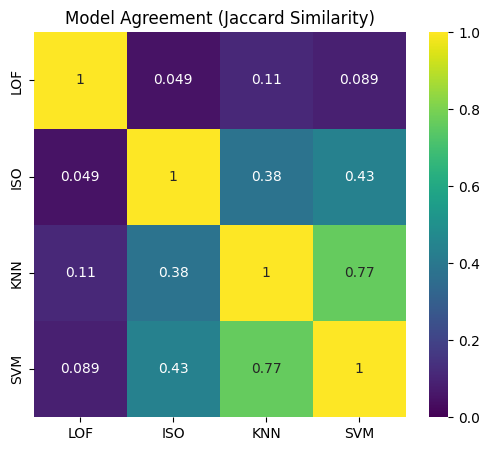

In [58]:
plt.figure(figsize=(6,5))
sns.heatmap(jaccard_matrix, annot=True, cmap='viridis', vmin=0, vmax=1)
plt.title("Model Agreement (Jaccard Similarity)")
plt.show()

In [59]:
stars['svm_flag'] = 0
stars.loc[svm_scores_ranked.index, 'svm_flag'] = 1

stars['knn_flag'] = 0
stars.loc[knn_scores_ranked.index, 'knn_flag'] = 1

stars['iso_flag'] = 0
stars.loc[iso_score_ranked.index, 'iso_flag'] = 1

stars['lof_flag'] = 0
stars.loc[lof_scores_sorted.index, 'lof_flag'] = 1

In [60]:
stars['consensus'] = (
    stars['svm_flag'] +
    stars['knn_flag'] +
    stars['iso_flag'] +
    stars['lof_flag']
)

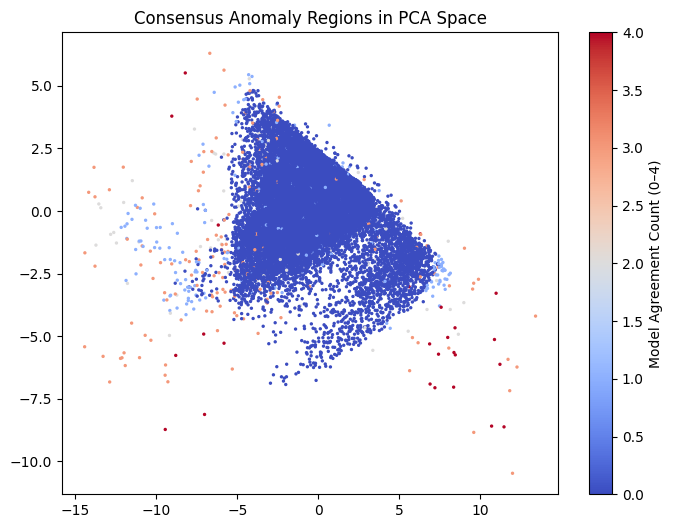

In [61]:
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    stars['PC1'],
    stars['PC2'],
    c=stars['consensus'],
    s=2,
    cmap='coolwarm'
)

plt.colorbar(scatter, label="Model Agreement Count (0–4)")
plt.title("Consensus Anomaly Regions in PCA Space")
plt.show()

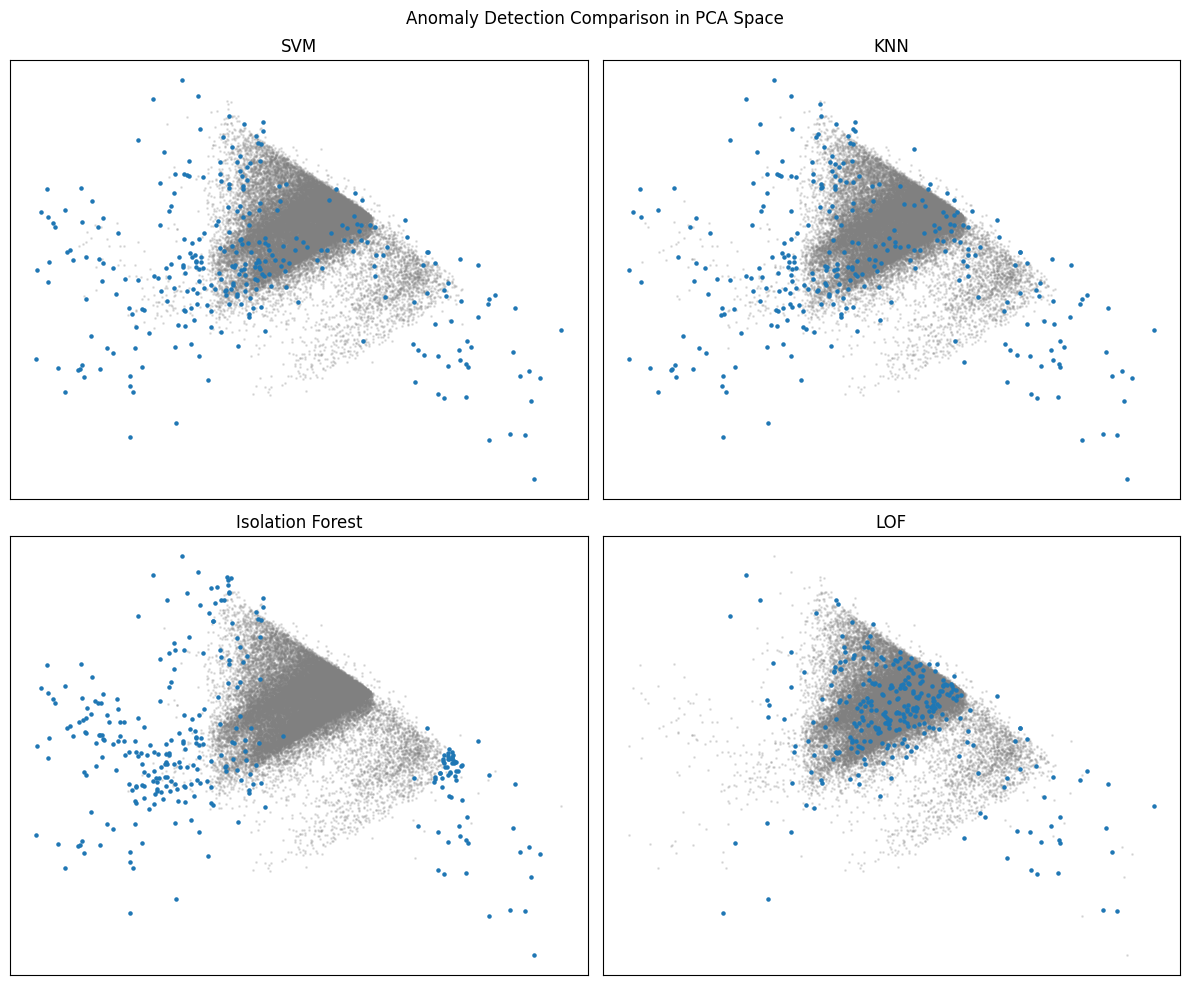

In [62]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

models_data = [
    (svm_outliers, "SVM"),
    (knn_outliers, "KNN"),
    (iso_outliers, "Isolation Forest"),
    (lof_outliers, "LOF")
]

axes = axes.flatten()

for ax, (data, name) in zip(axes, models_data):
    ax.scatter(stars['PC1'], stars['PC2'], s=1, alpha=0.2, color='gray')
    ax.scatter(data['PC1'], data['PC2'], s=5)

    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Anomaly Detection Comparison in PCA Space")
plt.tight_layout()
plt.show()

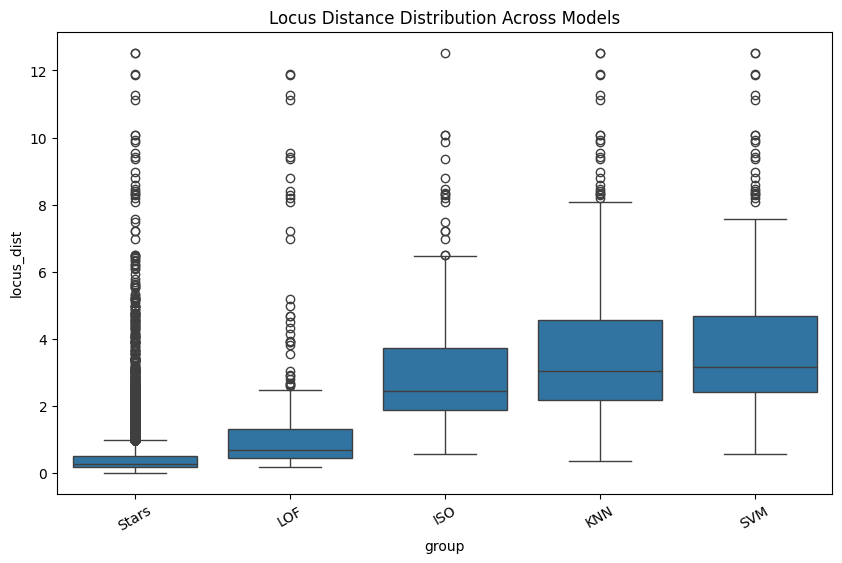

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = pd.DataFrame({
    "locus_dist": np.concatenate([
        stars['locus_dist'],
        lof_scores_sorted['locus_dist'],
        iso_score_ranked['locus_dist'],
        knn_scores_ranked['locus_dist'],
        svm_scores_ranked['locus_dist']
    ]),
    "group": (["Stars"] * len(stars) +
              ["LOF"] * len(lof_scores_sorted) +
              ["ISO"] * len(iso_score_ranked) +
              ["KNN"] * len(knn_scores_ranked) +
              ["SVM"] * len(svm_scores_ranked))
})

plt.figure(figsize=(10,6))
sns.boxplot(data=plot_df, x="group", y="locus_dist")
plt.title("Locus Distance Distribution Across Models")
plt.xticks(rotation=30)
plt.show()

In [64]:
# --- consensus --

stars['consensus'].value_counts().sort_index()

superanomalous = stars[stars['consensus'] == 4]

home_dir = os.path.expanduser("~/Desktop")
desktop_path = os.path.join(home_dir, "superanomalous_stars.csv")


superanomalous.to_csv(desktop_path, index=False)

In [65]:
# ============================================================
# PHOTOMETRIC ERRORS FOR THE 25 CONSENSUS-4 OBJECTS
# ============================================================

phot_errors = pd.DataFrame({
    'objid': [
        1237648721765793820,
        1237651752949383239,
        1237652934030721314,
        1237655108367220808,
        1237655128772051260,
        1237661385995911182,
        1237661434855489567,
        1237662195075579947,
        1237663328934494292,
        1237663547981562045,
        1237663789570261172,
        1237664131014197307,
        1237664131020226574,
        1237665428107427969,
        1237665441001111594,
        1237665442593832972,
        1237666214072614943,
        1237667210514137131,
        1237667727508635961,
        1237667727509225705,
        1237668649325495104,
        1237668649861580026,
        1237670964844298252,
        1237671123226460181,
        1237680505041518814
    ],

    'err_u': [
        0.01028817, 0.0780827, 0.02767603, 0.09414511, 0.1999718,
        0.01758421, 0.01915522, 0.2926542, 0.002272948, 0.02949261,
        0.00555547, 0.04663183, 0.07032687, 0.02371092, 0.02894389,
        0.004669402, 0.01123973, 0.0249414, 0.006362502, 0.00265305,
        0.01315771, 0.02839036, 0.0430664, 0.05153755, 0.02631156
    ],

    'err_g': [
        0.00221391, 0.01642147, 0.01177759, 0.01386411, 0.05529035,
        0.01235954, 0.01460509, 0.2028902, 0.001967726, 0.0100196,
        0.0106399, 0.03053473, 0.09443593, 0.02623892, 0.01652995,
        0.003900146, 0.006042598, 0.01377437, 0.001058719, 0.000997568,
        0.004105303, 0.003624464, 0.04016505, 0.02888647, 0.02458774
    ],

    'err_r': [
        0.002330412, 0.008447693, 0.02345323, 0.07834755, 4.085207,
        0.00940851, 0.01141507, 0.4595507, 0.002220398, 0.01705527,
        0.01049573, 0.01498551, 10.35206, 1.523956, 0.1175124,
        0.005141738, 0.009964839, 3.759911, 0.008316385, 0.004280881,
        0.001538297, 0.003962499, 0.01153959, 0.2123044, 0.02405777
    ],

    'err_i': [
        0.005891072, 9.767446, 0.04914663, 0.04987435, 0.8363851,
        3.919586, 0.08858148, 0.2332655, 0.002044037, 0.04056649,
        0.004865855, 0.06941714, 11.3834, 1.364741, 0.03737133,
        0.003323942, 0.01974683, 3.829756, 0.009429249, 0.006380425,
        0.001223385, 0.0009845984, 0.03243468, 0.1684577, 0.0207565
    ],

    'err_z': [
        0.009316066, 5.101033, 0.8996227, 4.288869, 2.130757,
        2.191965, 1.915761, 1.073372, 0.003114222, 0.878965,
        0.004466072, 0.1200646, 0.3773718, 0.03988505, 2.431683,
        0.008554209, 0.5482482, 0.1649938, 0.01380171, 0.002782138,
        0.003891862, 0.003494277, 1.162011, 3.164077, 0.7562607
    ]
})

print(phot_errors.shape)
print(phot_errors.head())

(25, 6)
                 objid     err_u     err_g     err_r     err_i     err_z
0  1237648721765793820  0.010288  0.002214  0.002330  0.005891  0.009316
1  1237651752949383239  0.078083  0.016421  0.008448  9.767446  5.101033
2  1237652934030721314  0.027676  0.011778  0.023453  0.049147  0.899623
3  1237655108367220808  0.094145  0.013864  0.078348  0.049874  4.288869
4  1237655128772051260  0.199972  0.055290  4.085207  0.836385  2.130757


In [66]:
# --- PERTURBATION ANALYSIS ---


In [67]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from pyod.models.knn import KNN

# ============================================================
# SETTINGS
# ============================================================

N_SIMULATIONS = 1000
TOP_K = 300
RANDOM_SEED = 42

photometric_cols = ['u', 'g', 'r', 'i', 'z']
feature_cols = [
    'u', 'g', 'r', 'i', 'z',
    'u-g', 'g-r', 'r-i', 'i-z'
]

rng = np.random.default_rng(RANDOM_SEED)


# ============================================================
# 1. PREPARE THE ORIGINAL FEATURE SPACE
# ============================================================

# Make a copy so your original DataFrame is untouched
df = stars.copy()

# Create colors
df['u-g'] = df['u'] - df['g']
df['g-r'] = df['g'] - df['r']
df['r-i'] = df['r'] - df['i']
df['i-z'] = df['i'] - df['z']

# Original feature matrix
X = df[feature_cols].values

# Fit scaler ONCE to the original population
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# ============================================================
# 2. CONSENSUS-4 OBJECTS
# ============================================================

consensus_ids = [
    1237670964844298252,
    1237648721765793820,
    1237680505041518814,
    1237667210514137131,
    1237652934030721314,
    1237671123226460181,
    1237663789570261172,
    1237663328934494292,
    1237665442593832972,
    1237665428107427969,
    1237655108367220808,
    1237651752949383239,
    1237655128772051260,
    1237668649325495104,
    1237665441001111594,
    1237664131020226574,
    1237668649861580026,
    1237667727509225705,
    1237666214072614943,
    1237661385995911182,
    1237664131014197307,
    1237661434855489567,
    1237667727508635961,
    1237662195075579947,
    1237663547981562045
]

# Make sure objid is numeric
df['objid'] = df['objid'].astype(np.int64)

candidate_mask = df['objid'].isin(consensus_ids)

candidates = df.loc[candidate_mask].copy()

print("Consensus-4 candidates found:", len(candidates))

if len(candidates) != 25:
    print("WARNING: Expected 25 candidates.")
    print("Missing IDs:")
    print(set(consensus_ids) - set(candidates['objid']))


# ============================================================
# 3. LOAD PHOTOMETRIC ERRORS
# ============================================================

# IMPORTANT:
# Replace these column names if your photometric-error DataFrame
# uses different names.

# Expected:
# phot_errors['objid']
# phot_errors['err_u']
# phot_errors['err_g']
# phot_errors['err_r']
# phot_errors['err_i']
# phot_errors['err_z']

error_cols = ['err_u', 'err_g', 'err_r', 'err_i', 'err_z']

candidates = candidates.merge(
    phot_errors[
        ['objid', 'err_u', 'err_g', 'err_r', 'err_i', 'err_z']
    ],
    on='objid',
    how='left'
)

print("Candidates:", len(candidates))
print("\nMissing errors:")
print(candidates[
    ['err_u', 'err_g', 'err_r', 'err_i', 'err_z']
].isna().sum())

# ============================================================
# 4. FUNCTION TO CALCULATE THE 9 FEATURES
# ============================================================

def make_features(values):
    """
    values = array-like of shape (5,)
             [u, g, r, i, z]

    Returns:
        [u, g, r, i, z, u-g, g-r, r-i, i-z]
    """

    u, g, r, i, z = values

    return np.array([
        u,
        g,
        r,
        i,
        z,
        u - g,
        g - r,
        r - i,
        i - z
    ])


# ============================================================
# 5. FUNCTION TO RUN THE FOUR ANOMALY MODELS
# ============================================================

def get_anomaly_scores(X_reference, candidate_features):
    """
    X_reference:
        Original standardized 38,071-star population.

    candidate_features:
        Standardized feature vector for one candidate.

    Returns:
        Four model scores.
    """

    # --------------------------------------------------------
    # LOF
    # --------------------------------------------------------
    # novelty=True allows us to score a new candidate against
    # the fixed reference population.
    lof = LocalOutlierFactor(
        n_neighbors=30,
        contamination=0.01,
        novelty=True
    )

    lof.fit(X_reference)

    lof_score = -lof.decision_function(
        candidate_features.reshape(1, -1)
    )[0]


    # --------------------------------------------------------
    # KNN / PyOD
    # --------------------------------------------------------
    knn = KNN(
        n_neighbors=10,
        contamination=0.01
    )

    knn.fit(X_reference)

    knn_score = knn.decision_function(
        candidate_features.reshape(1, -1)
    )[0]


    # --------------------------------------------------------
    # Isolation Forest
    # --------------------------------------------------------
    iso = IsolationForest(
        n_estimators=200,
        contamination=0.01,
        random_state=42
    )

    iso.fit(X_reference)

    # Larger = more anomalous after sign reversal
    iso_score = -iso.decision_function(
        candidate_features.reshape(1, -1)
    )[0]


    # --------------------------------------------------------
    # One-Class SVM
    # --------------------------------------------------------
    svm = OneClassSVM(
        kernel='rbf',
        gamma=0.1,
        nu=0.05
    )

    svm.fit(X_reference)

    # Larger = more anomalous after sign reversal
    svm_score = -svm.decision_function(
        candidate_features.reshape(1, -1)
    )[0]


    return {
        'LOF': lof_score,
        'KNN': knn_score,
        'IsolationForest': iso_score,
        'SVM': svm_score
    }

Consensus-4 candidates found: 25
Candidates: 25

Missing errors:
err_u    0
err_g    0
err_r    0
err_i    0
err_z    0
dtype: int64


In [68]:
# ============================================================
# FIT MODELS ON ORIGINAL 38,071-STAR POPULATION
# ============================================================

print("Fitting models...")

lof_model = LocalOutlierFactor(
    n_neighbors=30,
    contamination=0.01,
    novelty=True
)
lof_model.fit(X_scaled)

knn_model = KNN(
    n_neighbors=10,
    contamination=0.01
)
knn_model.fit(X_scaled)

iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42
)
iso_model.fit(X_scaled)

svm_model = OneClassSVM(
    kernel='rbf',
    gamma=0.1,
    nu=0.05
)
svm_model.fit(X_scaled)

print("All four models fitted successfully.")

Fitting models...
All four models fitted successfully.


In [69]:
# ============================================================
# ORIGINAL TOP-300 THRESHOLDS
# ============================================================

TOP_K = 300

lof_population_scores = -lof_model.decision_function(X_scaled)
knn_population_scores = knn_model.decision_function(X_scaled)
iso_population_scores = -iso_model.decision_function(X_scaled)
svm_population_scores = -svm_model.decision_function(X_scaled)

lof_threshold = np.sort(lof_population_scores)[-TOP_K]
knn_threshold = np.sort(knn_population_scores)[-TOP_K]
iso_threshold = np.sort(iso_population_scores)[-TOP_K]
svm_threshold = np.sort(svm_population_scores)[-TOP_K]

print("Thresholds:")
print(f"LOF: {lof_threshold:.6f}")
print(f"KNN: {knn_threshold:.6f}")
print(f"Isolation Forest: {iso_threshold:.6f}")
print(f"SVM: {svm_threshold:.6f}")

Thresholds:
LOF: 0.118354
KNN: 2.716679
Isolation Forest: 0.008012
SVM: 180.526041


In [70]:
# ============================================================
# 1,000-REALIZATION UNCERTAINTY PERTURBATION EXPERIMENT
# ============================================================

N_SIMULATIONS = 1000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

results = []

print("Starting experiment...")
print(f"25 candidates × {N_SIMULATIONS} simulations = "
      f"{25 * N_SIMULATIONS:,} total realizations")
print()

for _, row in candidates.iterrows():

    objid = row['objid']

    # Original magnitudes
    original_values = np.array([
        row['u'],
        row['g'],
        row['r'],
        row['i'],
        row['z']
    ], dtype=float)

    # SDSS photometric uncertainties
    errors = np.array([
        row['err_u'],
        row['err_g'],
        row['err_r'],
        row['err_i'],
        row['err_z']
    ], dtype=float)

    # Counters
    lof_count = 0
    knn_count = 0
    iso_count = 0
    svm_count = 0

    consensus_4_count = 0
    consensus_3plus_count = 0
    consensus_2plus_count = 0

    # --------------------------------------------------------
    # Monte Carlo
    # --------------------------------------------------------

    for sim in range(N_SIMULATIONS):

        # Perturb each magnitude according to its uncertainty
        noise = rng.normal(
            loc=0,
            scale=errors
        )

        perturbed_values = original_values + noise

        # Create u,g,r,i,z + four colors
        u, g, r, i, z = perturbed_values

        perturbed_features = np.array([
            u,
            g,
            r,
            i,
            z,
            u - g,
            g - r,
            r - i,
            i - z
        ])

        # Standardize using the ORIGINAL population scaler
        perturbed_scaled = scaler.transform(
            perturbed_features.reshape(1, -1)
        )

        # ----------------------------------------------------
        # Get anomaly scores
        # ----------------------------------------------------

        lof_score = -lof_model.decision_function(
            perturbed_scaled
        )[0]

        knn_score = knn_model.decision_function(
            perturbed_scaled
        )[0]

        iso_score = -iso_model.decision_function(
            perturbed_scaled
        )[0]

        svm_score = -svm_model.decision_function(
            perturbed_scaled
        )[0]

        # ----------------------------------------------------
        # Is it still inside the original top-300 region?
        # ----------------------------------------------------

        lof_anomaly = lof_score >= lof_threshold
        knn_anomaly = knn_score >= knn_threshold
        iso_anomaly = iso_score >= iso_threshold
        svm_anomaly = svm_score >= svm_threshold

        # Individual stability
        lof_count += lof_anomaly
        knn_count += knn_anomaly
        iso_count += iso_anomaly
        svm_count += svm_anomaly

        # Consensus
        consensus_count = sum([
            lof_anomaly,
            knn_anomaly,
            iso_anomaly,
            svm_anomaly
        ])

        if consensus_count == 4:
            consensus_4_count += 1

        if consensus_count >= 3:
            consensus_3plus_count += 1

        if consensus_count >= 2:
            consensus_2plus_count += 1

    # --------------------------------------------------------
    # Store stability
    # --------------------------------------------------------

    results.append({
        'objid': objid,

        'LOF_stability':
            lof_count / N_SIMULATIONS,

        'KNN_stability':
            knn_count / N_SIMULATIONS,

        'IF_stability':
            iso_count / N_SIMULATIONS,

        'SVM_stability':
            svm_count / N_SIMULATIONS,

        'consensus_4_stability':
            consensus_4_count / N_SIMULATIONS,

        'consensus_3plus_stability':
            consensus_3plus_count / N_SIMULATIONS,

        'consensus_2plus_stability':
            consensus_2plus_count / N_SIMULATIONS
    })

    print(
        f"{objid}: "
        f"4/4={consensus_4_count/N_SIMULATIONS:.3f} | "
        f"3+={consensus_3plus_count/N_SIMULATIONS:.3f}"
    )


stability_results = pd.DataFrame(results)

print("\n================================")
print("EXPERIMENT COMPLETE")
print("================================")

Starting experiment...
25 candidates × 1000 simulations = 25,000 total realizations

1237670964844298252: 4/4=0.945 | 3+=0.999
1237648721765793820: 4/4=0.836 | 3+=1.000
1237680505041518814: 4/4=0.979 | 3+=1.000
1237667210514137131: 4/4=0.567 | 3+=0.955
1237652934030721314: 4/4=0.872 | 3+=0.903
1237671123226460181: 4/4=0.608 | 3+=0.922
1237663789570261172: 4/4=1.000 | 3+=1.000
1237663328934494292: 4/4=1.000 | 3+=1.000
1237665442593832972: 4/4=1.000 | 3+=1.000
1237665428107427969: 4/4=0.706 | 3+=1.000
1237655108367220808: 4/4=0.288 | 3+=0.961
1237651752949383239: 4/4=0.648 | 3+=0.894
1237655128772051260: 4/4=0.431 | 3+=0.994
1237668649325495104: 4/4=1.000 | 3+=1.000
1237665441001111594: 4/4=0.834 | 3+=0.967
1237664131020226574: 4/4=0.861 | 3+=0.991
1237668649861580026: 4/4=0.340 | 3+=1.000
1237667727509225705: 4/4=1.000 | 3+=1.000
1237666214072614943: 4/4=1.000 | 3+=1.000
1237661385995911182: 4/4=0.617 | 3+=0.953
1237664131014197307: 4/4=1.000 | 3+=1.000
1237661434855489567: 4/4=0.887 | 

In [71]:
master_results = stability_results.merge(
    candidates[
        [
            'objid',
            'u', 'g', 'r', 'i', 'z',
            'err_u', 'err_g', 'err_r', 'err_i', 'err_z'
        ]
    ],
    on='objid',
    how='left'
)

master_results['max_error'] = master_results[
    ['err_u', 'err_g', 'err_r', 'err_i', 'err_z']
].max(axis=1)

master_results['mean_error'] = master_results[
    ['err_u', 'err_g', 'err_r', 'err_i', 'err_z']
].mean(axis=1)

master_results = master_results.sort_values(
    'consensus_4_stability',
    ascending=False
)

print(
    master_results[
        [
            'objid',
            'max_error',
            'mean_error',
            'LOF_stability',
            'KNN_stability',
            'IF_stability',
            'SVM_stability',
            'consensus_4_stability',
            'consensus_3plus_stability'
        ]
    ].to_string(index=False)
)

              objid  max_error  mean_error  LOF_stability  KNN_stability  IF_stability  SVM_stability  consensus_4_stability  consensus_3plus_stability
1237667727509225705   0.006380    0.003419          1.000          1.000         1.000          1.000                  1.000                      1.000
1237667727508635961   0.013802    0.007794          1.000          1.000         1.000          1.000                  1.000                      1.000
1237663789570261172   0.010640    0.007205          1.000          1.000         1.000          1.000                  1.000                      1.000
1237663328934494292   0.003114    0.002324          1.000          1.000         1.000          1.000                  1.000                      1.000
1237665442593832972   0.008554    0.005118          1.000          1.000         1.000          1.000                  1.000                      1.000
1237664131014197307   0.120065    0.056327          1.000          1.000         1.000  

In [72]:
# Recalculate top-300 candidate sets consistently

score_arrays = {
    "LOF": lof_population_scores,
    "KNN": knn_population_scores,
    "IF": iso_population_scores,
    "SVM": svm_population_scores
}

top_sets = {}

for name, scores in score_arrays.items():
    top_indices = np.argsort(scores)[-300:]
    top_sets[name] = set(df.iloc[top_indices]["objid"])

corrected_consensus = set.intersection(*top_sets.values())

original_consensus = set(consensus_ids)

print("Original consensus:", len(original_consensus))
print("Recalculated consensus:", len(corrected_consensus))

print("Retained candidates:",
      len(original_consensus & corrected_consensus))

print("No longer in consensus:",
      original_consensus - corrected_consensus)

print("New consensus candidates:",
      corrected_consensus - original_consensus)

Original consensus: 25
Recalculated consensus: 24
Retained candidates: 24
No longer in consensus: {1237668649861580026}
New consensus candidates: set()


In [73]:
excluded_id = 1237668649861580026

idx = np.where(df["objid"].to_numpy() == excluded_id)[0][0]

for name, scores in score_arrays.items():
    score = scores[idx]
    threshold = {
        "LOF": lof_threshold,
        "KNN": knn_threshold,
        "IF": iso_threshold,
        "SVM": svm_threshold
    }[name]

    rank = int(np.sum(scores > score) + 1)

    print(
        f"{name}: score={score:.6f}, "
        f"threshold={threshold:.6f}, "
        f"rank={rank}, "
        f"in_top300={idx in np.argsort(scores)[-300:]}"
    )

LOF: score=0.105202, threshold=0.118354, rank=306, in_top300=False
KNN: score=3.956242, threshold=2.716679, rank=176, in_top300=True
IF: score=0.062001, threshold=0.008012, rank=58, in_top300=True
SVM: score=186.607529, threshold=180.526041, rank=272, in_top300=True


In [75]:
excluded_objid = 1237668649861580026

# Remove candidate from master set
candidates = candidates[
    candidates["objid"].astype(str) != str(excluded_objid)
].copy()

# Remove candidate from Monte Carlo results
stability_results = stability_results[
    stability_results["objid"].astype(str) != str(excluded_objid)
].copy()

# Update consensus ID set
consensus_ids = set(candidates["objid"].astype(str))

# Verify
print("Master candidates:", len(candidates))
print("Stability results:", len(stability_results))
print("Excluded candidate present:",
      str(excluded_objid) in consensus_ids)

Master candidates: 24
Stability results: 24
Excluded candidate present: False


In [77]:
candidates 

,objid,ra,dec,u,g,r,i,z,run,rerun,...,consensus,svm_flag,knn_flag,iso_flag,lof_flag,err_u,err_g,err_r,err_i,err_z
0,1237670964844298252,130.236596,11.472476,18.88024,19.46903,17.70863,18.68973,21.70792,5935,301,...,4,1,1,1,1,0.043066,0.040165,0.011540,0.032435,1.162011
1,1237648721765793820,175.836307,0.222223,11.96091,12.37476,12.29743,13.59399,12.56588,756,301,...,4,1,1,1,1,0.010288,0.002214,0.002330,0.005891,0.009316
2,1237680505041518814,337.505846,32.580830,18.55806,19.81950,19.54284,18.89979,22.82691,8156,301,...,4,1,1,1,1,0.026312,0.024588,0.024058,0.020757,0.756261
3,1237667210514137131,146.335088,23.438552,18.31633,18.49835,24.80206,24.36183,18.75942,5061,301,...,4,1,1,1,1,0.024941,0.013774,3.759911,3.829756,0.164994
4,1237652934030721314,311.871053,-6.760175,19.23041,19.20108,19.92676,20.35924,22.82669,1737,301,...,4,1,1,1,1,0.027676,0.011778,0.023453,0.049147,0.899623
5,1237671123226460181,141.285896,12.043362,18.80803,18.60795,20.38800,19.99820,22.58809,5972,301,...,4,1,1,1,1,0.051538,0.028886,0.212304,0.168458,3.164077
6,1237663789570261172,126.969571,61.316024,15.62455,15.10466,14.25742,12.92988,12.28799,4264,301,...,4,1,1,1,1,0.005555,0.010640,0.010496,0.004866,0.004466
7,1237663328934494292,44.289423,0.405952,10.61181,11.59982,11.90345,11.01542,10.76845,4157,301,...,4,1,1,1,1,0.002273,0.001968,0.002220,0.002044,0.003114
8,1237665442593832972,206.106702,28.922150,13.36378,14.08341,14.04649,12.76881,12.68647,4649,301,...,4,1,1,1,1,0.004669,0.003900,0.005142,0.003324,0.008554
9,1237665428107427969,237.746665,18.600487,18.74079,19.75741,24.80202,24.36180,18.42062,4646,301,...,4,1,1,1,1,0.023711,0.026239,1.523956,1.364741,0.039885


In [78]:
import numpy as np
import pandas as pd

excluded_id = "1237668649861580026"

sdss_candidates = candidates.copy()

sdss_candidates["objid"] = (
    sdss_candidates["objid"].astype(str)
)

sdss_candidates = sdss_candidates[
    sdss_candidates["objid"] != excluded_id
].copy()

assert len(sdss_candidates) == 24
assert {"ra", "dec"}.issubset(sdss_candidates.columns)

sdss_candidates["ra"] = pd.to_numeric(
    sdss_candidates["ra"]
)
sdss_candidates["dec"] = pd.to_numeric(
    sdss_candidates["dec"]
)

print("Candidates ready:", len(sdss_candidates))

Candidates ready: 24


In [79]:
from astroquery.gaia import Gaia

Gaia.ROW_LIMIT = -1

matches = []

for _, star in sdss_candidates.iterrows():

    objid = str(star["objid"])
    ra = float(star["ra"])
    dec = float(star["dec"])

    query = f"""
    SELECT
        source_id,
        ra AS gaia_ra,
        dec AS gaia_dec,
        parallax,
        parallax_error,
        pmra,
        pmdec,
        phot_g_mean_mag,
        bp_rp,
        ruwe,
        astrometric_excess_noise,
        DISTANCE(
            POINT('ICRS', ra, dec),
            POINT('ICRS', {ra}, {dec})
        ) * 3600.0 AS separation_arcsec

    FROM gaiadr3.gaia_source

    WHERE 1 = CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE('ICRS', {ra}, {dec}, 1.0/3600.0)
    )

    ORDER BY separation_arcsec ASC
    """

    try:
        job = Gaia.launch_job_async(query)
        result = job.get_results()

        for match in result:
            record = {
                "objid": objid
            }

            for col in result.colnames:
                value = match[col]
                record[col] = (
                    np.nan if np.ma.is_masked(value)
                    else value.item()
                    if isinstance(value, np.generic)
                    else value
                )

            matches.append(record)

        print(objid, "matches:", len(result))

    except Exception as e:
        print("Query failed:", objid, e)
        raise

gaia_matches = pd.DataFrame(matches)

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.
INFO: Query finished. [astroquery.utils.tap.core]
1237670964844298252 matches: 0
INFO: Query finished. [astroquery.utils.tap.core]
1237648721765793820 matches: 1
INFO: Query finished. [astroquery.utils.tap.core]
1237680505041518814 matches: 0
INFO: Query finished. [astroquery.utils.tap.core]
1237667210514137131 matches: 1
INFO: Query finished. [astroquery.utils.tap.core]
1237652934030721314 matches: 1
INFO: Query finished. [astroquery.utils.tap.core]
1237671123226460181 matches: 0
INFO: Query finished. [astroquery.utils.tap.core]
1237663789570261172 matches: 1
INFO: Query finished. [astroquery.utils.tap.core]
1237663328934494292 matches: 1
INFO: Query finished. [astroquery.utils.tap.core]
1237665442593832972 matches: 1
INFO: 

In [80]:
if not gaia_matches.empty:

    gaia_matches = gaia_matches.sort_values(
        "separation_arcsec"
    )

    match_counts = (
        gaia_matches.groupby("objid")
        .size()
        .rename("n_gaia_matches")
    )

    nearest_matches = (
        gaia_matches
        .drop_duplicates("objid", keep="first")
        .merge(
            match_counts,
            on="objid",
            how="left"
        )
    )

    master_gaia = sdss_candidates.merge(
        nearest_matches,
        on="objid",
        how="left"
    )

else:
    master_gaia = sdss_candidates.copy()
    master_gaia["source_id"] = np.nan

print("Total SDSS candidates:", len(master_gaia))
print("With Gaia matches:",
      master_gaia["source_id"].notna().sum())
print("Without Gaia matches:",
      master_gaia["source_id"].isna().sum())

master_gaia.to_csv(
    "sdss_gaia_24_master.csv",
    index=False
)

Total SDSS candidates: 24
With Gaia matches: 11
Without Gaia matches: 13


In [81]:
from astroquery.gaia import Gaia
import pandas as pd

matched_ids = (
    set(gaia_matches["objid"].astype(str))
    if not gaia_matches.empty else set()
)

unmatched = sdss_candidates[
    ~sdss_candidates["objid"].astype(str).isin(matched_ids)
].copy()

wide_matches = []

for _, star in unmatched.iterrows():

    objid = str(star["objid"])
    ra = float(star["ra"])
    dec = float(star["dec"])

    query = f"""
    SELECT
        source_id,
        ra AS gaia_ra,
        dec AS gaia_dec,
        parallax,
        parallax_error,
        pmra,
        pmdec,
        phot_g_mean_mag,
        bp_rp,
        ruwe,
        DISTANCE(
            POINT('ICRS', ra, dec),
            POINT('ICRS', {ra}, {dec})
        ) * 3600 AS separation_arcsec

    FROM gaiadr3.gaia_source

    WHERE 1 = CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE('ICRS', {ra}, {dec}, 3.0/3600.0)
    )

    ORDER BY separation_arcsec
    """

    result = Gaia.launch_job_async(query).get_results()

    print(objid, ":", len(result), "possible matches")

    for match in result:
        wide_matches.append({
            "objid": objid,
            "source_id": str(match["source_id"]),
            "separation_arcsec": float(
                match["separation_arcsec"]
            ),
            "gaia_ra": float(match["gaia_ra"]),
            "gaia_dec": float(match["gaia_dec"])
        })

wide_matches_df = pd.DataFrame(wide_matches)

print("\nPreviously unmatched:", len(unmatched))
print("Now with possible matches:",
      wide_matches_df["objid"].nunique()
      if not wide_matches_df.empty else 0)

INFO: Query finished. [astroquery.utils.tap.core]
1237670964844298252 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237680505041518814 : 0 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237671123226460181 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237665428107427969 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237655108367220808 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237651752949383239 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237655128772051260 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237665441001111594 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237664131020226574 : 0 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237661385995911182 : 1 possible matches
INFO: Query finished. [astroquery.utils.tap.core]
1237664131014197307 : 0 possible matches

In [82]:
# Display all wider Gaia matches
display(
    wide_matches_df[
        ["objid", "source_id", "separation_arcsec"]
    ].sort_values("separation_arcsec")
)

# Summary of angular separations
print(
    wide_matches_df["separation_arcsec"].describe()
)

,objid,source_id,separation_arcsec
8,1237661434855489567,1491790580267194624,1.025121
7,1237661385995911182,1604230144016716800,1.233947
0,1237670964844298252,601888543539448320,1.400848
4,1237651752949383239,3664263688023995392,1.714681
3,1237655108367220808,1019551401288938752,1.871777
6,1237665441001111594,4460800660520660480,1.994487
9,1237662195075579947,1294214525508437504,2.296073
2,1237665428107427969,1203603840985361408,2.454043
5,1237655128772051260,1333370917712981504,2.591362
1,1237671123226460181,593150140517631744,2.929384


count    10.000000
mean      1.951172
std       0.621604
min       1.025121
25%       1.479306
50%       1.933132
75%       2.414550
max       2.929384
Name: separation_arcsec, dtype: float64


In [83]:
from astroquery.gaia import Gaia
import pandas as pd

source_ids = (
    wide_matches_df["source_id"]
    .astype(str)
    .tolist()
)

ids = ",".join(source_ids)

query = f"""
SELECT
    source_id,
    ra,
    dec,
    pmra,
    pmdec,
    parallax,
    parallax_error,
    ruwe,
    phot_g_mean_mag,
    bp_rp
FROM gaiadr3.gaia_source
WHERE source_id IN ({ids})
"""

job = Gaia.launch_job_async(query)
gaia_astrometry = job.get_results().to_pandas()

# Preserve identifiers as strings
gaia_astrometry["source_id"] = (
    gaia_astrometry["source_id"].astype(str)
)

wide_matches_df["source_id"] = (
    wide_matches_df["source_id"].astype(str)
)

wide_diagnostics = wide_matches_df.merge(
    gaia_astrometry,
    on="source_id",
    how="left"
)

wide_diagnostics["total_pm_masyr"] = (
    wide_diagnostics["pmra"]**2 +
    wide_diagnostics["pmdec"]**2
)**0.5

display(
    wide_diagnostics[
        [
            "objid",
            "separation_arcsec",
            "total_pm_masyr",
            "parallax",
            "ruwe",
            "phot_g_mean_mag"
        ]
    ].sort_values("separation_arcsec")
)

INFO: Query finished. [astroquery.utils.tap.core]


,objid,separation_arcsec,total_pm_masyr,parallax,ruwe,phot_g_mean_mag
8,1237661434855489567,1.025121,7.718623,0.736467,1.026917,14.960004
7,1237661385995911182,1.233947,30.006206,1.288578,1.032077,14.233060
0,1237670964844298252,1.400848,6.051676,0.657188,0.955703,14.696032
4,1237651752949383239,1.714681,20.514975,1.651255,0.965613,12.904272
3,1237655108367220808,1.871777,8.868117,0.699436,0.980185,14.734216
6,1237665441001111594,1.994487,23.858439,2.184527,1.665343,13.925896
9,1237662195075579947,2.296073,1.447245,0.604280,0.942557,15.002089
2,1237665428107427969,2.454043,6.189476,1.559483,3.559102,14.158845
5,1237655128772051260,2.591362,15.220152,0.970454,0.996746,14.084589
1,1237671123226460181,2.929384,4.660910,0.906826,0.962124,13.843034


In [86]:
print(sdss_candidates[
    ["objid", "ra", "dec", "mjd"]
].head(10))

print("\nMJD range:")
print(sdss_candidates["mjd"].min())
print(sdss_candidates["mjd"].max())

                 objid          ra        dec    mjd
0  1237670964844298252  130.236596  11.472476  53795
1  1237648721765793820  175.836307   0.222223  51959
2  1237680505041518814  337.505846  32.580830  58284
3  1237667210514137131  146.335088  23.438552  56255
4  1237652934030721314  311.871053  -6.760175  53557
5  1237671123226460181  141.285896  12.043362  54086
6  1237663789570261172  126.969571  61.316024  54461
7  1237663328934494292   44.289423   0.405952  53742
8  1237665442593832972  206.106702  28.922150  54616
9  1237665428107427969  237.746665  18.600487  53875

MJD range:
51959
58284


In [85]:
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.time import Time
import astropy.units as u

# Join SDSS coordinates and observation MJD
epoch_data = wide_diagnostics.merge(
    sdss_candidates[
        ["objid", "ra", "dec", "mjd"]
    ],
    on="objid",
    how="left",
    suffixes=("_gaia", "_sdss")
)

corrected_separations = []

for _, row in epoch_data.iterrows():

    # Gaia DR3 coordinates at epoch 2016.0
    gaia_coord = SkyCoord(
        ra=float(row["ra_gaia"]) * u.deg,
        dec=float(row["dec_gaia"]) * u.deg,
        pm_ra_cosdec=float(row["pmra"]) * u.mas/u.yr,
        pm_dec=float(row["pmdec"]) * u.mas/u.yr,
        obstime=Time(2016.0, format="jyear"),
        frame="icrs"
    )

    # Actual SDSS observation epoch
    sdss_time = Time(
        float(row["mjd"]),
        format="mjd",
        scale="utc"
    )

    # Propagate Gaia position backward
    propagated = gaia_coord.apply_space_motion(
        new_obstime=sdss_time
    )

    sdss_coord = SkyCoord(
        ra=float(row["ra_sdss"]) * u.deg,
        dec=float(row["dec_sdss"]) * u.deg,
        frame="icrs"
    )

    corrected_separations.append(
        propagated.separation(sdss_coord).arcsec
    )

epoch_data["corrected_separation_arcsec"] = (
    corrected_separations
)

display(
    epoch_data[
        [
            "objid",
            "separation_arcsec",
            "corrected_separation_arcsec"
        ]
    ].sort_values("corrected_separation_arcsec")
)

/Users/paint/Library/Python/3.9/lib/python/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1 of "distance overridden (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


,objid,separation_arcsec,corrected_separation_arcsec
8,1237661434855489567,1.025121,1.006340
7,1237661385995911182,1.233947,1.291877
0,1237670964844298252,1.400848,1.370232
3,1237655108367220808,1.871777,1.885951
4,1237651752949383239,1.714681,1.890193
6,1237665441001111594,1.994487,1.930336
9,1237662195075579947,2.296073,2.296364
2,1237665428107427969,2.454043,2.396675
5,1237655128772051260,2.591362,2.553777
1,1237671123226460181,2.929384,2.891007


In [87]:
print(df.columns.tolist())

['objid', 'ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'run', 'rerun', 'camcol', 'field', 'specobjid', 'class', 'redshift', 'plate', 'mjd', 'fiberid', 'u-g', 'g-r', 'r-i', 'i-z', 'svm_scores', 'knn_score', 'knn_label', 'iso_score', 'lofscores', 'temp_score', 'locus_dist', 'PC1', 'PC2', 'consensus', 'svm_flag', 'knn_flag', 'iso_flag', 'lof_flag']


In [88]:
import requests
import pandas as pd
from io import StringIO

# Use one candidate as a test
star = sdss_candidates.iloc[0]

query = f"""
SELECT TOP 5
    f.run,
    f.rerun,
    f.camcol,
    f.field,
    f.mjd_r
FROM Field AS f
WHERE f.run = {int(star['run'])}
  AND f.rerun = {int(star['rerun'])}
  AND f.camcol = {int(star['camcol'])}
  AND f.field = {int(star['field'])}
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response = requests.get(
    url,
    params={"cmd": query, "format": "csv"},
    timeout=30
)

response.raise_for_status()

print(response.text[:1500])

#Table1
run,rerun,camcol,field,mjd_r
5935,301,3,92,53710.4229203



In [89]:
import pandas as pd
import requests
from io import StringIO

# Preserve the original identifiers
sdss_candidates = sdss_candidates.copy()
sdss_candidates["objid"] = sdss_candidates["objid"].astype(str)

# Extract distinct imaging fields
fields = sdss_candidates[
    ["run", "rerun", "camcol", "field"]
].drop_duplicates()

conditions = []

for _, row in fields.iterrows():
    conditions.append(
        f"(run={int(row['run'])} "
        f"AND rerun={int(row['rerun'])} "
        f"AND camcol={int(row['camcol'])} "
        f"AND field={int(row['field'])})"
    )

where_clause = " OR ".join(conditions)

query = f"""
SELECT
    run, rerun, camcol, field, mjd_r
FROM Field
WHERE {where_clause}
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response = requests.get(
    url,
    params={"cmd": query, "format": "csv"},
    timeout=60
)
response.raise_for_status()

# SDSS CSV responses may begin with #Table1
csv_text = "\n".join(
    line for line in response.text.splitlines()
    if not line.startswith("#")
)

imaging_epochs = pd.read_csv(StringIO(csv_text))

# Attach imaging epochs to candidates
sdss_with_epochs = sdss_candidates.merge(
    imaging_epochs,
    on=["run", "rerun", "camcol", "field"],
    how="left",
    validate="many_to_one"
)

print("Candidates:", len(sdss_with_epochs))
print("With imaging epochs:", sdss_with_epochs["mjd_r"].notna().sum())
print("Missing imaging epochs:", sdss_with_epochs["mjd_r"].isna().sum())

display(
    sdss_with_epochs[
        ["objid", "ra", "dec", "mjd", "mjd_r"]
    ]
)

Candidates: 24
With imaging epochs: 24
Missing imaging epochs: 0


,objid,ra,dec,mjd,mjd_r
0,1237670964844298252,130.236596,11.472476,53795,53710.422920
1,1237648721765793820,175.836307,0.222223,51959,51259.283065
2,1237680505041518814,337.505846,32.580830,58284,55152.155278
3,1237667210514137131,146.335088,23.438552,56255,53352.421135
4,1237652934030721314,311.871053,-6.760175,53557,51814.111943
5,1237671123226460181,141.285896,12.043362,54086,53741.413826
6,1237663789570261172,126.969571,61.316024,54461,52963.365233
7,1237663328934494292,44.289423,0.405952,53742,52912.382394
8,1237665442593832972,206.106702,28.922150,54616,53148.293788
9,1237665428107427969,237.746665,18.600487,53875,53147.387479


In [90]:
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.time import Time
import astropy.units as u

# Ensure identifiers match
wide_diagnostics["objid"] = wide_diagnostics["objid"].astype(str)

epoch_data = wide_diagnostics.merge(
    sdss_with_epochs[
        ["objid", "ra", "dec", "mjd_r"]
    ],
    on="objid",
    how="left",
    validate="many_to_one",
    suffixes=("_gaia", "_sdss")
)

results = []

for _, row in epoch_data.iterrows():

    gaia_coord = SkyCoord(
        ra=float(row["ra_gaia"]) * u.deg,
        dec=float(row["dec_gaia"]) * u.deg,
        pm_ra_cosdec=float(row["pmra"]) * u.mas/u.yr,
        pm_dec=float(row["pmdec"]) * u.mas/u.yr,
        obstime=Time(2016.0, format="jyear"),
        frame="icrs"
    )

    imaging_time = Time(
        float(row["mjd_r"]),
        format="mjd",
        scale="utc"
    )

    propagated = gaia_coord.apply_space_motion(
        new_obstime=imaging_time
    )

    sdss_coord = SkyCoord(
        ra=float(row["ra_sdss"]) * u.deg,
        dec=float(row["dec_sdss"]) * u.deg,
        frame="icrs"
    )

    corrected_sep = propagated.separation(
        sdss_coord
    ).arcsec

    results.append({
        "objid": row["objid"],
        "original_sep_arcsec": row["separation_arcsec"],
        "corrected_sep_arcsec": corrected_sep,
        "improvement_arcsec": (
            row["separation_arcsec"] - corrected_sep
        )
    })

corrected_matches = pd.DataFrame(results)

display(
    corrected_matches.sort_values(
        "corrected_sep_arcsec"
    )
)

/Users/paint/Library/Python/3.9/lib/python/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1 of "distance overridden (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


,objid,original_sep_arcsec,corrected_sep_arcsec,improvement_arcsec
8,1237661434855489567,1.025121,1.005980,0.019141
7,1237661385995911182,1.233947,1.293730,-0.059783
0,1237670964844298252,1.400848,1.369534,0.031313
6,1237665441001111594,1.994487,1.862853,0.131634
4,1237651752949383239,1.714681,1.903058,-0.188377
3,1237655108367220808,1.871777,1.973211,-0.101434
9,1237662195075579947,2.296073,2.297130,-0.001057
2,1237665428107427969,2.454043,2.384809,0.069234
5,1237655128772051260,2.591362,2.551490,0.039873
1,1237671123226460181,2.929384,2.887008,0.042376


In [91]:
import pandas as pd

# Attach SDSS photometry to the wider Gaia matches
photometry_check = wide_diagnostics.merge(
    sdss_candidates[
        ["objid", "u", "g", "r", "i", "z"]
    ],
    on="objid",
    how="left",
    validate="many_to_one"
)

# Diagnostic only: not a calibrated band transformation
photometry_check["g_minus_G"] = (
    photometry_check["g"] -
    photometry_check["phot_g_mean_mag"]
)

display(
    photometry_check[
        [
            "objid",
            "separation_arcsec",
            "g",
            "r",
            "phot_g_mean_mag",
            "g_minus_G",
            "ruwe"
        ]
    ].sort_values("separation_arcsec")
)

,objid,separation_arcsec,g,r,phot_g_mean_mag,g_minus_G,ruwe
8,1237661434855489567,1.025121,18.99664,18.33677,14.960004,4.036636,1.026917
7,1237661385995911182,1.233947,18.17683,17.55462,14.233060,3.943770,1.032077
0,1237670964844298252,1.400848,19.46903,17.70863,14.696032,4.772998,0.955703
4,1237651752949383239,1.714681,16.41441,16.58101,12.904272,3.510138,0.965613
3,1237655108367220808,1.871777,17.67883,19.37856,14.734216,2.944614,0.980185
6,1237665441001111594,1.994487,18.84538,20.55754,13.925896,4.919484,1.665343
9,1237662195075579947,2.296073,19.20051,20.37618,15.002089,4.198421,0.942557
2,1237665428107427969,2.454043,19.75741,24.80202,14.158845,5.598565,3.559102
5,1237655128772051260,2.591362,18.20921,22.27007,14.084589,4.124621,0.996746
1,1237671123226460181,2.929384,18.60795,20.38800,13.843034,4.764916,0.962124


In [92]:
# The original 1-arcsecond Gaia matches
close = gaia_matches.copy()

close["objid"] = close["objid"].astype(str)
sdss_candidates["objid"] = sdss_candidates["objid"].astype(str)

close_check = close.merge(
    sdss_candidates[["objid", "g", "r"]],
    on="objid",
    how="left",
    validate="many_to_one"
)

close_check["g_minus_G"] = (
    close_check["g"] -
    close_check["phot_g_mean_mag"]
)

display(
    close_check[
        [
            "objid",
            "separation_arcsec",
            "g",
            "r",
            "phot_g_mean_mag",
            "g_minus_G",
            "ruwe"
        ]
    ].sort_values("separation_arcsec")
)

print(
    "Median g-G:",
    close_check["g_minus_G"].median()
)

,objid,separation_arcsec,g,r,phot_g_mean_mag,g_minus_G,ruwe
0,1237665442593832972,0.016487,14.08341,14.04649,18.472916,-4.389506,1.036379
1,1237666214072614943,0.039663,18.10670,18.78661,18.500010,-0.393310,0.945952
2,1237648721765793820,0.070963,12.37476,12.29743,20.416029,-8.041269,0.966750
3,1237667727508635961,0.145865,11.70512,13.55159,11.409163,0.295957,2.584931
4,1237668649325495104,0.182544,15.01501,12.56092,12.124108,2.890902,1.131791
5,1237667210514137131,0.195592,18.49835,24.80206,18.350706,0.147644,1.044762
6,1237652934030721314,0.223744,19.20108,19.92676,19.190107,0.010973,1.091133
7,1237663328934494292,0.306387,11.59982,11.90345,17.182220,-5.582400,0.988475
8,1237663789570261172,0.462638,15.10466,14.25742,11.977776,3.126884,1.290806
9,1237663547981562045,0.503185,19.09992,19.44486,19.200138,-0.100218,0.997432


Median g-G: -0.04462271881103419


In [93]:
import numpy as np

print(
    "Median absolute g-G:",
    close_check["g_minus_G"].abs().median()
)

print(
    "Matches with |g-G| > 2:",
    (close_check["g_minus_G"].abs() > 2).sum()
)

print(
    "Unique SDSS objects:",
    close_check["objid"].nunique()
)

Median absolute g-G: 0.5187782406616206
Matches with |g-G| > 2: 5
Unique SDSS objects: 11


In [94]:
import requests
import pandas as pd
from io import StringIO

ids = ",".join(
    sdss_candidates["objid"].astype(str).tolist()
)

query = f"""
SELECT
    objid,
    flags,
    clean,
    psfMag_g,
    psfMag_r,
    modelMag_g,
    modelMag_r
FROM PhotoObj
WHERE objid IN ({ids})
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response = requests.get(
    url,
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

csv_text = "\n".join(
    line for line in response.text.splitlines()
    if not line.startswith("#")
)

quality = pd.read_csv(
    StringIO(csv_text),
    dtype={"objid": str, "flags": str}
)

print("Objects retrieved:", len(quality))
display(quality.head())

Objects retrieved: 24


,objid,flags,clean,psfMag_g,psfMag_r,modelMag_g,modelMag_r
0,1237648721765793820,1231522011680788,0,20.23272,19.74519,12.37476,12.29743
1,1237651752949383239,404620547854680,0,17.89079,18.69289,16.41441,16.58101
2,1237652934030721314,35287719875344,1,19.21362,19.90448,19.20108,19.92676
3,1237655108367220808,72180808328286992,1,19.03212,21.23030,17.67883,19.37856
4,1237655128772051260,387097081024784,0,20.46788,24.80196,18.20921,22.27007


In [95]:
import numpy as np

print(
    "Median absolute g-G:",
    close_check["g_minus_G"].abs().median()
)

print(
    "Matches with |g-G| > 2:",
    (close_check["g_minus_G"].abs() > 2).sum()
)

print(
    "Unique SDSS objects:",
    close_check["objid"].nunique()
)

Median absolute g-G: 0.5187782406616206
Matches with |g-G| > 2: 5
Unique SDSS objects: 11


In [96]:
import numpy as np
import pandas as pd

quality = quality.copy()

quality["objid"] = quality["objid"].astype(str)

# PSF minus model magnitude differences
quality["delta_g"] = (
    quality["psfMag_g"] - quality["modelMag_g"]
)

quality["delta_r"] = (
    quality["psfMag_r"] - quality["modelMag_r"]
)

quality["max_abs_delta"] = quality[
    ["delta_g", "delta_r"]
].abs().max(axis=1)

print("Total candidates:", len(quality))

print("\nSDSS clean flag distribution:")
print(quality["clean"].value_counts(dropna=False))

print("\nCandidates with |PSF - model| > 1 mag:")
print((quality["max_abs_delta"] > 1).sum())

print("\nCandidates with |PSF - model| > 3 mag:")
print((quality["max_abs_delta"] > 3).sum())

display(
    quality[
        [
            "objid",
            "clean",
            "delta_g",
            "delta_r",
            "max_abs_delta"
        ]
    ].sort_values(
        "max_abs_delta",
        ascending=False
    )
)

Total candidates: 24

SDSS clean flag distribution:
clean
0    18
1     6
Name: count, dtype: int64

Candidates with |PSF - model| > 1 mag:
10

Candidates with |PSF - model| > 3 mag:
4


,objid,clean,delta_g,delta_r,max_abs_delta
0,1237648721765793820,0,7.85796,7.44776,7.85796
8,1237663328934494292,0,6.77763,5.31300,6.77763
15,1237665442593832972,1,4.83361,4.39571,4.83361
7,1237662195075579947,0,2.86941,4.42595,4.42595
12,1237664131020226574,0,2.97950,-0.17056,2.97950
4,1237655128772051260,0,2.25867,2.53189,2.53189
1,1237651752949383239,0,1.47638,2.11188,2.11188
22,1237671123226460181,0,1.80985,1.90430,1.90430
3,1237655108367220808,1,1.35329,1.85174,1.85174
21,1237670964844298252,0,1.16631,1.17891,1.17891


In [97]:
import requests
import pandas as pd
from io import StringIO

ids = ",".join(sdss_candidates["objid"].astype(str))

bands = ["u", "g", "r", "i", "z"]

columns = ["objid", "clean", "flags"]

for band in bands:
    columns.extend([
        f"psfMag_{band}",
        f"modelMag_{band}",
        f"psfMagErr_{band}",
        f"modelMagErr_{band}"
    ])

query = f"""
SELECT {", ".join(columns)}
FROM PhotoObj
WHERE objid IN ({ids})
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response = requests.get(
    url,
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

csv_text = "\n".join(
    line for line in response.text.splitlines()
    if not line.startswith("#")
)

full_quality = pd.read_csv(
    StringIO(csv_text),
    dtype={"objid": str, "flags": str}
)

# Calculate differences across all five bands
for band in bands:
    full_quality[f"delta_{band}"] = (
        full_quality[f"psfMag_{band}"] -
        full_quality[f"modelMag_{band}"]
    )

delta_cols = [f"delta_{band}" for band in bands]

full_quality["max_abs_delta_5bands"] = (
    full_quality[delta_cols].abs().max(axis=1)
)

print("Objects retrieved:", len(full_quality))

print(
    "Objects with >1 mag disagreement:",
    (full_quality["max_abs_delta_5bands"] > 1).sum()
)

print(
    "Objects with >3 mag disagreement:",
    (full_quality["max_abs_delta_5bands"] > 3).sum()
)

display(
    full_quality[
        ["objid", "clean"] +
        delta_cols +
        ["max_abs_delta_5bands"]
    ].sort_values(
        "max_abs_delta_5bands",
        ascending=False
    )
)

Objects retrieved: 24
Objects with >1 mag disagreement: 11
Objects with >3 mag disagreement: 6


,objid,clean,delta_u,delta_g,delta_r,delta_i,delta_z,max_abs_delta_5bands
8,1237663328934494292,0,8.43429,6.77763,5.31300,5.57229,5.49867,8.43429
0,1237648721765793820,0,7.75299,7.85796,7.44776,6.28196,6.72583,7.85796
15,1237665442593832972,1,6.47114,4.83361,4.39571,5.37524,5.41263,6.47114
7,1237662195075579947,0,2.16064,2.86941,4.42595,2.43410,-3.68386,4.42595
4,1237655128772051260,0,2.09322,2.25867,2.53189,4.04270,-2.50674,4.04270
12,1237664131020226574,0,3.45291,2.97950,-0.17056,-0.24200,3.19572,3.45291
1,1237651752949383239,0,1.53210,1.47638,2.11188,0.04437,-0.13326,2.11188
22,1237671123226460181,0,1.68062,1.80985,1.90430,1.88368,0.23885,1.90430
3,1237655108367220808,1,1.31953,1.35329,1.85174,1.62874,-0.16799,1.85174
18,1237667727508635961,0,-1.75491,-0.14458,-0.30259,-0.38938,-1.33540,1.75491


In [98]:
import numpy as np
import pandas as pd

audit = full_quality.copy()

bands = ["u", "g", "r", "i", "z"]

psf_err_cols = [f"psfMagErr_{b}" for b in bands]
model_err_cols = [f"modelMagErr_{b}" for b in bands]

audit["max_psf_error"] = audit[psf_err_cols].max(axis=1)
audit["max_model_error"] = audit[model_err_cols].max(axis=1)

audit["bands_model_err_gt_0p2"] = (
    audit[model_err_cols] > 0.2
).sum(axis=1)

audit["bands_psf_err_gt_0p2"] = (
    audit[psf_err_cols] > 0.2
).sum(axis=1)

display(
    audit[
        [
            "objid",
            "clean",
            "max_abs_delta_5bands",
            "max_psf_error",
            "max_model_error",
            "bands_model_err_gt_0p2",
            "bands_psf_err_gt_0p2"
        ]
    ].sort_values("max_abs_delta_5bands")
)

,objid,clean,max_abs_delta_5bands,max_psf_error,max_model_error,bands_model_err_gt_0p2,bands_psf_err_gt_0p2
2,1237652934030721314,1,0.02228,23.629830,0.899623,1,3
11,1237664131014197307,0,0.03791,0.176470,0.120065,0,0
13,1237665428107427969,0,0.04641,181.245900,1.523956,2,5
16,1237666214072614943,1,0.10638,1.293963,0.548248,1,2
9,1237663547981562045,1,0.11985,1.484835,0.878965,1,2
23,1237680505041518814,0,0.26620,0.993143,0.756261,1,1
17,1237667210514137131,0,0.38661,17.291150,3.829756,2,2
14,1237665441001111594,1,0.59402,188.782300,2.431683,1,5
6,1237661434855489567,0,0.64842,101.849500,1.915761,1,5
5,1237661385995911182,0,0.77574,512.385100,3.919586,2,5


In [99]:
import numpy as np
import pandas as pd

audit = full_quality.copy()

bands = ["u", "g", "r", "i", "z"]

psf_err_cols = [f"psfMagErr_{b}" for b in bands]
model_err_cols = [f"modelMagErr_{b}" for b in bands]

audit["max_psf_error"] = audit[psf_err_cols].max(axis=1)
audit["max_model_error"] = audit[model_err_cols].max(axis=1)

audit["bands_model_err_gt_0p2"] = (
    audit[model_err_cols] > 0.2
).sum(axis=1)

audit["bands_psf_err_gt_0p2"] = (
    audit[psf_err_cols] > 0.2
).sum(axis=1)

display(
    audit[
        [
            "objid",
            "clean",
            "max_abs_delta_5bands",
            "max_psf_error",
            "max_model_error",
            "bands_model_err_gt_0p2",
            "bands_psf_err_gt_0p2"
        ]
    ].sort_values("max_abs_delta_5bands")
)

,objid,clean,max_abs_delta_5bands,max_psf_error,max_model_error,bands_model_err_gt_0p2,bands_psf_err_gt_0p2
2,1237652934030721314,1,0.02228,23.629830,0.899623,1,3
11,1237664131014197307,0,0.03791,0.176470,0.120065,0,0
13,1237665428107427969,0,0.04641,181.245900,1.523956,2,5
16,1237666214072614943,1,0.10638,1.293963,0.548248,1,2
9,1237663547981562045,1,0.11985,1.484835,0.878965,1,2
23,1237680505041518814,0,0.26620,0.993143,0.756261,1,1
17,1237667210514137131,0,0.38661,17.291150,3.829756,2,2
14,1237665441001111594,1,0.59402,188.782300,2.431683,1,5
6,1237661434855489567,0,0.64842,101.849500,1.915761,1,5
5,1237661385995911182,0,0.77574,512.385100,3.919586,2,5


In [100]:
import numpy as np
import pandas as pd

audit = full_quality.copy()

bands = ["u", "g", "r", "i", "z"]

psf_err_cols = [f"psfMagErr_{b}" for b in bands]
model_err_cols = [f"modelMagErr_{b}" for b in bands]

audit["max_psf_error"] = audit[psf_err_cols].max(axis=1)
audit["max_model_error"] = audit[model_err_cols].max(axis=1)

audit["bands_model_err_gt_0p2"] = (
    audit[model_err_cols] > 0.2
).sum(axis=1)

audit["bands_psf_err_gt_0p2"] = (
    audit[psf_err_cols] > 0.2
).sum(axis=1)

display(
    audit[
        [
            "objid",
            "clean",
            "max_abs_delta_5bands",
            "max_psf_error",
            "max_model_error",
            "bands_model_err_gt_0p2",
            "bands_psf_err_gt_0p2"
        ]
    ].sort_values("max_abs_delta_5bands")
)

,objid,clean,max_abs_delta_5bands,max_psf_error,max_model_error,bands_model_err_gt_0p2,bands_psf_err_gt_0p2
2,1237652934030721314,1,0.02228,23.629830,0.899623,1,3
11,1237664131014197307,0,0.03791,0.176470,0.120065,0,0
13,1237665428107427969,0,0.04641,181.245900,1.523956,2,5
16,1237666214072614943,1,0.10638,1.293963,0.548248,1,2
9,1237663547981562045,1,0.11985,1.484835,0.878965,1,2
23,1237680505041518814,0,0.26620,0.993143,0.756261,1,1
17,1237667210514137131,0,0.38661,17.291150,3.829756,2,2
14,1237665441001111594,1,0.59402,188.782300,2.431683,1,5
6,1237661434855489567,0,0.64842,101.849500,1.915761,1,5
5,1237661385995911182,0,0.77574,512.385100,3.919586,2,5


In [101]:
import pandas as pd

flag_bits = {
    "SATURATED": 18,
    "NOTCHECKED": 19,
    "DEBLEND_NOPEAK": 20,
    "PEAKCENTER": 5,
    "NOPROFILE": 7,
    "INTERP_CENTER": 44,
    "PSF_FLUX_INTERP": 50,
    "BAD_COUNTS_ERROR": 40,
    "DEBLEND_TOO_MANY_PEAKS": 45,
}

# These are preliminary bit positions; verify against
# the SDSS DR17 photoFlags definitions before interpretation.

In [103]:
import requests
import pandas as pd
from io import StringIO

ids = ",".join(full_quality["objid"].astype(str))

query = f"""
SELECT
    objid,
    clean,
    dbo.fPhotoFlagsN(flags) AS flag_names
FROM PhotoObj
WHERE objid IN ({ids})
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response = requests.get(
    url,
    params={"cmd": query, "format": "csv"},
    timeout=60
)

if not response.ok:
    print("Server response:", response.text[:1500])

response.raise_for_status()

csv_text = "\n".join(
    line for line in response.text.splitlines()
    if not line.startswith("#")
)

decoded_flags = pd.read_csv(
    StringIO(csv_text),
    dtype={"objid": str}
)

display(decoded_flags)

,objid,clean,flag_names
0,1237648721765793820,0,DEBLEND_DEGENERATE DEBLEND_NOPEAK DEBLENDED_AT...
1,1237651752949383239,0,TOO_FEW_GOOD_DETECTIONS DEBLEND_NOPEAK DEBLEND...
2,1237652934030721314,1,DEBLENDED_AT_EDGE STATIONARY BAD_MOVING_FIT BI...
3,1237655108367220808,1,MAYBE_CR DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTE...
4,1237655128772051260,0,TOO_FEW_GOOD_DETECTIONS DEBLEND_NOPEAK DEBLEND...
5,1237661385995911182,0,DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER...
6,1237661434855489567,0,DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER...
7,1237662195075579947,0,DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER...
8,1237663328934494292,0,DEBLEND_DEGENERATE DEBLENDED_AT_EDGE BAD_MOVIN...
9,1237663547981562045,1,DEBLENDED_AT_EDGE STATIONARY BINNED1 INTERP CH...


In [104]:
import pandas as pd
from collections import Counter

# Display complete flag strings
pd.set_option("display.max_colwidth", None)

display(
    decoded_flags[
        ["objid", "clean", "flag_names"]
    ]
)

# Count how many candidates have each flag
flag_lists = decoded_flags["flag_names"].fillna("").apply(
    lambda x: x.split()
)

counts = Counter(
    flag
    for flags in flag_lists
    for flag in set(flags)
)

flag_summary = pd.DataFrame(
    counts.items(),
    columns=["flag", "candidate_count"]
).sort_values(
    "candidate_count",
    ascending=False
)

flag_summary["percentage"] = (
    100 * flag_summary["candidate_count"] / 24
).round(1)

display(flag_summary)

,objid,clean,flag_names
0,1237648721765793820,0,DEBLEND_DEGENERATE DEBLEND_NOPEAK DEBLENDED_AT_EDGE STATIONARY BINNED1 NOTCHECKED INTERP COSMIC_RAY CHILD EDGE
1,1237651752949383239,0,TOO_FEW_GOOD_DETECTIONS DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER BINNED1 SATURATED INTERP COSMIC_RAY NOPETRO NODEBLEND CHILD BLENDED
2,1237652934030721314,1,DEBLENDED_AT_EDGE STATIONARY BAD_MOVING_FIT BINNED1 INTERP COSMIC_RAY MANYPETRO NOPETRO CHILD
3,1237655108367220808,1,MAYBE_CR DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER STATIONARY BINNED1 INTERP COSMIC_RAY MANYPETRO NOPETRO CHILD
4,1237655128772051260,0,TOO_FEW_GOOD_DETECTIONS DEBLEND_NOPEAK DEBLENDED_AT_EDGE STATIONARY BINNED1 INTERP COSMIC_RAY NOPETRO CHILD
5,1237661385995911182,0,DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER BAD_MOVING_FIT BINNED1 INTERP COSMIC_RAY NOPETRO CHILD
6,1237661434855489567,0,DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER SATUR_CENTER BAD_MOVING_FIT BINNED1 SATURATED INTERP NOPETRO CHILD
7,1237662195075579947,0,DEBLEND_NOPEAK DEBLENDED_AT_EDGE INTERP_CENTER BAD_MOVING_FIT BINNED1 INTERP NOPETRO NODEBLEND CHILD BLENDED
8,1237663328934494292,0,DEBLEND_DEGENERATE DEBLENDED_AT_EDGE BAD_MOVING_FIT BINNED1 SUBTRACTED NOTCHECKED INTERP COSMIC_RAY MANYPETRO NODEBLEND CHILD BLENDED EDGE
9,1237663547981562045,1,DEBLENDED_AT_EDGE STATIONARY BINNED1 INTERP CHILD


,flag,candidate_count,percentage
9,DEBLENDED_AT_EDGE,24,100.0
3,INTERP,24,100.0
5,CHILD,24,100.0
7,BINNED1,24,100.0
8,COSMIC_RAY,19,79.2
0,DEBLEND_NOPEAK,16,66.7
13,INTERP_CENTER,16,66.7
15,NOPETRO,15,62.5
6,STATIONARY,13,54.2
12,TOO_FEW_GOOD_DETECTIONS,10,41.7


In [105]:
import requests
import pandas as pd
from io import StringIO

# Retrieve the clean flag for the full original sample.
# Keep objid as a string to preserve precision.

all_ids = df["objid"].astype(str).tolist()
records = []

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

for start in range(0, len(all_ids), 300):
    batch = all_ids[start:start + 300]

    query = f"""
    SELECT objid, clean
    FROM PhotoObj
    WHERE objid IN ({",".join(batch)})
    """

    response = requests.get(
        url,
        params={"cmd": query, "format": "csv"},
        timeout=60
    )
    response.raise_for_status()

    csv_text = "\n".join(
        line for line in response.text.splitlines()
        if not line.startswith("#")
    )

    part = pd.read_csv(
        StringIO(csv_text),
        dtype={"objid": str}
    )

    records.append(part)

all_quality = pd.concat(records, ignore_index=True)

all_quality = all_quality.drop_duplicates("objid")

candidate_ids = set(
    full_quality["objid"].astype(str)
)

all_quality["is_consensus"] = (
    all_quality["objid"].isin(candidate_ids)
)

print("Total retrieved:", len(all_quality))

print(
    all_quality.groupby("is_consensus")["clean"]
    .agg(
        n="count",
        clean_rate="mean"
    )
)

Total retrieved: 38071
                  n  clean_rate
is_consensus                   
False         38047    0.953899
True             24    0.250000


In [106]:
import numpy as np
from scipy.stats import fisher_exact
from scipy.stats.contingency import relative_risk

# Construct the 2x2 contingency table
table = pd.crosstab(
    all_quality["is_consensus"],
    all_quality["clean"].eq(0)
).reindex(
    index=[True, False],
    columns=[True, False],
    fill_value=0
)

print("Contingency table:")
display(table)

a, b = table.loc[True, True], table.loc[True, False]
c, d = table.loc[False, True], table.loc[False, False]

odds_ratio, p_value = fisher_exact(
    [[a, b], [c, d]],
    alternative="greater"
)

rr = relative_risk(
    exposed_cases=a,
    exposed_total=a+b,
    control_cases=c,
    control_total=c+d
)

print(f"Odds ratio: {odds_ratio:.3f}")
print(f"Relative risk: {rr.relative_risk:.3f}")
print(f"Fisher exact p-value: {p_value:.3e}")
print("95% RR confidence interval:", rr.confidence_interval())

Contingency table:


clean,True,False
is_consensus,,
True,18,6
False,1754,36293


Odds ratio: 62.075
Relative risk: 16.269
Fisher exact p-value: 9.965e-20
95% RR confidence interval: ConfidenceInterval(low=12.855586271870212, high=20.587911767203114)


In [109]:
import pandas as pd

keywords = ["rank", "score", "anomaly", "outlier"]

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):

        relevant = [
            col for col in obj.columns
            if any(
                term in str(col).lower()
                for term in keywords
            )
        ]

        if relevant:
            print(f"\n{name}: {len(obj)} rows")
            print("Relevant columns:", relevant[:20])


__: 300 rows
Relevant columns: ['svm_scores', 'knn_score', 'iso_score']

df: 38071 rows
Relevant columns: ['svm_scores', 'knn_score', 'iso_score', 'lofscores', 'temp_score']

stars: 38071 rows
Relevant columns: ['svm_scores', 'knn_score', 'iso_score', 'lofscores', 'temp_score']

svm_scores_ranked: 300 rows
Relevant columns: ['svm_scores']

_13: 300 rows
Relevant columns: ['svm_scores']

anomaly_df: 381 rows
Relevant columns: ['svm_scores', 'knn_score']

knn_scores_ranked: 300 rows
Relevant columns: ['svm_scores', 'knn_score']

_18: 300 rows
Relevant columns: ['svm_scores', 'knn_score']

iso_score_ranked: 300 rows
Relevant columns: ['svm_scores', 'knn_score', 'iso_score']

_22: 300 rows
Relevant columns: ['svm_scores', 'knn_score', 'iso_score']

lof_scores_sorted: 300 rows
Relevant columns: ['svm_scores', 'knn_score', 'iso_score', 'lofscores']

_27: 300 rows
Relevant columns: ['svm_scores', 'knn_score', 'iso_score', 'lofscores']

knnrobust: 190355 rows
Relevant columns: ['score']

lofr

In [110]:
import pandas as pd
import numpy as np

models = {
    "KNN": ("knn_outliers", "knn_score"),
    "Isolation Forest": ("iso_outliers", "iso_score"),
    "LOF": ("lof_outliers", "lofscores"),
    "One-Class SVM": ("svm_outliers", "svm_scores")
}

quality_lookup = (
    all_quality
    .assign(objid=lambda x: x["objid"].astype(str))
    .set_index("objid")["clean"]
)

results = []

for model_name, (df_name, score_col) in models.items():

    ranked = globals()[df_name].copy()
    ranked["objid"] = ranked["objid"].astype(str)

    # Existing outlier DataFrames may not be sorted
    # in the same direction as their raw scores.
    # For now, preserve their original row order.
    ranked["clean"] = ranked["objid"].map(quality_lookup)

    if ranked["clean"].isna().any():
        raise ValueError(
            f"Missing clean values for {model_name}"
        )

    for k in [10, 25, 50, 100, 200, 300]:

        subset = ranked.head(k)

        results.append({
            "model": model_name,
            "top_k": k,
            "not_clean_count": int(
                (subset["clean"] == 0).sum()
            ),
            "not_clean_pct": round(
                100 * (subset["clean"] == 0).mean(),
                2
            )
        })

rank_quality = pd.DataFrame(results)

display(
    rank_quality.pivot(
        index="top_k",
        columns="model",
        values="not_clean_pct"
    )
)

model,Isolation Forest,KNN,LOF,One-Class SVM
top_k,,,,
10,100.0,100.0,60.00,90.00
25,100.0,96.0,56.00,92.00
50,96.0,90.0,54.00,92.00
100,90.0,88.0,49.00,87.00
200,82.0,82.5,44.50,80.00
300,71.0,77.0,44.67,75.33


In [111]:
import numpy as np
import pandas as pd

models = {
    "KNN": ("knn_outliers", "knn_score"),
    "Isolation Forest": ("iso_outliers", "iso_score"),
    "LOF": ("lof_outliers", "lofscores"),
    "One-Class SVM": ("svm_outliers", "svm_scores")
}

for name, (variable, column) in models.items():
    values = pd.to_numeric(
        globals()[variable][column],
        errors="coerce"
    ).to_numpy()

    differences = np.diff(values)

    descending = np.all(differences <= 0)
    ascending = np.all(differences >= 0)

    print(f"\n{name}")
    print("First five:", values[:5])
    print("Last five:", values[-5:])
    print("Descending:", descending)
    print("Ascending:", ascending)


KNN
First five: [30.01263425 28.04319542 25.88712872 25.00372134 21.97455043]
Last five: [2.87414402 2.85934826 2.8578867  2.85705812 2.85592352]
Descending: True
Ascending: False

Isolation Forest
First five: [0.12718808 0.1216195  0.10279973 0.09727151 0.0964732 ]
Last five: [0.00888146 0.00856244 0.00826866 0.00813655 0.00801193]
Descending: True
Ascending: False

LOF
First five: [7.819947   7.18032925 6.82340479 6.35212228 6.24176675]
Last five: [2.82704535 2.82647729 2.82163998 2.81996465 2.81860602]
Descending: True
Ascending: False

One-Class SVM
First five: [-203.3798426  -203.37977396 -203.37968368 -203.37964774 -203.37962788]
Last five: [-181.54396196 -181.34929165 -180.75103499 -180.54475582 -180.52604095]
Descending: False
Ascending: True


In [112]:
import pandas as pd

# Preserve exact SDSS identifiers
base = all_quality[["objid", "clean"]].copy()
base["objid"] = base["objid"].astype(str)

model_sets = {
    "KNN": set(knn_outliers["objid"].astype(str)),
    "LOF": set(lof_outliers["objid"].astype(str)),
    "Isolation Forest": set(iso_outliers["objid"].astype(str)),
    "One-Class SVM": set(svm_outliers["objid"].astype(str))
}

# Number of models selecting each star
base["consensus_count"] = sum(
    base["objid"].isin(ids).astype(int)
    for ids in model_sets.values()
)

# Quality rate at each consensus level
consensus_quality = (
    base.groupby("consensus_count")
    .agg(
        n=("objid", "size"),
        not_clean_count=("clean", lambda x: (x == 0).sum()),
        not_clean_rate=("clean", lambda x: 100 * (x == 0).mean())
    )
    .reset_index()
)

consensus_quality["not_clean_rate"] = (
    consensus_quality["not_clean_rate"].round(2)
)

display(consensus_quality)

# Verify strict four-model intersection
four_model_ids = set.intersection(*model_sets.values())

print("Four-model intersection:", len(four_model_ids))
print(
    "Matches validated 24 candidates:",
    four_model_ids == set(candidates["objid"].astype(str))
)

,consensus_count,n,not_clean_count,not_clean_rate
0,0,37378,1366,3.65
1,1,399,176,44.11
2,2,106,81,76.42
3,3,163,130,79.75
4,4,25,19,76.00


Four-model intersection: 25
Matches validated 24 candidates: False


In [113]:
# Compare the two candidate sets

validated_ids = set(
    candidates["objid"].astype(str)
)

intersection_ids = set.intersection(
    *model_sets.values()
)

extra_ids = intersection_ids - validated_ids
missing_ids = validated_ids - intersection_ids

print("Extra objects:", extra_ids)
print("Missing objects:", missing_ids)

# Inspect extra objects in the original full dataset
display(
    df[
        df["objid"].astype(str).isin(extra_ids)
    ][[
        "objid",
        "knn_score",
        "iso_score",
        "lofscores",
        "svm_scores"
    ]]
)

# Check their position in each stored outlier list
for model_name, (variable, score_col) in models.items():
    ranked = globals()[variable].copy()
    ranked["objid"] = ranked["objid"].astype(str)

    print(f"\n{model_name}")

    for objid in extra_ids:
        matches = ranked.index[
            ranked["objid"] == objid
        ].tolist()

        if matches:
            position = ranked.index.get_loc(matches[0]) + 1
            print(objid, "stored position:", position)
        else:
            print(objid, "not found")

Extra objects: {'1237668649861580026'}
Missing objects: set()


,objid,knn_score,iso_score,lofscores,svm_scores
65050,1237668649861580026,4.012845,0.062001,2.8374,-186.607529



KNN
1237668649861580026 stored position: 180

Isolation Forest
1237668649861580026 stored position: 58

LOF
1237668649861580026 stored position: 293

One-Class SVM
1237668649861580026 stored position: 272


In [114]:
target = "1237668649861580026"

rank_specs = {
    "KNN": ("knn_score", False),
    "Isolation Forest": ("iso_score", False),
    "LOF": ("lofscores", False),
    "One-Class SVM": ("svm_scores", True)
}

for name, (column, ascending) in rank_specs.items():
    ranked = df[["objid", column]].copy()
    ranked["objid"] = ranked["objid"].astype(str)

    ranked = ranked.sort_values(
        column,
        ascending=ascending,
        kind="stable"
    ).reset_index(drop=True)

    positions = ranked.index[
        ranked["objid"] == target
    ].tolist()

    print(
        f"{name}: rank {positions[0] + 1}"
        if positions else f"{name}: not found"
    )

KNN: rank 180
Isolation Forest: rank 58
LOF: rank 293
One-Class SVM: rank 272


In [116]:
import pandas as pd

rank_specs = {
    "KNN": ("knn_score", False),
    "Isolation Forest": ("iso_score", False),
    "LOF": ("lofscores", False),
    "One-Class SVM": ("svm_scores", True)
}

ranked_sets = {}

for name, (score, ascending) in rank_specs.items():

    ranked = (
        df[["objid", score]]
        .sort_values(
            score,
            ascending=ascending,
            kind="stable"
        )
        .head(300)
    )

    ranked_sets[name] = set(
        ranked["objid"].astype(str)
    )

strict_intersection = set.intersection(
    *ranked_sets.values()
)

print("Strict intersection:", len(strict_intersection))

print(
    "New objects:",
    strict_intersection -
    set(candidates["objid"].astype(str))
)

print(
    "Previously validated objects missing:",
    set(candidates["objid"].astype(str)) -
    strict_intersection
)

Strict intersection: 25
New objects: {'1237668649861580026'}
Previously validated objects missing: set()


In [118]:
target = "1237668649861580026"

# Compare scores in the full dataset and stored LOF list
for name in ["df", "stars", "lof_outliers", "lof_scores_sorted"]:
    frame = globals()[name]

    matches = frame[
        frame["objid"].astype(str) == target
    ]

    print(f"\n{name}")
    print("Rows:", len(frame))
    print(
        matches[["objid", "lofscores"]].to_string(index=False)
        if len(matches)
        else "Target not found"
    )

# Check score ties and rank conventions
scores = pd.to_numeric(df["lofscores"], errors="coerce")

target_score = scores[
    df["objid"].astype(str) == target
].iloc[0]

print("\nTarget LOF score:", target_score)
print("Objects with higher LOF score:", (scores > target_score).sum())
print("Objects with equal LOF score:", (scores == target_score).sum())
print("Missing LOF scores:", scores.isna().sum())


df
Rows: 38071
              objid  lofscores
1237668649861580026     2.8374

stars
Rows: 38071
              objid  lofscores
1237668649861580026     2.8374

lof_outliers
Rows: 300
              objid  lofscores
1237668649861580026     2.8374

lof_scores_sorted
Rows: 300
              objid  lofscores
1237668649861580026     2.8374

Target LOF score: 2.837399665466496
Objects with higher LOF score: 292
Objects with equal LOF score: 1
Missing LOF scores: 0


In [119]:
import pandas as pd

score_specs = {
    "KNN": ("knn_score", False),
    "Isolation Forest": ("iso_score", False),
    "LOF": ("lofscores", False),
    "One-Class SVM": ("svm_scores", True)
}

quality = all_quality[["objid", "clean"]].copy()
quality["objid"] = quality["objid"].astype(str)

base = df.copy()
base["objid"] = base["objid"].astype(str)

base = base.merge(
    quality,
    on="objid",
    how="left",
    validate="one_to_one",
    suffixes=("", "_quality")
)

# Prefer the verified SDSS quality column
if "clean_quality" in base.columns:
    base["clean"] = base["clean_quality"]

assert base["clean"].notna().all()
assert len(base) == 38071

clean_stars = base[base["clean"] == 1].copy()

clean_top300 = {}

for model, (score, ascending) in score_specs.items():

    ranked = clean_stars.sort_values(
        score,
        ascending=ascending,
        kind="stable"
    )

    clean_top300[model] = set(
        ranked.head(300)["objid"]
    )

clean_consensus = set.intersection(
    *clean_top300.values()
)

original_consensus = strict_intersection

print("Clean stars:", len(clean_stars))
print("Clean-only top-300 intersection:", len(clean_consensus))

print(
    "Overlap with original consensus:",
    len(clean_consensus & original_consensus)
)

print(
    "New clean consensus objects:",
    len(clean_consensus - original_consensus)
)

Clean stars: 36299
Clean-only top-300 intersection: 18
Overlap with original consensus: 6
New clean consensus objects: 12


In [120]:
import pandas as pd

new_ids = clean_consensus - original_consensus

rank_specs = {
    "KNN": ("knn_score", False),
    "Isolation Forest": ("iso_score", False),
    "LOF": ("lofscores", False),
    "One-Class SVM": ("svm_scores", True)
}

rank_table = df[["objid"]].copy()
rank_table["objid"] = rank_table["objid"].astype(str)

for model, (score, ascending) in rank_specs.items():
    rank_table[model + "_rank"] = (
        df[score]
        .rank(method="first", ascending=ascending)
        .astype(int)
        .to_numpy()
    )

new_candidates = (
    rank_table[rank_table["objid"].isin(new_ids)]
    .copy()
)

rank_columns = [
    "KNN_rank",
    "Isolation Forest_rank",
    "LOF_rank",
    "One-Class SVM_rank"
]

new_candidates["worst_original_rank"] = (
    new_candidates[rank_columns].max(axis=1)
)

display(
    new_candidates.sort_values("worst_original_rank")
)

,objid,KNN_rank,Isolation Forest_rank,LOF_rank,One-Class SVM_rank,worst_original_rank
51833,1237646793309946474,28,246,310,10,310
19887,1237650760242626604,253,147,297,360,360
19555,1237671256369135631,232,119,425,287,425
50762,1237663231224906939,329,183,410,433,433
31324,1237665532246556779,230,238,437,334,437
83750,1237657877001535523,24,438,331,33,438
71189,1237668737371734581,347,259,400,449,449
59955,1237671124302430252,75,453,93,87,453
27816,1237649768643166631,365,218,337,475,475
54731,1237661971731054650,270,511,305,439,511


In [121]:
import requests
import pandas as pd
import numpy as np
from io import StringIO

new_ids = sorted(clean_consensus - original_consensus)

bands = ["u", "g", "r", "i", "z"]

columns = ["objid", "clean"]

for b in bands:
    columns.extend([
        f"psfMag_{b}",
        f"modelMag_{b}",
        f"psfMagErr_{b}",
        f"modelMagErr_{b}"
    ])

query = f"""
SELECT {", ".join(columns)}
FROM PhotoObj
WHERE objid IN ({",".join(new_ids)})
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response = requests.get(
    url,
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

csv_text = "\n".join(
    line for line in response.text.splitlines()
    if not line.startswith("#")
)

new_quality = pd.read_csv(
    StringIO(csv_text),
    dtype={"objid": str}
)

for b in bands:
    new_quality[f"delta_{b}"] = (
        new_quality[f"psfMag_{b}"] -
        new_quality[f"modelMag_{b}"]
    )

delta_cols = [f"delta_{b}" for b in bands]
psf_err_cols = [f"psfMagErr_{b}" for b in bands]
model_err_cols = [f"modelMagErr_{b}" for b in bands]

new_quality["max_abs_delta_5bands"] = (
    new_quality[delta_cols].abs().max(axis=1)
)

new_quality["max_psf_error"] = (
    new_quality[psf_err_cols].max(axis=1)
)

new_quality["max_model_error"] = (
    new_quality[model_err_cols].max(axis=1)
)

print("Objects retrieved:", len(new_quality))

display(
    new_quality[[
        "objid",
        "clean",
        "max_abs_delta_5bands",
        "max_psf_error",
        "max_model_error"
    ]].sort_values("max_abs_delta_5bands")
)

Objects retrieved: 12


,objid,clean,max_abs_delta_5bands,max_psf_error,max_model_error
4,1237658304890798369,1,0.02721,0.756639,0.060920
1,1237649768643166631,1,0.11577,0.032758,0.014477
11,1237671256369135631,1,0.29723,0.033171,0.021190
6,1237663231224906939,1,0.30189,0.041881,0.023556
8,1237668737371734581,1,0.30408,0.030900,0.011980
9,1237670955177672769,1,0.32982,0.050034,0.018448
2,1237650760242626604,1,0.35098,0.027595,0.017280
10,1237671124302430252,1,0.38728,0.237625,0.036064
7,1237665532246556779,1,0.46171,0.034534,0.027223
5,1237661971731054650,1,0.59642,0.033325,0.022992


In [122]:
bands = ["u", "g", "r", "i", "z"]

diagnostics = new_quality[["objid"]].copy()

diagnostics["worst_band"] = (
    new_quality[[f"delta_{b}" for b in bands]]
    .abs()
    .idxmax(axis=1)
    .str.replace("delta_", "", regex=False)
)

diagnostics["worst_delta"] = (
    new_quality[[f"delta_{b}" for b in bands]]
    .abs()
    .max(axis=1)
)

diagnostics["worst_psf_error_band"] = (
    new_quality[[f"psfMagErr_{b}" for b in bands]]
    .idxmax(axis=1)
    .str.replace("psfMagErr_", "", regex=False)
)

display(
    diagnostics.sort_values(
        "worst_delta",
        ascending=False
    )
)

,objid,worst_band,worst_delta,worst_psf_error_band
0,1237646793309946474,i,5.98762,z
3,1237657877001535523,u,2.56596,i
5,1237661971731054650,i,0.59642,u
7,1237665532246556779,r,0.46171,u
10,1237671124302430252,i,0.38728,u
2,1237650760242626604,i,0.35098,u
9,1237670955177672769,i,0.32982,g
8,1237668737371734581,i,0.30408,u
6,1237663231224906939,i,0.30189,u
11,1237671256369135631,i,0.29723,g


In [124]:
print(df.columns.tolist())

print("\nClean subset shape:", clean_stars.shape)

print("\nMissing values in features:")

features = [
    "u", "g", "r", "i", "z",
    "u_g", "g_r", "r_i", "i_z"
]

print(
    clean_stars[features]
    .isna()
    .sum()
)

['objid', 'ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'run', 'rerun', 'camcol', 'field', 'specobjid', 'class', 'redshift', 'plate', 'mjd', 'fiberid', 'u-g', 'g-r', 'r-i', 'i-z', 'svm_scores', 'knn_score', 'knn_label', 'iso_score', 'lofscores', 'temp_score', 'locus_dist', 'PC1', 'PC2', 'consensus', 'svm_flag', 'knn_flag', 'iso_flag', 'lof_flag']

Clean subset shape: (36299, 37)

Missing values in features:


KeyError: "['u_g', 'g_r', 'r_i', 'i_z'] not in index"

In [125]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

features = [
    "u", "g", "r", "i", "z",
    "u-g", "g-r", "r-i", "i-z"
]

X_clean = clean_stars[features].copy()

print("Shape:", X_clean.shape)
print("Missing values:", X_clean.isna().sum().sum())
print("Infinite values:", np.isinf(X_clean.to_numpy()).sum())

assert X_clean.notna().all().all()
assert np.isfinite(X_clean.to_numpy()).all()

scaler_clean = StandardScaler()
X_clean_scaled = scaler_clean.fit_transform(X_clean)

print("Scaled shape:", X_clean_scaled.shape)
print("Mean (first 5):", X_clean_scaled.mean(axis=0)[:5])
print("Std (first 5):", X_clean_scaled.std(axis=0)[:5])

Shape: (36299, 9)
Missing values: 0
Infinite values: 0
Scaled shape: (36299, 9)
Mean (first 5): [-1.03041322e-15  1.22263697e-15 -7.99431536e-16  4.23577351e-15
  5.58662489e-16]
Std (first 5): [1. 1. 1. 1. 1.]


In [126]:
from sklearn.base import BaseEstimator

for name, obj in list(globals().items()):
    if isinstance(obj, BaseEstimator):
        print(f"\n{name}: {type(obj).__name__}")
        print(obj.get_params())


___: IsolationForest
{'bootstrap': False, 'contamination': 0.01, 'max_features': 1.0, 'max_samples': 'auto', 'n_estimators': 200, 'n_jobs': None, 'random_state': 42, 'verbose': 0, 'warm_start': False}

scaler: StandardScaler
{'copy': True, 'with_mean': True, 'with_std': True}

oc_svm: OneClassSVM
{'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'gamma': 0.1, 'kernel': 'rbf', 'max_iter': -1, 'nu': 0.05, 'shrinking': True, 'tol': 0.001, 'verbose': False}

iso: IsolationForest
{'bootstrap': False, 'contamination': 0.01, 'max_features': 1.0, 'max_samples': 'auto', 'n_estimators': 200, 'n_jobs': None, 'random_state': 42, 'verbose': 0, 'warm_start': False}

_21: IsolationForest
{'bootstrap': False, 'contamination': 0.01, 'max_features': 1.0, 'max_samples': 'auto', 'n_estimators': 200, 'n_jobs': None, 'random_state': 42, 'verbose': 0, 'warm_start': False}

lof: LocalOutlierFactor
{'algorithm': 'auto', 'contamination': 0.01, 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs

In [129]:
import numpy as np

checks = [
    ("KNN", knn_model.decision_scores_, "knn_score"),
    ("LOF", -lof.negative_outlier_factor_, "lofscores")
]

for name, stored, col in checks:
    stored = np.asarray(stored).ravel()
    original = df[col].to_numpy()

    print(f"\n{name}")
    print("Stored length:", len(stored))
    print("Dataset length:", len(original))

    if len(stored) == len(original):
        print("Correlation:", np.corrcoef(stored, original)[0, 1])
        print("Max difference:", np.max(np.abs(stored - original)))


KNN
Stored length: 38071
Dataset length: 38071
Correlation: 1.0
Max difference: 0.0

LOF
Stored length: 38071
Dataset length: 38071
Correlation: 1.0
Max difference: 0.0


In [131]:
import numpy as np

X_original_scaled = scaler.transform(df[features])

# Isolation Forest
iso_recomputed = -iso_model.decision_function(
    X_original_scaled
)

print("Isolation Forest")
print("Correlation:", np.corrcoef(
    iso_recomputed, df["iso_score"]
)[0, 1])
print("Max difference:", np.max(
    np.abs(iso_recomputed - df["iso_score"])
), flush=True)

# One-Class SVM
svm_recomputed = svm_model.decision_function(
    X_original_scaled
)

print("\nOne-Class SVM")
print("Correlation:", np.corrcoef(
    svm_recomputed, df["svm_scores"]
)[0, 1])
print("Max difference:", np.max(
    np.abs(svm_recomputed - df["svm_scores"])
), flush=True)

/Users/paint/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Isolation Forest
Correlation: 1.0
Max difference: 0.0

One-Class SVM
Correlation: 0.9999999999999999
Max difference: 0.0


In [132]:
from sklearn.base import clone
import numpy as np

# Fresh copies of the verified original models
knn_clean_model = clone(knn_model)
lof_clean_model = clone(lof)
iso_clean_model = clone(iso_model)

# Fit only on clean stars
knn_clean_model.fit(X_clean_scaled)
lof_clean_model.fit(X_clean_scaled)
iso_clean_model.fit(X_clean_scaled)

# Extract anomaly scores
# Higher scores = more anomalous
knn_clean_scores = knn_clean_model.decision_scores_

lof_clean_scores = -lof_clean_model.negative_outlier_factor_

iso_clean_scores = -iso_clean_model.decision_function(
    X_clean_scaled
)

print("KNN:", len(knn_clean_scores))
print("LOF:", len(lof_clean_scores))
print("Isolation Forest:", len(iso_clean_scores))

KNN: 36299
LOF: 36299
Isolation Forest: 36299


In [133]:
svm_clean_model = clone(svm_model)

svm_clean_model.fit(X_clean_scaled)

# Lower scores = more anomalous
svm_clean_scores = svm_clean_model.decision_function(
    X_clean_scaled
).ravel()

print("One-Class SVM:", len(svm_clean_scores))

One-Class SVM: 36299


In [134]:
clean_retrained = clean_stars[["objid"]].copy()
clean_retrained["objid"] = clean_retrained["objid"].astype(str)

clean_retrained["knn"] = knn_clean_scores
clean_retrained["lof"] = lof_clean_scores
clean_retrained["iso"] = iso_clean_scores
clean_retrained["svm"] = svm_clean_scores

specs = {
    "knn": False,
    "lof": False,
    "iso": False,
    "svm": True
}

retrained_sets = {}

for score, ascending in specs.items():
    ranked = clean_retrained.sort_values(
        score,
        ascending=ascending,
        kind="stable"
    )

    retrained_sets[score] = set(
        ranked.head(300)["objid"]
    )

retrained_consensus = set.intersection(
    *retrained_sets.values()
)

print("Original consensus:", len(original_consensus))
print("Post-filtered consensus:", len(clean_consensus))
print("Clean-trained consensus:", len(retrained_consensus))

print(
    "Overlap with post-filtered:",
    len(retrained_consensus & clean_consensus)
)

print(
    "Overlap with original:",
    len(retrained_consensus & original_consensus)
)

print(
    "New compared with post-filtered:",
    len(retrained_consensus - clean_consensus)
)

Original consensus: 25
Post-filtered consensus: 18
Clean-trained consensus: 15
Overlap with post-filtered: 14
Overlap with original: 5
New compared with post-filtered: 1


In [135]:
lost_after_retraining = clean_consensus - retrained_consensus
gained_after_retraining = retrained_consensus - clean_consensus

print("Lost after retraining:")
for objid in sorted(lost_after_retraining):
    print(objid)

print("\nGained after retraining:")
for objid in sorted(gained_after_retraining):
    print(objid)

Lost after retraining:
1237655108367220808
1237657877001535523
1237658304890798369
1237661971731054650

Gained after retraining:
1237662238006247432


In [136]:
comparison = clean_stars[["objid"]].copy()
comparison["objid"] = comparison["objid"].astype(str)

original_specs = {
    "KNN": ("knn_score", False),
    "LOF": ("lofscores", False),
    "ISO": ("iso_score", False),
    "SVM": ("svm_scores", True)
}

retrained_specs = {
    "KNN": ("knn", False),
    "LOF": ("lof", False),
    "ISO": ("iso", False),
    "SVM": ("svm", True)
}

for model, (column, ascending) in original_specs.items():
    comparison[f"{model}_before"] = (
        clean_stars[column]
        .rank(ascending=ascending, method="first")
        .astype(int)
        .to_numpy()
    )

for model, (column, ascending) in retrained_specs.items():
    ranks = clean_retrained[column].rank(
        ascending=ascending,
        method="first"
    )
    comparison[f"{model}_after"] = ranks.to_numpy()

changed_ids = (
    lost_after_retraining | gained_after_retraining
)

display(
    comparison[
        comparison["objid"].isin(changed_ids)
    ]
)

,objid,KNN_before,LOF_before,ISO_before,SVM_before,KNN_after,LOF_after,ISO_after,SVM_after
16641,1237662238006247432,138,578,203,143,112.0,30.0,267.0,167.0
16765,1237658304890798369,99,240,269,139,93.0,348.0,285.0,128.0
19955,1237655108367220808,4,78,84,7,2.0,1.0,444.0,5.0
20721,1237661971731054650,57,169,235,94,61.0,151.0,462.0,88.0
31785,1237657877001535523,1,185,178,3,3.0,370.0,675.0,2.0


In [137]:
import pandas as pd

thresholds = [100, 200, 300, 400, 500, 750, 1000]

before_specs = {
    "KNN": ("knn_score", False),
    "LOF": ("lofscores", False),
    "ISO": ("iso_score", False),
    "SVM": ("svm_scores", True)
}

after_specs = {
    "KNN": ("knn", False),
    "LOF": ("lof", False),
    "ISO": ("iso", False),
    "SVM": ("svm", True)
}

before = clean_stars.copy()
after = clean_retrained.copy()

before["objid"] = before["objid"].astype(str)
after["objid"] = after["objid"].astype(str)

assert before["objid"].is_unique
assert after["objid"].is_unique
assert set(before["objid"]) == set(after["objid"])

def get_consensus(frame, specs, k):
    sets = []

    for column, ascending in specs.values():
        ids = set(
            frame.sort_values(
                [column, "objid"],
                ascending=[ascending, True]
            ).head(k)["objid"]
        )
        sets.append(ids)

    return set.intersection(*sets)

results = []

for k in thresholds:
    B = get_consensus(before, before_specs, k)
    C = get_consensus(after, after_specs, k)

    intersection = len(B & C)
    union = len(B | C)

    results.append({
        "top_k": k,
        "post_filtered": len(B),
        "retrained": len(C),
        "shared": intersection,
        "jaccard": intersection / union if union else float("nan")
    })

sensitivity = pd.DataFrame(results)

display(sensitivity)

,top_k,post_filtered,retrained,shared,jaccard
0,100,6,3,2,0.285714
1,200,11,12,7,0.437500
2,300,18,15,14,0.736842
3,400,22,16,15,0.652174
4,500,29,26,24,0.774194
5,750,43,40,35,0.729167
6,1000,68,66,56,0.717949


In [138]:
new_retrained_ids = retrained_consensus - clean_consensus

print("New candidate after retraining:")
print(new_retrained_ids)

print("\nPreviously validated new candidates retained:")
print(
    len(
        retrained_consensus &
        (clean_consensus - original_consensus)
    )
)

New candidate after retraining:
{'1237662238006247432'}

Previously validated new candidates retained:
9


In [139]:
import requests
import pandas as pd
from io import StringIO

objid = "1237662238006247432"
bands = ["u", "g", "r", "i", "z"]

columns = ["objid", "clean"]

for b in bands:
    columns += [
        f"psfMag_{b}",
        f"modelMag_{b}",
        f"psfMagErr_{b}",
        f"modelMagErr_{b}"
    ]

query = f"""
SELECT {", ".join(columns)}
FROM PhotoObj
WHERE objid = {objid}
"""

response = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

lines = [
    line for line in response.text.splitlines()
    if line.strip() and not line.startswith("#")
]

result = pd.read_csv(
    StringIO("\n".join(lines)),
    dtype={"objid": str}
)

assert len(result) == 1, "Expected exactly one SDSS object"

for b in bands:
    result[f"delta_{b}"] = (
        result[f"psfMag_{b}"] -
        result[f"modelMag_{b}"]
    )

display(result[[
    "objid", "clean",
    *[f"delta_{b}" for b in bands],
    *[f"psfMagErr_{b}" for b in bands],
    *[f"modelMagErr_{b}" for b in bands]
]].T)

,0
objid,1237662238006247432
clean,1
delta_u,4.04328
delta_g,3.85731
delta_r,4.07815
delta_i,4.26461
delta_z,4.16215
psfMagErr_u,0.03732
psfMagErr_g,0.027934
psfMagErr_r,0.027767


In [140]:
query = """
SELECT
    objid, ra, dec, type, clean,
    psfMag_r, modelMag_r,
    flags_u, flags_g, flags_r, flags_i, flags_z
FROM PhotoObj
WHERE objid = 1237662238006247432
"""

response = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

lines = [
    line for line in response.text.splitlines()
    if line.strip() and not line.startswith("#")
]

morphology = pd.read_csv(
    StringIO("\n".join(lines)),
    dtype={"objid": str}
)

display(morphology.T)

,0
objid,1237662238006247432
ra,191.813737
dec,10.203575
type,3
clean,1
psfMag_r,17.04681
modelMag_r,12.96866
flags_u,2252074976972816
flags_g,2252074976972816
flags_r,6755674604343312


In [141]:
print([c for c in df.columns if "type" in c.lower()])
print([c for c in df.columns if "class" in c.lower()])

[]
['class']


In [142]:
print(df["class"].value_counts(dropna=False))

class
STAR    38071
Name: count, dtype: int64


In [143]:
import requests
import pandas as pd
from io import StringIO

ids = sorted(retrained_consensus)

query = f"""
SELECT objid, type, clean
FROM PhotoObj
WHERE objid IN ({",".join(ids)})
"""

response = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

lines = [
    line for line in response.text.splitlines()
    if line.strip() and not line.startswith("#")
]

types = pd.read_csv(
    StringIO("\n".join(lines)),
    dtype={"objid": str}
)

types["classification"] = types["type"].map({
    3: "GALAXY",
    6: "STAR"
}).fillna("OTHER")

display(types.sort_values("classification"))

print("\nPhotometric classification counts:")
print(types["classification"].value_counts())

print("\nReturned objects:", len(types))

,objid,type,clean,classification
4,1237662238006247432,3,1,GALAXY
7,1237665441001111594,3,1,GALAXY
8,1237665442593832972,3,1,GALAXY
9,1237665532246556779,3,1,GALAXY
0,1237646793309946474,6,1,STAR
1,1237649768643166631,6,1,STAR
2,1237650760242626604,6,1,STAR
3,1237652934030721314,6,1,STAR
5,1237663231224906939,6,1,STAR
6,1237663547981562045,6,1,STAR



Photometric classification counts:
classification
STAR      11
GALAXY     4
Name: count, dtype: int64

Returned objects: 15


In [144]:
print(all_quality.columns.tolist())
print(df["class"].value_counts(dropna=False))

['objid', 'clean', 'is_consensus']
class
STAR    38071
Name: count, dtype: int64


In [145]:
import requests
import pandas as pd
from io import StringIO
import time

objids = df["objid"].astype(str).unique().tolist()

batch_size = 200
type_results = []

for start in range(0, len(objids), batch_size):
    batch = objids[start:start + batch_size]

    query = f"""
    SELECT objid, type
    FROM PhotoObj
    WHERE objid IN ({",".join(batch)})
    """

    response = requests.get(
        "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
        params={"cmd": query, "format": "csv"},
        timeout=60
    )

    response.raise_for_status()

    lines = [
        line for line in response.text.splitlines()
        if line.strip() and not line.startswith("#")
    ]

    if lines:
        batch_df = pd.read_csv(
            StringIO("\n".join(lines)),
            dtype={"objid": str}
        )
        type_results.append(batch_df)

    if (start // batch_size + 1) % 20 == 0:
        print(f"Processed {min(start + batch_size, len(objids)):,} objects")

    time.sleep(0.15)

all_types = pd.concat(type_results, ignore_index=True)

all_types = all_types.drop_duplicates(subset="objid")

print("\nReturned objects:", len(all_types))
print("\nPhotometric type distribution:")
print(all_types["type"].value_counts(dropna=False))

print("\nMissing objects:",
      len(set(objids) - set(all_types["objid"])))

Processed 4,000 objects
Processed 8,000 objects
Processed 12,000 objects
Processed 16,000 objects
Processed 20,000 objects
Processed 24,000 objects
Processed 28,000 objects
Processed 32,000 objects
Processed 36,000 objects

Returned objects: 38071

Photometric type distribution:
type
6    37349
3      722
Name: count, dtype: int64

Missing objects: 0


In [147]:
from scipy.stats import fisher_exact
import pandas as pd

# Join photometric classification with SDSS clean flags
morphology_audit = all_types.merge(
    all_quality[["objid", "clean"]],
    on="objid",
    how="inner",
    validate="one_to_one"
)

morphology_audit["objid"] = morphology_audit["objid"].astype(str)

morphology_audit["is_retrained_consensus"] = (
    morphology_audit["objid"].isin(retrained_consensus)
)

# Restrict the comparison to clean stars
clean_audit = morphology_audit[
    morphology_audit["clean"] == 1
].copy()

consensus = clean_audit[
    clean_audit["is_retrained_consensus"]
]

background = clean_audit[
    ~clean_audit["is_retrained_consensus"]
]

a = (consensus["type"] == 3).sum()
b = (consensus["type"] != 3).sum()

c = (background["type"] == 3).sum()
d = (background["type"] != 3).sum()

odds_ratio, p_value = fisher_exact(
    [[a, b], [c, d]],
    alternative="greater"
)

consensus_rate = a / (a + b)
background_rate = c / (c + d)

risk_ratio = consensus_rate / background_rate

print("Contingency table:")
print(pd.DataFrame(
    [[a, b], [c, d]],
    index=["Clean-trained consensus", "Other clean stars"],
    columns=["GALAXY", "Not GALAXY"]
))

print("\nConsensus galaxy rate:", round(consensus_rate * 100, 3), "%")
print("Background galaxy rate:", round(background_rate * 100, 3), "%")
print("Risk ratio:", round(risk_ratio, 2))
print("Odds ratio:", round(odds_ratio, 2))
print("Fisher p-value:", p_value)

Contingency table:
                         GALAXY  Not GALAXY
Clean-trained consensus       4          11
Other clean stars           527       35757

Consensus galaxy rate: 26.667 %
Background galaxy rate: 1.452 %
Risk ratio: 18.36
Odds ratio: 24.67
Fisher p-value: 5.4375221084749846e-05


In [148]:
# Add photometric type to clean-trained results
morph_clean = clean_retrained.merge(
    all_types[["objid", "type"]],
    on="objid",
    how="left",
    validate="one_to_one"
)

assert morph_clean["type"].notna().all()

# Keep only photometrically classified stars
point_sources = morph_clean[
    morph_clean["type"] == 6
].copy()

print("Clean-trained objects:", len(morph_clean))
print("Photometric point sources:", len(point_sources))

specs = {
    "knn": False,
    "lof": False,
    "iso": False,
    "svm": True
}

point_source_sets = {}

for score, ascending in specs.items():
    ranked = point_sources.sort_values(
        [score, "objid"],
        ascending=[ascending, True]
    )

    point_source_sets[score] = set(
        ranked.head(300)["objid"].astype(str)
    )

point_source_consensus = set.intersection(
    *point_source_sets.values()
)

print("\nOriginal clean-trained consensus:",
      len(retrained_consensus))

print("Point-source-filtered consensus:",
      len(point_source_consensus))

print("Shared candidates:",
      len(point_source_consensus & retrained_consensus))

print("Newly eligible candidates:",
      len(point_source_consensus - retrained_consensus))

Clean-trained objects: 36299
Photometric point sources: 35768

Original clean-trained consensus: 15
Point-source-filtered consensus: 12
Shared candidates: 11
Newly eligible candidates: 1


In [149]:
new_point_sources = (
    point_source_consensus - retrained_consensus
)

removed_candidates = (
    retrained_consensus - point_source_consensus
)

print("New point-source candidates:")
print(sorted(new_point_sources))

print("\nRemoved candidates:")
print(sorted(removed_candidates))

New point-source candidates:
['1237658304890798369']

Removed candidates:
['1237662238006247432', '1237665441001111594', '1237665442593832972', '1237665532246556779']


In [150]:
objid = "1237658304890798369"

In [151]:
for b in ["u", "g", "r", "i", "z"]:
    result[f"delta_{b}"] = (
        result[f"psfMag_{b}"] -
        result[f"modelMag_{b}"]
    )

delta_cols = [f"delta_{b}" for b in ["u", "g", "r", "i", "z"]]
error_cols = [
    f"{kind}MagErr_{b}"
    for kind in ["psf", "model"]
    for b in ["u", "g", "r", "i", "z"]
]

print("Maximum absolute PSF-model difference:",
      result[delta_cols].abs().max(axis=1).iloc[0])

print("Maximum reported magnitude error:",
      result[error_cols].max(axis=1).iloc[0])

Maximum absolute PSF-model difference: 4.264609999999999
Maximum reported magnitude error: 0.03731995


In [152]:
objid = "1237658304890798369"

In [153]:
import requests
import pandas as pd
from io import StringIO

objid = "1237658304890798369"
bands = ["u", "g", "r", "i", "z"]

columns = ["objid", "type", "clean"]

for b in bands:
    columns += [
        f"psfMag_{b}",
        f"modelMag_{b}",
        f"psfMagErr_{b}",
        f"modelMagErr_{b}"
    ]

query = f"""
SELECT {", ".join(columns)}
FROM PhotoObj
WHERE objid = {objid}
"""

response = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

lines = [
    line for line in response.text.splitlines()
    if line.strip() and not line.startswith("#")
]

result = pd.read_csv(
    StringIO("\n".join(lines)),
    dtype={"objid": str}
)

assert len(result) == 1
assert result["objid"].iloc[0] == objid

for b in bands:
    result[f"delta_{b}"] = (
        result[f"psfMag_{b}"] - result[f"modelMag_{b}"]
    )

delta_cols = [f"delta_{b}" for b in bands]

error_cols = [
    f"{kind}MagErr_{b}"
    for kind in ["psf", "model"]
    for b in bands
]

print("Object:", result["objid"].iloc[0])
print("Photometric type:", result["type"].iloc[0])
print("Clean:", result["clean"].iloc[0])

print(
    "Maximum PSF-model difference:",
    result[delta_cols].abs().max(axis=1).iloc[0]
)

print(
    "Maximum reported error:",
    result[error_cols].max(axis=1).iloc[0]
)

display(result[["objid", "type", "clean"] + delta_cols + error_cols].T)

Object: 1237658304890798369
Photometric type: 6
Clean: 1
Maximum PSF-model difference: 0.02721000000000018
Maximum reported error: 0.7566388


,0
objid,1237658304890798369
type,6
clean,1
delta_u,-0.01491
delta_g,-0.01182
delta_r,0.02721
delta_i,0.01331
delta_z,0.0106
psfMagErr_u,0.032108
psfMagErr_g,0.033518


In [154]:
objid = "1237658304890798369"

original_row = df.loc[
    df["objid"].astype(str) == objid,
    ["objid", "u", "g", "r", "i", "z"]
]

sdss_row = result[[
    "objid",
    "psfMag_u", "psfMag_g", "psfMag_r",
    "psfMag_i", "psfMag_z",
    "modelMag_u", "modelMag_g", "modelMag_r",
    "modelMag_i", "modelMag_z"
]]

display(original_row)
display(sdss_row)

,objid,u,g,r,i,z
45186,1237658304890798369,19.43491,19.53639,19.5149,19.92603,19.36318


,objid,psfMag_u,psfMag_g,psfMag_r,psfMag_i,psfMag_z,modelMag_u,modelMag_g,modelMag_r,modelMag_i,modelMag_z
0,1237658304890798369,19.42,19.52457,19.54211,19.93934,19.37378,19.43491,19.53639,19.5149,19.92603,19.36318


In [155]:
# Verify that the original dataset's magnitudes
# match SDSS model magnitudes for multiple objects.

import numpy as np

rng = np.random.default_rng(42)

sample_ids = rng.choice(
    df["objid"].astype(str).unique(),
    size=10,
    replace=False
)

print("ObjIDs to verify:")
print(sample_ids.tolist())

ObjIDs to verify:
['1237670965913125147', '1237672027320090844', '1237662267542929513', '1237666214081528034', '1237665532247736452', '1237661384388116594', '1237663654805766455', '1237667206746472882', '1237651272435302402', '1237662498928460028']


In [156]:
import requests
import pandas as pd
import numpy as np
from io import StringIO

bands = ["u", "g", "r", "i", "z"]

query = f"""
SELECT objid, modelMag_u, modelMag_g,
       modelMag_r, modelMag_i, modelMag_z
FROM PhotoObj
WHERE objid IN ({",".join(map(str, sample_ids))})
"""

response = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

lines = [
    line for line in response.text.splitlines()
    if line.strip() and not line.startswith("#")
]

sdss_sample = pd.read_csv(
    StringIO("\n".join(lines)),
    dtype={"objid": str}
)

print("Objects returned:", len(sdss_sample))
display(sdss_sample)

Objects returned: 10


,objid,modelMag_u,modelMag_g,modelMag_r,modelMag_i,modelMag_z
0,1237651272435302402,18.54879,17.10790,16.59839,16.42566,16.37215
1,1237661384388116594,19.54272,18.51163,18.08342,17.87134,17.80942
2,1237662267542929513,18.17358,16.76244,16.21603,15.98486,15.85811
3,1237662498928460028,19.24096,18.20974,17.79419,17.65864,17.58829
4,1237663654805766455,18.51399,16.86823,16.16828,15.88476,15.73451
5,1237665532247736452,19.15107,18.30115,17.98018,17.87240,17.89144
6,1237666214081528034,18.59552,16.78355,16.10208,15.87304,15.77060
7,1237667206746472882,17.13236,15.97865,15.68164,15.58090,15.55955
8,1237670965913125147,18.35713,17.43594,17.17032,17.08414,17.04975
9,1237672027320090844,17.53507,16.35040,15.93853,15.77661,15.70627


In [157]:
original_sample = df[
    df["objid"].astype(str).isin(sample_ids)
][["objid"] + bands].copy()

original_sample["objid"] = original_sample["objid"].astype(str)

comparison = original_sample.merge(
    sdss_sample,
    on="objid",
    validate="one_to_one"
)

for band in bands:
    comparison[f"diff_{band}"] = (
        comparison[band] -
        comparison[f"modelMag_{band}"]
    )

diff_cols = [f"diff_{b}" for b in bands]

comparison["max_abs_difference"] = (
    comparison[diff_cols].abs().max(axis=1)
)

display(
    comparison[["objid", "max_abs_difference"]]
)

print(
    "Largest difference across all 50 measurements:",
    comparison[diff_cols].abs().max().max()
)

print(
    "All 50 measurements agree within 0.00001 mag:",
    np.allclose(
        comparison[bands].to_numpy(),
        comparison[[f"modelMag_{b}" for b in bands]].to_numpy(),
        atol=1e-5,
        rtol=0
    ) and len(comparison) == 10
)

,objid,max_abs_difference
0,1237670965913125147,0.0
1,1237662267542929513,0.0
2,1237667206746472882,0.0
3,1237651272435302402,0.0
4,1237661384388116594,0.0
5,1237665532247736452,0.0
6,1237666214081528034,0.0
7,1237663654805766455,0.0
8,1237672027320090844,0.0
9,1237662498928460028,0.0


Largest difference across all 50 measurements: 0.0
All 50 measurements agree within 0.00001 mag: True


In [158]:
import requests
import pandas as pd
from io import StringIO

candidate_ids = sorted(point_source_consensus)

query = f"""
SELECT
    objid,
    modelMagErr_u,
    modelMagErr_g,
    modelMagErr_r,
    modelMagErr_i,
    modelMagErr_z
FROM PhotoObj
WHERE objid IN ({",".join(candidate_ids)})
"""

response = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={"cmd": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

lines = [
    line for line in response.text.splitlines()
    if line.strip() and not line.startswith("#")
]

candidate_errors = pd.read_csv(
    StringIO("\n".join(lines)),
    dtype={"objid": str}
)

error_cols = [
    f"modelMagErr_{b}"
    for b in ["u", "g", "r", "i", "z"]
]

candidate_errors["max_model_error"] = (
    candidate_errors[error_cols].max(axis=1)
)

candidate_errors["mean_model_error"] = (
    candidate_errors[error_cols].mean(axis=1)
)

print("Candidates retrieved:", len(candidate_errors))

assert len(candidate_errors) == len(candidate_ids)
assert set(candidate_errors["objid"]) == set(candidate_ids)

display(
    candidate_errors[
        ["objid", "max_model_error", "mean_model_error"]
    ].sort_values("max_model_error", ascending=False)
)

Candidates retrieved: 12


,objid,max_model_error,mean_model_error
3,1237652934030721314,0.899623,0.202335
6,1237663547981562045,0.878965,0.195220
7,1237666214072614943,0.548248,0.119048
0,1237646793309946474,0.177959,0.039672
4,1237658304890798369,0.060920,0.028746
10,1237671124302430252,0.036064,0.010006
5,1237663231224906939,0.023556,0.007210
11,1237671256369135631,0.021190,0.006637
9,1237670955177672769,0.018448,0.007272
2,1237650760242626604,0.017280,0.005553


In [159]:
high_uncertainty = candidate_errors.nlargest(
    3, "max_model_error"
)

display(
    high_uncertainty[
        ["objid"] + error_cols
    ].set_index("objid").T
)

objid,1237652934030721314,1237663547981562045,1237666214072614943
modelMagErr_u,0.027676,0.029493,0.011240
modelMagErr_g,0.011778,0.010020,0.006043
modelMagErr_r,0.023453,0.017055,0.009965
modelMagErr_i,0.049147,0.040566,0.019747
modelMagErr_z,0.899623,0.878965,0.548248


In [160]:
import numpy as np
import pandas as pd

bands = ["u", "g", "r", "i", "z"]
features = ["u", "g", "r", "i", "z",
            "u-g", "g-r", "r-i", "i-z"]

# Retrieve original candidate magnitudes
candidate_mags = df.loc[
    df["objid"].astype(str).isin(point_source_consensus),
    ["objid"] + bands
].copy()

candidate_mags["objid"] = candidate_mags["objid"].astype(str)

# Add reported model-magnitude uncertainties
mc_candidates = candidate_mags.merge(
    candidate_errors[["objid"] + error_cols],
    on="objid",
    validate="one_to_one"
)

assert len(mc_candidates) == 12
assert mc_candidates[error_cols].notna().all().all()
assert (mc_candidates[error_cols] >= 0).all().all()

display(mc_candidates.head())

,objid,u,g,r,i,z,modelMagErr_u,modelMagErr_g,modelMagErr_r,modelMagErr_i,modelMagErr_z
0,1237671256369135631,19.05087,16.49607,14.96787,13.62782,12.39726,0.021190,0.004097,0.003517,0.000699,0.003686
1,1237650760242626604,18.61739,14.98552,13.49015,13.16122,12.42532,0.017280,0.002844,0.002955,0.001749,0.002939
2,1237649768643166631,17.43633,14.68449,13.24697,12.93646,12.63144,0.014477,0.002488,0.002153,0.002089,0.002677
3,1237652934030721314,19.23041,19.20108,19.92676,20.35924,22.82669,0.027676,0.011778,0.023453,0.049147,0.899623
4,1237670955177672769,18.60831,15.92215,14.55977,14.34900,13.59459,0.018448,0.003598,0.003579,0.007070,0.003666


In [161]:
rng = np.random.default_rng(42)

n_simulations = 1000
mc_results = []

for _, row in mc_candidates.iterrows():

    means = row[bands].to_numpy(dtype=float)
    errors = row[error_cols].to_numpy(dtype=float)

    # Draw 1,000 possible magnitude measurements
    simulated = rng.normal(
        loc=means,
        scale=errors,
        size=(n_simulations, 5)
    )

    # Construct nine features in the original order
    simulated_features = np.column_stack([
        simulated,
        simulated[:, 0] - simulated[:, 1],
        simulated[:, 1] - simulated[:, 2],
        simulated[:, 2] - simulated[:, 3],
        simulated[:, 3] - simulated[:, 4]
    ])

    X_sim_scaled = scaler_clean.transform(
        pd.DataFrame(simulated_features, columns=features)
    )

    # Higher values = more anomalous
    anomaly_scores = -iso_clean_model.score_samples(
        X_sim_scaled
    )

    mc_results.append({
        "objid": row["objid"],
        "median_score": np.median(anomaly_scores),
        "score_5th": np.percentile(anomaly_scores, 5),
        "score_95th": np.percentile(anomaly_scores, 95),
        "score_std": np.std(anomaly_scores)
    })

mc_iso_results = pd.DataFrame(mc_results)

display(
    mc_iso_results.sort_values(
        "score_std",
        ascending=False
    )
)

,objid,median_score,score_5th,score_95th,score_std
11,1237663547981562045,0.679954,0.675247,0.683333,0.003633
3,1237652934030721314,0.705387,0.700294,0.708434,0.002622
5,1237658304890798369,0.665698,0.662584,0.669733,0.002155
10,1237666214072614943,0.678728,0.675661,0.682024,0.002068
9,1237668737371734581,0.704414,0.701055,0.706084,0.001886
8,1237671124302430252,0.665743,0.664352,0.667547,0.001162
0,1237671256369135631,0.700226,0.698097,0.700937,0.000731
2,1237649768643166631,0.697826,0.697118,0.698771,0.000527
4,1237670955177672769,0.676038,0.675352,0.677001,0.000509
7,1237646793309946474,0.687364,0.686899,0.688062,0.000501


In [162]:
import numpy as np

# Higher Isolation Forest scores mean more anomalous
iso_threshold = (
    clean_retrained["iso"]
    .nlargest(300)
    .iloc[-1]
)

print("Isolation Forest top-300 threshold:", iso_threshold)

mc_iso_results["above_threshold_5th"] = (
    mc_iso_results["score_5th"] >= iso_threshold
)

mc_iso_results["above_threshold_median"] = (
    mc_iso_results["median_score"] >= iso_threshold
)

mc_iso_results["above_threshold_95th"] = (
    mc_iso_results["score_95th"] >= iso_threshold
)

display(
    mc_iso_results[
        [
            "objid",
            "median_score",
            "score_5th",
            "score_95th",
            "above_threshold_5th",
            "above_threshold_median",
            "above_threshold_95th"
        ]
    ].sort_values("median_score", ascending=False)
)

Isolation Forest top-300 threshold: 0.005992853482052141


,objid,median_score,score_5th,score_95th,above_threshold_5th,above_threshold_median,above_threshold_95th
1,1237650760242626604,0.713398,0.713156,0.713689,True,True,True
3,1237652934030721314,0.705387,0.700294,0.708434,True,True,True
6,1237663231224906939,0.705219,0.704736,0.706013,True,True,True
9,1237668737371734581,0.704414,0.701055,0.706084,True,True,True
0,1237671256369135631,0.700226,0.698097,0.700937,True,True,True
2,1237649768643166631,0.697826,0.697118,0.698771,True,True,True
7,1237646793309946474,0.687364,0.686899,0.688062,True,True,True
11,1237663547981562045,0.679954,0.675247,0.683333,True,True,True
10,1237666214072614943,0.678728,0.675661,0.682024,True,True,True
4,1237670955177672769,0.676038,0.675352,0.677001,True,True,True


In [163]:
import numpy as np
import pandas as pd

# Existing clean-trained features
X_reference = clean_stars[
    ["u", "g", "r", "i", "z",
     "u-g", "g-r", "r-i", "i-z"]
]

X_reference_scaled = scaler_clean.transform(X_reference)

# Match the scoring convention used in Monte Carlo
reference_scores = -iso_clean_model.score_samples(
    X_reference_scaled
)

corrected_threshold = np.sort(reference_scores)[-300]

print("Original stored threshold:", iso_threshold)
print("Corrected threshold:", corrected_threshold)
print("Isolation Forest offset:", iso_clean_model.offset_)

Original stored threshold: 0.005992853482052141
Corrected threshold: 0.6648550108814103
Isolation Forest offset: -0.6588621573993582


In [164]:
mc_iso_results["above_5th"] = (
    mc_iso_results["score_5th"] >= corrected_threshold
)

mc_iso_results["above_median"] = (
    mc_iso_results["median_score"] >= corrected_threshold
)

mc_iso_results["above_95th"] = (
    mc_iso_results["score_95th"] >= corrected_threshold
)

display(
    mc_iso_results[
        [
            "objid",
            "median_score",
            "score_5th",
            "score_95th",
            "above_5th",
            "above_median",
            "above_95th"
        ]
    ].sort_values("median_score", ascending=False)
)

,objid,median_score,score_5th,score_95th,above_5th,above_median,above_95th
1,1237650760242626604,0.713398,0.713156,0.713689,True,True,True
3,1237652934030721314,0.705387,0.700294,0.708434,True,True,True
6,1237663231224906939,0.705219,0.704736,0.706013,True,True,True
9,1237668737371734581,0.704414,0.701055,0.706084,True,True,True
0,1237671256369135631,0.700226,0.698097,0.700937,True,True,True
2,1237649768643166631,0.697826,0.697118,0.698771,True,True,True
7,1237646793309946474,0.687364,0.686899,0.688062,True,True,True
11,1237663547981562045,0.679954,0.675247,0.683333,True,True,True
10,1237666214072614943,0.678728,0.675661,0.682024,True,True,True
4,1237670955177672769,0.676038,0.675352,0.677001,True,True,True


In [165]:
print(
    "Correlation with stored scores:",
    np.corrcoef(
        reference_scores,
        clean_retrained["iso"].to_numpy()
    )[0, 1]
)

print(
    "Maximum difference after offset adjustment:",
    np.max(
        np.abs(
            reference_scores
            + iso_clean_model.offset_
            - clean_retrained["iso"].to_numpy()
        )
    )
)

Correlation with stored scores: 1.0
Maximum difference after offset adjustment: 0.0


In [166]:
rng = np.random.default_rng(42)

n_simulations = 1000
retention_results = []

for _, row in mc_candidates.iterrows():

    means = row[bands].to_numpy(dtype=float)
    errors = row[error_cols].to_numpy(dtype=float)

    simulated = rng.normal(
        loc=means,
        scale=errors,
        size=(n_simulations, 5)
    )

    simulated_features = np.column_stack([
        simulated,
        simulated[:, 0] - simulated[:, 1],
        simulated[:, 1] - simulated[:, 2],
        simulated[:, 2] - simulated[:, 3],
        simulated[:, 3] - simulated[:, 4]
    ])

    X_scaled = scaler_clean.transform(
        pd.DataFrame(simulated_features, columns=features)
    )

    scores = -iso_clean_model.score_samples(X_scaled)

    retention_results.append({
        "objid": row["objid"],
        "retention_rate": np.mean(
            scores >= corrected_threshold
        ),
        "median_score": np.median(scores),
        "score_std": np.std(scores)
    })

mc_retention = pd.DataFrame(retention_results)

display(
    mc_retention.sort_values(
        "retention_rate",
        ascending=False
    )
)

,objid,retention_rate,median_score,score_std
0,1237671256369135631,1.000,0.700226,0.000731
1,1237650760242626604,1.000,0.713398,0.000187
2,1237649768643166631,1.000,0.697826,0.000527
3,1237652934030721314,1.000,0.705387,0.002622
4,1237670955177672769,1.000,0.676038,0.000509
6,1237663231224906939,1.000,0.705219,0.000413
7,1237646793309946474,1.000,0.687364,0.000501
9,1237668737371734581,1.000,0.704414,0.001886
10,1237666214072614943,1.000,0.678728,0.002068
11,1237663547981562045,0.988,0.679954,0.003633


In [167]:
baseline_candidates = mc_candidates[
    ["objid"] + bands
].copy()

baseline_features = baseline_candidates.copy()

baseline_features["u-g"] = baseline_features["u"] - baseline_features["g"]
baseline_features["g-r"] = baseline_features["g"] - baseline_features["r"]
baseline_features["r-i"] = baseline_features["r"] - baseline_features["i"]
baseline_features["i-z"] = baseline_features["i"] - baseline_features["z"]

X_baseline_scaled = scaler_clean.transform(
    baseline_features[features]
)

baseline_candidates["baseline_iso_score"] = (
    -iso_clean_model.score_samples(X_baseline_scaled)
)

baseline_comparison = baseline_candidates[
    ["objid", "baseline_iso_score"]
].merge(
    mc_retention[["objid", "median_score", "retention_rate"]],
    on="objid",
    validate="one_to_one"
)

baseline_comparison["median_minus_baseline"] = (
    baseline_comparison["median_score"]
    - baseline_comparison["baseline_iso_score"]
)

display(
    baseline_comparison.sort_values(
        "median_minus_baseline",
        key=abs,
        ascending=False
    )
)

,objid,baseline_iso_score,median_score,retention_rate,median_minus_baseline
9,1237668737371734581,0.706084,0.704414,1.000,-0.001670
3,1237652934030721314,0.706231,0.705387,1.000,-0.000844
11,1237663547981562045,0.680611,0.679954,0.988,-0.000656
10,1237666214072614943,0.678254,0.678728,1.000,0.000474
2,1237649768643166631,0.697354,0.697826,1.000,0.000472
7,1237646793309946474,0.687596,0.687364,1.000,-0.000233
8,1237671124302430252,0.665968,0.665743,0.874,-0.000225
5,1237658304890798369,0.665923,0.665698,0.710,-0.000225
0,1237671256369135631,0.700226,0.700226,1.000,0.000000
1,1237650760242626604,0.713398,0.713398,1.000,0.000000


In [168]:
import numpy as np

# KNN: higher = more anomalous
knn_check = knn_clean_model.decision_function(
    X_clean_scaled
)

# One-Class SVM: lower = more anomalous
svm_check = svm_clean_model.decision_function(
    X_clean_scaled
)

stored_knn = clean_retrained["knn"].to_numpy()
stored_svm = clean_retrained["svm"].to_numpy()

print("KNN")
print("Correlation:", np.corrcoef(knn_check, stored_knn)[0, 1])
print("Max difference:", np.max(np.abs(knn_check - stored_knn)))

print("\nOne-Class SVM")
print("Correlation:", np.corrcoef(svm_check, stored_svm)[0, 1])
print("Max difference:", np.max(np.abs(svm_check - stored_svm)))

KNN
Correlation: 0.9991465247881349
Max difference: 1.215123305078314

One-Class SVM
Correlation: 0.9999999999999998
Max difference: 0.0


In [169]:
import numpy as np
import pandas as pd

stored = clean_retrained["knn"].to_numpy()
training_scores = knn_clean_model.decision_scores_
queried_scores = knn_clean_model.decision_function(X_clean_scaled)

print("Stored vs fitted training scores:")
print("Max difference:", np.max(np.abs(stored - training_scores)))

print("\nStored vs queried scores:")
print("Mean absolute difference:",
      np.mean(np.abs(stored - queried_scores)))
print("Max absolute difference:",
      np.max(np.abs(stored - queried_scores)))

print("\nKNN score range:")
print("Minimum:", stored.min())
print("Median:", np.median(stored))
print("Maximum:", stored.max())

print("\nNumber of nonmatching scores:")
print(np.sum(~np.isclose(stored, queried_scores, rtol=1e-8, atol=1e-10)))

Stored vs fitted training scores:
Max difference: 0.0

Stored vs queried scores:
Mean absolute difference: 0.0065528682273926
Max absolute difference: 1.215123305078314

KNN score range:
Minimum: 0.08011210444196526
Median: 0.18204305798859968
Maximum: 22.680437490009

Number of nonmatching scores:
36299


In [170]:
import numpy as np

stored_scores = clean_retrained["knn"].to_numpy()
queried_scores = knn_clean_model.decision_function(
    X_clean_scaled
)

# Indices of the 300 highest anomaly scores
original_top300 = set(
    np.argsort(stored_scores)[-300:]
)

queried_top300 = set(
    np.argsort(queried_scores)[-300:]
)

overlap = len(original_top300 & queried_top300)

print("Original top-300:", len(original_top300))
print("Queried top-300:", len(queried_top300))
print("Shared objects:", overlap)
print("Jaccard similarity:",
      overlap / len(original_top300 | queried_top300))

print("\nQueried-score threshold:",
      np.sort(queried_scores)[-300])

Original top-300: 300
Queried top-300: 300
Shared objects: 288
Jaccard similarity: 0.9230769230769231

Queried-score threshold: 1.6181579914173414


In [172]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

knn_threshold = 1.6181579914173414
n_simulations = 1000

knn_retention_results = []

for _, row in mc_candidates.iterrows():

    means = row[bands].to_numpy(dtype=float)
    errors = row[error_cols].to_numpy(dtype=float)

    simulated = rng.normal(
        loc=means,
        scale=errors,
        size=(n_simulations, 5)
    )

    simulated_features = np.column_stack([
        simulated,
        simulated[:, 0] - simulated[:, 1],
        simulated[:, 1] - simulated[:, 2],
        simulated[:, 2] - simulated[:, 3],
        simulated[:, 3] - simulated[:, 4]
    ])

    X_sim_scaled = scaler_clean.transform(
        pd.DataFrame(simulated_features, columns=features)
    )

    # Higher KNN scores = more anomalous
    scores = knn_clean_model.decision_function(X_sim_scaled)

    knn_retention_results.append({
        "objid": row["objid"],
        "knn_retention": np.mean(scores >= knn_threshold),
        "knn_median": np.median(scores),
        "knn_score_std": np.std(scores)
    })

mc_knn_retention = pd.DataFrame(knn_retention_results)

display(
    mc_knn_retention.sort_values(
        "knn_retention",
        ascending=False
    )
)

,objid,knn_retention,knn_median,knn_score_std
0,1237671256369135631,1.00,4.777105,0.018759
1,1237650760242626604,1.00,3.823719,0.024500
2,1237649768643166631,1.00,2.739686,0.015593
4,1237670955177672769,1.00,2.932154,0.052786
5,1237658304890798369,1.00,3.305948,0.302739
6,1237663231224906939,1.00,3.352032,0.021352
7,1237646793309946474,1.00,22.072179,1.325089
8,1237671124302430252,1.00,10.363292,0.024756
9,1237668737371734581,1.00,3.394305,0.018518
10,1237666214072614943,1.00,14.132352,2.802564


In [173]:
import numpy as np
import pandas as pd

# Bottom 300 SVM scores = most anomalous
svm_threshold = np.sort(
    clean_retrained["svm"].to_numpy()
)[299]

print("SVM top-300 anomaly threshold:", svm_threshold)

rng = np.random.default_rng(42)
n_simulations = 1000

svm_retention_results = []

for _, row in mc_candidates.iterrows():

    means = row[bands].to_numpy(dtype=float)
    errors = row[error_cols].to_numpy(dtype=float)

    simulated = rng.normal(
        loc=means,
        scale=errors,
        size=(n_simulations, 5)
    )

    simulated_features = np.column_stack([
        simulated,
        simulated[:, 0] - simulated[:, 1],
        simulated[:, 1] - simulated[:, 2],
        simulated[:, 2] - simulated[:, 3],
        simulated[:, 3] - simulated[:, 4]
    ])

    X_sim_scaled = scaler_clean.transform(
        pd.DataFrame(simulated_features, columns=features)
    )

    # Lower SVM scores = more anomalous
    scores = svm_clean_model.decision_function(X_sim_scaled)

    svm_retention_results.append({
        "objid": row["objid"],
        "svm_retention": np.mean(scores <= svm_threshold),
        "svm_median": np.median(scores),
        "svm_score_std": np.std(scores)
    })

mc_svm_retention = pd.DataFrame(svm_retention_results)

display(
    mc_svm_retention.sort_values(
        "svm_retention",
        ascending=False
    )
)

SVM top-300 anomaly threshold: -94.70366231907853


,objid,svm_retention,svm_median,svm_score_std
0,1237671256369135631,1.000,-205.400095,0.063740
1,1237650760242626604,1.000,-187.305248,0.459447
2,1237649768643166631,1.000,-149.520948,0.383371
4,1237670955177672769,1.000,-133.847419,2.211795
5,1237658304890798369,1.000,-163.703033,11.197210
6,1237663231224906939,1.000,-173.927543,0.827654
7,1237646793309946474,1.000,-209.149077,0.176995
8,1237671124302430252,1.000,-209.060251,0.001396
9,1237668737371734581,1.000,-164.949810,0.493556
10,1237666214072614943,1.000,-209.173600,0.309695


In [176]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_simulations = 1000

joint_results = []

for _, row in mc_candidates.iterrows():

    means = row[bands].to_numpy(dtype=float)
    errors = row[error_cols].to_numpy(dtype=float)

    simulated = rng.normal(
        loc=means,
        scale=errors,
        size=(n_simulations, 5)
    )

    simulated_features = np.column_stack([
        simulated,
        simulated[:, 0] - simulated[:, 1],
        simulated[:, 1] - simulated[:, 2],
        simulated[:, 2] - simulated[:, 3],
        simulated[:, 3] - simulated[:, 4]
    ])

    X_sim_scaled = scaler_clean.transform(
        pd.DataFrame(simulated_features, columns=features)
    )

    # Score the same realizations with all three models
    knn_scores = knn_clean_model.decision_function(X_sim_scaled)
    iso_scores = -iso_clean_model.score_samples(X_sim_scaled)
    svm_scores = svm_clean_model.decision_function(X_sim_scaled)

    knn_pass = knn_scores >= knn_threshold
    iso_pass = iso_scores >= corrected_threshold
    svm_pass = svm_scores <= svm_threshold

    joint_pass = knn_pass & iso_pass & svm_pass

    joint_results.append({
        "objid": row["objid"],
        "knn_retention": knn_pass.mean(),
        "iso_retention": iso_pass.mean(),
        "svm_retention": svm_pass.mean(),
        "joint_retention": joint_pass.mean()
    })

mc_joint = pd.DataFrame(joint_results)

display(
    mc_joint.sort_values("joint_retention", ascending=False)
)

,objid,knn_retention,iso_retention,svm_retention,joint_retention
0,1237671256369135631,1.00,1.000,1.000,1.000
1,1237650760242626604,1.00,1.000,1.000,1.000
2,1237649768643166631,1.00,1.000,1.000,1.000
4,1237670955177672769,1.00,1.000,1.000,1.000
6,1237663231224906939,1.00,1.000,1.000,1.000
7,1237646793309946474,1.00,1.000,1.000,1.000
9,1237668737371734581,1.00,1.000,1.000,1.000
10,1237666214072614943,1.00,1.000,1.000,1.000
3,1237652934030721314,0.98,1.000,0.984,0.979
11,1237663547981562045,1.00,0.988,0.982,0.979


In [177]:
print("LOF model type:", type(lof_clean_model))
print("Number of neighbors:", lof_clean_model.n_neighbors)
print("Novelty mode:", lof_clean_model.novelty)
print("Metric:", lof_clean_model.metric)
print("Effective neighbors:", lof_clean_model.n_neighbors_)

print("\nTraining scores:")
print("LOF negative_outlier_factor_ shape:",
      lof_clean_model.negative_outlier_factor_.shape)

print("Stored LOF score range:")
print(clean_retrained["lof"].min(),
      clean_retrained["lof"].max())

LOF model type: <class 'sklearn.neighbors._lof.LocalOutlierFactor'>
Number of neighbors: 30
Novelty mode: False
Metric: minkowski
Effective neighbors: 30

Training scores:
LOF negative_outlier_factor_ shape: (36299,)
Stored LOF score range:
0.9501051786624063 10.116559423107615


In [178]:
import numpy as np

def lof_out_of_sample(model, X_new):
    """
    Compute positive LOF scores for new observations
    against the fitted reference population.

    Higher scores indicate greater anomaly.
    """
    distances, indices = model.kneighbors(
        X_new,
        n_neighbors=model.n_neighbors_,
        return_distance=True
    )

    # Reachability distance:
    # max(distance to neighbor, neighbor's k-distance)
    neighbor_kdist = model._distances_fit_X_[
        indices, -1
    ]

    reachability = np.maximum(
        distances,
        neighbor_kdist
    )

    # Local reachability density of new observations
    lrd_new = 1.0 / (
        np.mean(reachability, axis=1) + 1e-10
    )

    # Reference neighbors' fitted local densities
    lrd_neighbors = model._lrd[indices]

    # Positive LOF anomaly score
    lof_scores = np.mean(
        lrd_neighbors / lrd_new[:, None],
        axis=1
    )

    return lof_scores

In [179]:
lof_queried_scores = lof_out_of_sample(
    lof_clean_model,
    X_clean_scaled
)

lof_stored_scores = clean_retrained["lof"].to_numpy()

print(
    "Correlation:",
    np.corrcoef(
        lof_queried_scores,
        lof_stored_scores
    )[0, 1]
)

original_top300 = set(
    np.argsort(lof_stored_scores)[-300:]
)

queried_top300 = set(
    np.argsort(lof_queried_scores)[-300:]
)

overlap = len(
    original_top300 & queried_top300
)

print("Top-300 overlap:", overlap)
print(
    "Jaccard similarity:",
    overlap / len(
        original_top300 | queried_top300
    )
)

print(
    "Queried-score threshold:",
    np.sort(lof_queried_scores)[-300]
)

Correlation: 0.9997250736328896
Top-300 overlap: 294
Jaccard similarity: 0.9607843137254902
Queried-score threshold: 2.3632018619617465


In [180]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_simulations = 1000

lof_threshold = 2.3632018619617465

four_model_results = []

for _, row in mc_candidates.iterrows():

    means = row[bands].to_numpy(dtype=float)
    errors = row[error_cols].to_numpy(dtype=float)

    simulated = rng.normal(
        loc=means,
        scale=errors,
        size=(n_simulations, 5)
    )

    simulated_features = np.column_stack([
        simulated,
        simulated[:, 0] - simulated[:, 1],
        simulated[:, 1] - simulated[:, 2],
        simulated[:, 2] - simulated[:, 3],
        simulated[:, 3] - simulated[:, 4]
    ])

    X_sim_scaled = scaler_clean.transform(
        pd.DataFrame(simulated_features, columns=features)
    )

    # Evaluate identical simulated observations
    knn_scores = knn_clean_model.decision_function(X_sim_scaled)
    lof_scores = lof_out_of_sample(lof_clean_model, X_sim_scaled)
    iso_scores = -iso_clean_model.score_samples(X_sim_scaled)
    svm_scores = svm_clean_model.decision_function(X_sim_scaled)

    knn_pass = knn_scores >= knn_threshold
    lof_pass = lof_scores >= lof_threshold
    iso_pass = iso_scores >= corrected_threshold
    svm_pass = svm_scores <= svm_threshold

    four_model_pass = (
        knn_pass & lof_pass & iso_pass & svm_pass
    )

    four_model_results.append({
        "objid": row["objid"],
        "knn_retention": knn_pass.mean(),
        "lof_retention": lof_pass.mean(),
        "iso_retention": iso_pass.mean(),
        "svm_retention": svm_pass.mean(),
        "four_model_retention": four_model_pass.mean()
    })

mc_four_model = pd.DataFrame(four_model_results)

display(
    mc_four_model.sort_values(
        "four_model_retention",
        ascending=False
    )
)

,objid,knn_retention,lof_retention,iso_retention,svm_retention,four_model_retention
0,1237671256369135631,1.00,1.000,1.000,1.000,1.000
1,1237650760242626604,1.00,1.000,1.000,1.000,1.000
2,1237649768643166631,1.00,1.000,1.000,1.000,1.000
4,1237670955177672769,1.00,1.000,1.000,1.000,1.000
6,1237663231224906939,1.00,1.000,1.000,1.000,1.000
9,1237668737371734581,1.00,1.000,1.000,1.000,1.000
10,1237666214072614943,1.00,1.000,1.000,1.000,1.000
3,1237652934030721314,0.98,0.923,1.000,0.984,0.923
11,1237663547981562045,1.00,0.920,0.988,0.982,0.902
8,1237671124302430252,1.00,1.000,0.874,1.000,0.874


In [181]:
X_baseline = scaler_clean.transform(
    baseline_features[features]
)

baseline_checks = pd.DataFrame({
    "objid": baseline_candidates["objid"].to_numpy(),
    "knn_pass": (
        knn_clean_model.decision_function(X_baseline)
        >= knn_threshold
    ),
    "lof_pass": (
        lof_out_of_sample(lof_clean_model, X_baseline)
        >= lof_threshold
    ),
    "iso_pass": (
        -iso_clean_model.score_samples(X_baseline)
        >= corrected_threshold
    ),
    "svm_pass": (
        svm_clean_model.decision_function(X_baseline)
        <= svm_threshold
    )
})

baseline_checks["all_four_pass"] = (
    baseline_checks[
        ["knn_pass", "lof_pass", "iso_pass", "svm_pass"]
    ].all(axis=1)
)

display(baseline_checks)
print(
    "Unperturbed candidates passing all four:",
    baseline_checks["all_four_pass"].sum(),
    "/ 12"
)

,objid,knn_pass,lof_pass,iso_pass,svm_pass,all_four_pass
0,1237671256369135631,True,True,True,True,True
1,1237650760242626604,True,True,True,True,True
2,1237649768643166631,True,True,True,True,True
3,1237652934030721314,True,True,True,True,True
4,1237670955177672769,True,True,True,True,True
5,1237658304890798369,True,False,True,True,False
6,1237663231224906939,True,True,True,True,True
7,1237646793309946474,True,True,True,True,True
8,1237671124302430252,True,True,True,True,True
9,1237668737371734581,True,True,True,True,True


Unperturbed candidates passing all four: 11 / 12


In [182]:
# Match the reference population to Pipeline D:
# clean=1 and photometric type=6

point_source_ids = set(
    all_types.loc[
        all_types["type"] == 6,
        "objid"
    ].astype(str)
)

eligible_mask = (
    clean_retrained["objid"]
    .astype(str)
    .isin(point_source_ids)
    .to_numpy()
)

print("Eligible point sources:", eligible_mask.sum())

# Out-of-sample scoring conventions
knn_reference = knn_clean_model.decision_function(
    X_clean_scaled
)

lof_reference = lof_out_of_sample(
    lof_clean_model,
    X_clean_scaled
)

iso_reference = -iso_clean_model.score_samples(
    X_clean_scaled
)

svm_reference = svm_clean_model.decision_function(
    X_clean_scaled
)

# Top 300 among eligible point sources
point_thresholds = {
    "knn": np.sort(knn_reference[eligible_mask])[-300],
    "lof": np.sort(lof_reference[eligible_mask])[-300],
    "iso": np.sort(iso_reference[eligible_mask])[-300],
    "svm": np.sort(svm_reference[eligible_mask])[299]
}

print("\nPoint-source top-300 thresholds:")
for model, threshold in point_thresholds.items():
    print(f"{model.upper()}: {threshold:.6f}")

Eligible point sources: 35768

Point-source top-300 thresholds:
KNN: 1.538101
LOF: 2.212295
ISO: 0.663712
SVM: -84.221303


In [183]:
# Reuse the original, unperturbed candidate features
X_baseline = scaler_clean.transform(
    baseline_features[features]
)

corrected_baseline = pd.DataFrame({
    "objid": baseline_candidates["objid"].astype(str).to_numpy(),

    "knn_pass": (
        knn_clean_model.decision_function(X_baseline)
        >= point_thresholds["knn"]
    ),

    "lof_pass": (
        lof_out_of_sample(lof_clean_model, X_baseline)
        >= point_thresholds["lof"]
    ),

    "iso_pass": (
        -iso_clean_model.score_samples(X_baseline)
        >= point_thresholds["iso"]
    ),

    "svm_pass": (
        svm_clean_model.decision_function(X_baseline)
        <= point_thresholds["svm"]
    )
})

model_columns = [
    "knn_pass",
    "lof_pass",
    "iso_pass",
    "svm_pass"
]

corrected_baseline["all_four_pass"] = (
    corrected_baseline[model_columns].all(axis=1)
)

display(corrected_baseline)

print(
    "\nCandidates passing all four:",
    corrected_baseline["all_four_pass"].sum(),
    "/",
    len(corrected_baseline)
)

,objid,knn_pass,lof_pass,iso_pass,svm_pass,all_four_pass
0,1237671256369135631,True,True,True,True,True
1,1237650760242626604,True,True,True,True,True
2,1237649768643166631,True,True,True,True,True
3,1237652934030721314,True,True,True,True,True
4,1237670955177672769,True,True,True,True,True
5,1237658304890798369,True,True,True,True,True
6,1237663231224906939,True,True,True,True,True
7,1237646793309946474,True,True,True,True,True
8,1237671124302430252,True,True,True,True,True
9,1237668737371734581,True,True,True,True,True



Candidates passing all four: 12 / 12


In [184]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_simulations = 1000

corrected_results = []

for _, row in mc_candidates.iterrows():

    means = row[bands].to_numpy(dtype=float)
    errors = row[error_cols].to_numpy(dtype=float)

    simulated = rng.normal(
        loc=means,
        scale=errors,
        size=(n_simulations, 5)
    )

    simulated_features = np.column_stack([
        simulated,
        simulated[:, 0] - simulated[:, 1],
        simulated[:, 1] - simulated[:, 2],
        simulated[:, 2] - simulated[:, 3],
        simulated[:, 3] - simulated[:, 4]
    ])

    X_sim_scaled = scaler_clean.transform(
        pd.DataFrame(
            simulated_features,
            columns=features
        )
    )

    # Score the same simulated observations
    knn_scores = knn_clean_model.decision_function(
        X_sim_scaled
    )

    lof_scores = lof_out_of_sample(
        lof_clean_model,
        X_sim_scaled
    )

    iso_scores = -iso_clean_model.score_samples(
        X_sim_scaled
    )

    svm_scores = svm_clean_model.decision_function(
        X_sim_scaled
    )

    # Corrected point-source thresholds
    knn_pass = knn_scores >= point_thresholds["knn"]
    lof_pass = lof_scores >= point_thresholds["lof"]
    iso_pass = iso_scores >= point_thresholds["iso"]
    svm_pass = svm_scores <= point_thresholds["svm"]

    joint_pass = (
        knn_pass &
        lof_pass &
        iso_pass &
        svm_pass
    )

    corrected_results.append({
        "objid": str(row["objid"]),
        "knn_retention": knn_pass.mean(),
        "lof_retention": lof_pass.mean(),
        "iso_retention": iso_pass.mean(),
        "svm_retention": svm_pass.mean(),
        "four_model_retention": joint_pass.mean()
    })

mc_four_corrected = pd.DataFrame(corrected_results)

display(
    mc_four_corrected.sort_values(
        "four_model_retention",
        ascending=False
    )
)

,objid,knn_retention,lof_retention,iso_retention,svm_retention,four_model_retention
0,1237671256369135631,1.000,1.000,1.000,1.000,1.000
1,1237650760242626604,1.000,1.000,1.000,1.000,1.000
2,1237649768643166631,1.000,1.000,1.000,1.000,1.000
4,1237670955177672769,1.000,1.000,1.000,1.000,1.000
6,1237663231224906939,1.000,1.000,1.000,1.000,1.000
9,1237668737371734581,1.000,1.000,1.000,1.000,1.000
10,1237666214072614943,1.000,1.000,1.000,1.000,1.000
7,1237646793309946474,1.000,0.991,1.000,1.000,0.991
8,1237671124302430252,1.000,1.000,0.985,1.000,0.985
3,1237652934030721314,0.986,0.940,1.000,0.985,0.940


In [185]:
from statsmodels.stats.proportion import proportion_confint

n_simulations = 1000

mc_four_corrected["successes"] = (
    mc_four_corrected["four_model_retention"]
    * n_simulations
).round().astype(int)

lower, upper = proportion_confint(
    count=mc_four_corrected["successes"],
    nobs=n_simulations,
    alpha=0.05,
    method="wilson"
)

mc_four_corrected["ci_lower"] = lower
mc_four_corrected["ci_upper"] = upper

display(
    mc_four_corrected[
        [
            "objid",
            "four_model_retention",
            "ci_lower",
            "ci_upper"
        ]
    ].sort_values(
        "four_model_retention",
        ascending=False
    )
)

,objid,four_model_retention,ci_lower,ci_upper
0,1237671256369135631,1.000,0.996173,1.000000
1,1237650760242626604,1.000,0.996173,1.000000
2,1237649768643166631,1.000,0.996173,1.000000
4,1237670955177672769,1.000,0.996173,1.000000
6,1237663231224906939,1.000,0.996173,1.000000
9,1237668737371734581,1.000,0.996173,1.000000
10,1237666214072614943,1.000,0.996173,1.000000
7,1237646793309946474,0.991,0.982984,0.995258
8,1237671124302430252,0.985,0.975399,0.990889
3,1237652934030721314,0.940,0.923529,0.953104


In [186]:
# Prepare the 12 candidate IDs for an SDSS spectroscopy query

spectroscopic_targets = (
    mc_four_corrected[
        ["objid", "four_model_retention"]
    ]
    .copy()
    .sort_values(
        "four_model_retention",
        ascending=False
    )
    .reset_index(drop=True)
)

spectroscopic_targets["objid"] = (
    spectroscopic_targets["objid"].astype(str)
)

print("Candidates:", len(spectroscopic_targets))
display(spectroscopic_targets)

Candidates: 12


,objid,four_model_retention
0,1237671256369135631,1.000
1,1237650760242626604,1.000
2,1237649768643166631,1.000
3,1237670955177672769,1.000
4,1237663231224906939,1.000
5,1237668737371734581,1.000
6,1237666214072614943,1.000
7,1237646793309946474,0.991
8,1237671124302430252,0.985
9,1237652934030721314,0.940


In [188]:
import pandas as pd
import requests
from io import StringIO

ids = ",".join(
    spectroscopic_targets["objid"].astype(str)
)

sql = f"""
SELECT
    p.objid,
    s.specobjid,
    s.class,
    s.subclass,
    s.z,
    s.zErr,
    s.zWarning,
    s.snMedian,
    s.plate,
    s.mjd,
    s.fiberID
FROM PhotoObj AS p
JOIN SpecObj AS s
    ON p.specObjID = s.specObjID
WHERE p.objid IN ({ids})
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response = requests.get(
    url,
    params={"cmd": sql, "format": "csv"},
    timeout=60
)

response.raise_for_status()

spectra = pd.read_csv(StringIO(response.text))

spectra["objid"] = spectra["objid"].astype(str)

display(spectra)
print("Spectra retrieved:", len(spectra))

KeyError: 'objid'

In [189]:
print("HTTP status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

print("\nFirst 1500 characters of response:")
print(response.text[:1500])

print("\nParsed DataFrame columns:")
print(spectra.columns.tolist())

print("\nParsed DataFrame shape:")
print(spectra.shape)

HTTP status: 200
Content type: text/plain

First 1500 characters of response:
#Table1
objid,specobjid,class,subclass,z,zErr,zWarning,snMedian,plate,mjd,fiberID
1237646793309946474,8171966352632076288,STAR,K0V (10780),6.445967E-05,1.336206E-05,2,26.4648,7258,56605,672
1237649768643166631,2676353755720555520,STAR,K3,-0.0001317408,9.436585E-06,0,24.98715,2377,53991,326
1237650760242626604,371562951938697216,STAR,M0,-0.0001589619,1.072505E-05,0,49.46388,330,52370,58
1237652934030721314,2158372446204356608,STAR,WD,-0.0001408999,7.79693E-05,0,19.62164,1917,53557,81
1237658304890798369,7997380399755188224,STAR,M5III (221615),6.633661E-05,1.617451E-05,0,18.91472,7103,56661,412
1237663231224906939,2856575530021447680,STAR,K5,-0.0002840156,7.128563E-06,16,64.88883,2537,53917,609
1237663547981562045,6437962849826658304,STAR,M4.5:III (123657),-6.377861E-05,2.700457E-05,0,18.88916,5718,56693,244
1237666214072614943,5779484563429677056,STAR,K5 (110281),0.0001940204,1.74016E-05,0,24.84668,5133,55860,

In [191]:
from io import StringIO
import pandas as pd

# Ignore the SDSS metadata line beginning with #
spectra = pd.read_csv(
    StringIO(response.text),
    comment="#",
    dtype={"objid": str, "specobjid": str}
)

# Join spectroscopy with Monte Carlo retention
spectra_validated = spectroscopic_targets.merge(
    spectra,
    on="objid",
    how="left",
    validate="one_to_one"
)

display(
    spectra_validated[
        [
            "objid",
            "four_model_retention",
            "class",
            "subclass",
            "z",
            "zErr",
            "zWarning",
            "snMedian"
        ]
    ]
)

print("Spectra retrieved:", len(spectra))
print("Matched candidates:",
      spectra_validated["class"].notna().sum())

,objid,four_model_retention,class,subclass,z,zErr,zWarning,snMedian
0,1237671256369135631,1.000,STAR,M5,0.000086,0.000014,0,57.81644
1,1237650760242626604,1.000,STAR,M0,-0.000159,0.000011,0,49.46388
2,1237649768643166631,1.000,STAR,K3,-0.000132,0.000009,0,24.98715
3,1237670955177672769,1.000,STAR,M0,0.000046,0.000008,16,66.58027
4,1237663231224906939,1.000,STAR,K5,-0.000284,0.000007,16,64.88883
5,1237668737371734581,1.000,STAR,K5,-0.000159,0.000007,16,53.69095
6,1237666214072614943,1.000,STAR,K5 (110281),0.000194,0.000017,0,24.84668
7,1237646793309946474,0.991,STAR,K0V (10780),0.000064,0.000013,2,26.46480
8,1237671124302430252,0.985,STAR,M0,-0.000063,0.000010,0,49.71876
9,1237652934030721314,0.940,STAR,WD,-0.000141,0.000078,0,19.62164


Spectra retrieved: 12
Matched candidates: 12


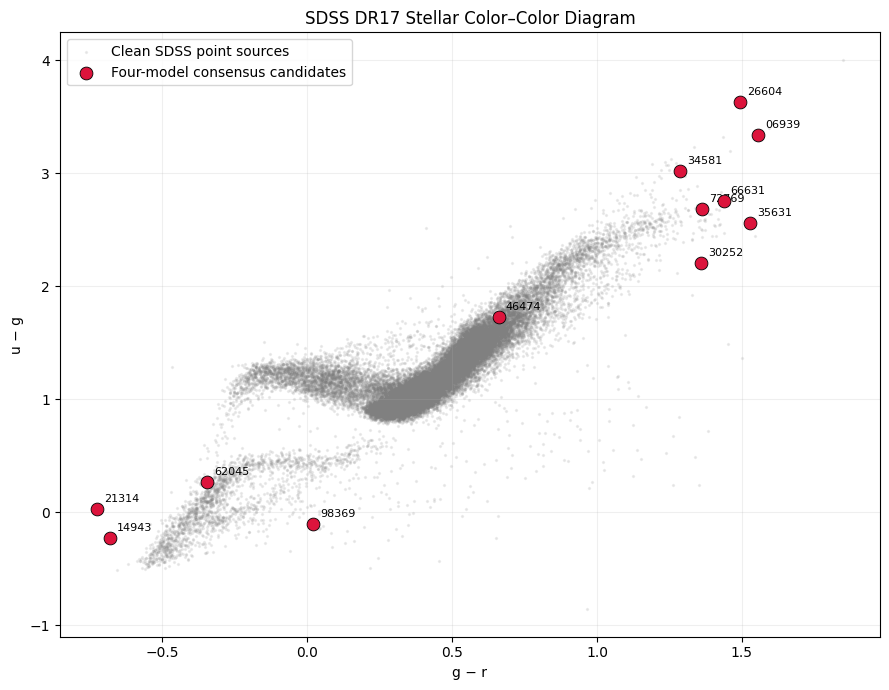

Background point sources: 35768
Candidates plotted: 12


In [192]:
import matplotlib.pyplot as plt

# Clean point-source reference population
point_sources = clean_stars[
    clean_stars["objid"].astype(str).isin(point_source_ids)
].copy()

# Match the 12 candidates
candidate_colors = point_sources[
    point_sources["objid"].astype(str).isin(
        spectroscopic_targets["objid"]
    )
].copy()

fig, ax = plt.subplots(figsize=(9, 7))

# Background stellar population
ax.scatter(
    point_sources["g-r"],
    point_sources["u-g"],
    s=2,
    alpha=0.12,
    color="gray",
    label="Clean SDSS point sources"
)

# Anomaly candidates
ax.scatter(
    candidate_colors["g-r"],
    candidate_colors["u-g"],
    s=85,
    color="crimson",
    edgecolor="black",
    linewidth=0.6,
    label="Four-model consensus candidates",
    zorder=5
)

# Label each candidate with final five digits
for _, row in candidate_colors.iterrows():
    ax.annotate(
        str(row["objid"])[-5:],
        (row["g-r"], row["u-g"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("g − r")
ax.set_ylabel("u − g")
ax.set_title("SDSS DR17 Stellar Color–Color Diagram")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Background point sources:", len(point_sources))
print("Candidates plotted:", len(candidate_colors))

In [193]:
# Combine candidate colors, errors, spectral types,
# and Monte Carlo retention into one diagnostic table.

color_diagnostics = (
    spectroscopic_targets[
        ["objid", "four_model_retention"]
    ]
    .merge(
        clean_stars[
            [
                "objid",
                "u-g", "g-r", "r-i", "i-z"
            ]
        ].assign(
            objid=lambda x: x["objid"].astype(str)
        ),
        on="objid",
        how="left"
    )
    .merge(
        candidate_errors[
            ["objid", "max_model_error"]
        ].assign(
            objid=lambda x: x["objid"].astype(str)
        ),
        on="objid",
        how="left"
    )
    .merge(
        spectra[
            ["objid", "subclass", "zWarning"]
        ],
        on="objid",
        how="left"
    )
)

display(
    color_diagnostics.round(3)
)

,objid,four_model_retention,u-g,g-r,r-i,i-z,max_model_error,subclass,zWarning
0,1237671256369135631,1.000,2.555,1.528,1.340,1.231,0.021,M5,0
1,1237650760242626604,1.000,3.632,1.495,0.329,0.736,0.017,M0,0
2,1237649768643166631,1.000,2.752,1.438,0.311,0.305,0.014,K3,0
3,1237670955177672769,1.000,2.686,1.362,0.211,0.754,0.018,M0,16
4,1237663231224906939,1.000,3.338,1.557,0.365,0.811,0.024,K5,16
5,1237668737371734581,1.000,3.016,1.286,0.180,0.622,0.012,K5,16
6,1237666214072614943,1.000,-0.229,-0.680,-0.620,-3.365,0.548,K5 (110281),0
7,1237646793309946474,0.991,1.724,0.661,-6.883,7.232,0.178,K0V (10780),2
8,1237671124302430252,0.985,2.208,1.360,2.204,-0.919,0.036,M0,0
9,1237652934030721314,0.940,0.029,-0.726,-0.432,-2.467,0.900,WD,0


In [194]:
# Inspect the original magnitudes and their uncertainties
# for all 12 anomaly candidates.

magnitude_diagnostics = (
    spectroscopic_targets[
        ["objid", "four_model_retention"]
    ]
    .merge(
        mc_candidates[
            ["objid",
             "u", "g", "r", "i", "z",
             "modelMagErr_u",
             "modelMagErr_g",
             "modelMagErr_r",
             "modelMagErr_i",
             "modelMagErr_z"]
        ].assign(
            objid=lambda x: x["objid"].astype(str)
        ),
        on="objid",
        how="left"
    )
)

display(
    magnitude_diagnostics.round(4)
)

,objid,four_model_retention,u,g,r,i,z,modelMagErr_u,modelMagErr_g,modelMagErr_r,modelMagErr_i,modelMagErr_z
0,1237671256369135631,1.000,19.0509,16.4961,14.9679,13.6278,12.3973,0.0212,0.0041,0.0035,0.0007,0.0037
1,1237650760242626604,1.000,18.6174,14.9855,13.4902,13.1612,12.4253,0.0173,0.0028,0.0030,0.0017,0.0029
2,1237649768643166631,1.000,17.4363,14.6845,13.2470,12.9365,12.6314,0.0145,0.0025,0.0022,0.0021,0.0027
3,1237670955177672769,1.000,18.6083,15.9222,14.5598,14.3490,13.5946,0.0184,0.0036,0.0036,0.0071,0.0037
4,1237663231224906939,1.000,18.9463,15.6087,14.0520,13.6872,12.8765,0.0236,0.0038,0.0035,0.0012,0.0040
5,1237668737371734581,1.000,17.7664,14.7503,13.4639,13.2836,12.6616,0.0120,0.0029,0.0029,0.0010,0.0029
6,1237666214072614943,1.000,17.8775,18.1067,18.7866,19.4065,22.7718,0.0112,0.0060,0.0100,0.0197,0.5482
7,1237646793309946474,0.991,17.0360,15.3121,14.6516,21.5350,14.3035,0.0073,0.0039,0.0046,0.1780,0.0046
8,1237671124302430252,0.985,19.4946,17.2869,15.9264,13.7224,14.6410,0.0361,0.0047,0.0037,0.0009,0.0046
9,1237652934030721314,0.940,19.2304,19.2011,19.9268,20.3592,22.8267,0.0277,0.0118,0.0235,0.0491,0.8996


In [195]:
import pandas as pd
import requests
from io import StringIO

ids = ",".join(
    spectroscopic_targets["objid"].astype(str)
)

sql = f"""
SELECT
    p.objid,
    p.clean,
    p.flags,
    p.flags_u,
    p.flags_g,
    p.flags_r,
    p.flags_i,
    p.flags_z,
    p.ra,
    p.dec
FROM PhotoObj AS p
WHERE p.objid IN ({ids})
"""

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

response_flags = requests.get(
    url,
    params={"cmd": sql, "format": "csv"},
    timeout=60
)

response_flags.raise_for_status()

print(response_flags.text[:500])

flags_df = pd.read_csv(
    StringIO(response_flags.text),
    comment="#",
    dtype={"objid": str}
)

display(flags_df)

print("Objects retrieved:", len(flags_df))

#Table1
objid,clean,flags,flags_u,flags_g,flags_r,flags_i,flags_z,ra,dec
1237646793309946474,1,202381275303984,268468240,268468240,4503599895969808,576627878473928752,275146375184,100.508322845431,0.464255790979234
1237649768643166631,1,35253360136208,268603408,268599312,4503599895973904,2251800082284560,268468240,358.09629279864,57.4317327909063
1237650760242626604,1,202381275303952,268599312,268599312,4503599895838736,587886877408133136,268603408,178.950084320516,-3.65189681988043
123765293403


,objid,clean,flags,flags_u,flags_g,flags_r,flags_i,flags_z,ra,dec
0,1237646793309946474,1,202381275303984,268468240,268468240,4503599895969808,576627878473928752,275146375184,100.508323,0.464256
1,1237649768643166631,1,35253360136208,268603408,268599312,4503599895973904,2251800082284560,268468240,358.096293,57.431733
2,1237650760242626604,1,202381275303952,268599312,268599312,4503599895838736,587886877408133136,268603408,178.950084,-3.651897
3,1237652934030721314,1,35287719875344,402685968,268603408,4503599904227856,402687248,11258999211065617,311.871053,-6.760175
4,1237658304890798369,1,105658611531792,275146506256,275146375184,4573968640016401,70369012645905,70643890552849,164.646604,59.559929
5,1237663231224906939,1,202381275303952,2252074960060432,268468240,4503599895838736,587886877408133136,268603408,336.910998,70.035308
6,1237663547981562045,1,35253360132112,275146375184,268599312,4503599895838736,2251800082153488,134250513,139.421957,62.889227
7,1237666214072614943,1,123216437838096,268599312,17592454643728,4573968640147473,70369012645905,9007199263162641,19.211294,20.381427
8,1237668737371734581,1,202415635042320,268603408,268603408,4503599895973904,587886877408133136,268468240,286.547312,40.399333
9,1237670955177672769,1,202381275303952,268468240,268468240,4503599895973904,867110054305107984,268468240,24.542967,-10.418481


Objects retrieved: 12


In [196]:
import requests
import pandas as pd
from io import StringIO

ids = ",".join(
    spectroscopic_targets["objid"].astype(str)
)

sql = f"""
SELECT
    p.objid,
    dbo.fPhotoFlags(p.flags_u) AS decoded_u,
    dbo.fPhotoFlags(p.flags_g) AS decoded_g,
    dbo.fPhotoFlags(p.flags_r) AS decoded_r,
    dbo.fPhotoFlags(p.flags_i) AS decoded_i,
    dbo.fPhotoFlags(p.flags_z) AS decoded_z
FROM PhotoObj AS p
WHERE p.objid IN ({ids})
"""

response_decoded = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={"cmd": sql, "format": "csv"},
    timeout=60
)

response_decoded.raise_for_status()

print(response_decoded.text[:500])

decoded_flags = pd.read_csv(
    StringIO(response_decoded.text),
    comment="#",
    dtype={"objid": str}
)

display(decoded_flags)

#Table1
objid,decoded_u,decoded_g,decoded_r,decoded_i,decoded_z
1237646793309946474,,,,,
1237649768643166631,,,,,
1237650760242626604,,,,,
1237652934030721314,,,,,
1237658304890798369,,,,,
1237663231224906939,,,,,
1237663547981562045,,,,,
1237666214072614943,,,,,
1237668737371734581,,,,,
1237670955177672769,,,,,
1237671124302430252,,,,,
1237671256369135631,,,,,



,objid,decoded_u,decoded_g,decoded_r,decoded_i,decoded_z
0,1237646793309946474,NaN,NaN,NaN,NaN,NaN
1,1237649768643166631,NaN,NaN,NaN,NaN,NaN
2,1237650760242626604,NaN,NaN,NaN,NaN,NaN
3,1237652934030721314,NaN,NaN,NaN,NaN,NaN
4,1237658304890798369,NaN,NaN,NaN,NaN,NaN
5,1237663231224906939,NaN,NaN,NaN,NaN,NaN
6,1237663547981562045,NaN,NaN,NaN,NaN,NaN
7,1237666214072614943,NaN,NaN,NaN,NaN,NaN
8,1237668737371734581,NaN,NaN,NaN,NaN,NaN
9,1237670955177672769,NaN,NaN,NaN,NaN,NaN


In [197]:
# SDSS photometric flag bit positions
# These are the standard PhotoFlags bit assignments.

flag_bits = {
    "SATURATED": 18,
    "NOTCHECKED": 19,
    "SUBTRACTED": 20,
    "INTERP_CENTER": 17,
    "PSF_FLUX_INTERP": 23,
    "BAD_COUNTS_ERROR": 25,
    "DEBLEND_NOPEAK": 26,
    "INTERP": 28,
    "EDGE": 2,
    "BLENDED": 3,
    "CHILD": 4,
    "CR": 12,
}

def decode_flags(value):
    if pd.isna(value):
        return []

    value = int(value)

    return [
        name
        for name, bit in flag_bits.items()
        if value & (1 << bit)
    ]

flag_summary = flags_df[["objid", "clean"]].copy()

for band in ["u", "g", "r", "i", "z"]:
    flag_summary[f"{band}_issues"] = flags_df[
        f"flags_{band}"
    ].apply(decode_flags)

display(flag_summary)

,objid,clean,u_issues,g_issues,r_issues,i_issues,z_issues
0,1237646793309946474,1,"[INTERP, CHILD]","[INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD]","[SATURATED, INTERP_CENTER, INTERP, CHILD, CR]","[INTERP, CHILD]"
1,1237649768643166631,1,"[INTERP_CENTER, INTERP, CHILD, CR]","[INTERP_CENTER, INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD, CR]","[INTERP_CENTER, INTERP, CHILD]","[INTERP, CHILD]"
2,1237650760242626604,1,"[INTERP_CENTER, INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD]","[INTERP, CHILD]","[SATURATED, INTERP_CENTER, INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD, CR]"
3,1237652934030721314,1,"[INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD, CR]","[PSF_FLUX_INTERP, INTERP, CHILD]","[INTERP, CHILD]","[PSF_FLUX_INTERP, CHILD]"
4,1237658304890798369,1,"[INTERP_CENTER, INTERP, CHILD]","[INTERP, CHILD]","[INTERP, CHILD]","[INTERP, CHILD]","[INTERP, CHILD]"
5,1237663231224906939,1,"[INTERP, CHILD]","[INTERP, CHILD]","[INTERP, CHILD]","[SATURATED, INTERP_CENTER, INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD, CR]"
6,1237663547981562045,1,"[INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD]","[INTERP, CHILD]","[INTERP, CHILD]",[CHILD]
7,1237666214072614943,1,"[INTERP_CENTER, INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD]","[INTERP, CHILD]","[PSF_FLUX_INTERP, CHILD]"
8,1237668737371734581,1,"[INTERP_CENTER, INTERP, CHILD, CR]","[INTERP_CENTER, INTERP, CHILD, CR]","[INTERP_CENTER, INTERP, CHILD, CR]","[SATURATED, INTERP_CENTER, INTERP, CHILD]","[INTERP, CHILD]"
9,1237670955177672769,1,"[INTERP, CHILD]","[INTERP, CHILD]","[INTERP_CENTER, INTERP, CHILD, CR]","[SATURATED, INTERP_CENTER, INTERP, CHILD, CR]","[INTERP, CHILD]"


In [198]:
import requests
import pandas as pd
from io import StringIO

sql = """
SELECT
    name,
    value,
    description
FROM PhotoFlags
ORDER BY value
"""

response_definitions = requests.get(
    "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch",
    params={
        "cmd": sql,
        "format": "csv"
    },
    timeout=60
)

response_definitions.raise_for_status()

print(response_definitions.text[:1000])

#Table1
name,value,description
CANONICAL_CENTER,0x0000000000000001,"Measurements used the center in r*, rather than the locally determined center."
BRIGHT,0x0000000000000002,"Object detected in first, bright object-finding; generally r*<17.5"
EDGE,0x0000000000000004,Object is too close to edge of frame
BLENDED,0x0000000000000008,Object had multiple peaks detected within it; was thus a candidate to be a deblending parent.
CHILD,0x0000000000000010,Object is the product of an attempt to deblend a BLENDED object.
PEAKCENTER,0x0000000000000020,"Given center is position of peak pixel, rather than based on the maximum-likelihood estimator."
NODEBLEND,0x0000000000000040,"No deblending was attempted on this object, even though it is BLENDED."
NOPROFILE,0x0000000000000080,Object was too small or too close to the edge to estimate a radial profile.
NOPETRO,0x0000000000000100,No valid Petrosian radius was found for this object.
MANYPETRO,0x0000000000000200,More than one Petrosian radius was found.


In [199]:
from io import StringIO
import pandas as pd

# Read the full official SDSS flag-definition response
flag_definitions = pd.read_csv(
    StringIO(response_definitions.text),
    comment="#",
    dtype=str
)

# Convert hexadecimal masks to Python integers
flag_definitions["mask"] = (
    flag_definitions["value"].apply(
        lambda x: int(x, 16)
    )
)

# Decode using official SDSS masks
def decode_official_flags(value):
    if pd.isna(value):
        return []

    value = int(value)

    return [
        row["name"]
        for _, row in flag_definitions.iterrows()
        if value & row["mask"]
    ]

verified_flags = flags_df[
    ["objid", "clean"]
].copy()

for band in ["u", "g", "r", "i", "z"]:
    verified_flags[f"{band}_flags"] = (
        flags_df[f"flags_{band}"]
        .apply(decode_official_flags)
    )

print("Official flag definitions:", len(flag_definitions))
display(verified_flags)

Official flag definitions: 64


,objid,clean,u_flags,g_flags,r_flags,i_flags,z_flags
0,1237646793309946474,1,"[CHILD, BAD_RADIAL, BINNED1]","[CHILD, BAD_RADIAL, BINNED1]","[CHILD, BAD_RADIAL, INTERP, BINNED1, CANONICAL_BAND]","[CHILD, PEAKCENTER, COSMIC_RAY, BAD_RADIAL, INTERP, SATURATED, ELLIPFAINT, BINNED1, SATUR_CENTER, INTERP_CENTER, PSF_FLUX_INTERP, OBJECT2_HAS_SATUR_DN]","[CHILD, BAD_RADIAL, BINNED1, MEDIAN_CENTER]"
1,1237649768643166631,1,"[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1]","[CHILD, BAD_RADIAL, INTERP, BINNED1]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1, CANONICAL_BAND]","[CHILD, BAD_RADIAL, INTERP, BINNED1, BRIGHTEST_GALAXY_CHILD]","[CHILD, BAD_RADIAL, BINNED1]"
2,1237650760242626604,1,"[CHILD, BAD_RADIAL, INTERP, BINNED1]","[CHILD, BAD_RADIAL, INTERP, BINNED1]","[CHILD, BAD_RADIAL, BINNED1, CANONICAL_BAND]","[CHILD, BAD_RADIAL, INTERP, SATURATED, BINNED1, SATUR_CENTER, INTERP_CENTER, PSF_FLUX_INTERP, BRIGHTEST_GALAXY_CHILD, AMOMENT_FAINT, OBJECT2_HAS_SATUR_DN]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1]"
3,1237652934030721314,1,"[CHILD, BAD_RADIAL, ELLIPFAINT, BINNED1]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1]","[CHILD, MANYPETRO, BAD_RADIAL, PETROFAINT, BINNED1, CANONICAL_BAND]","[CHILD, NOPETRO, NOPETRO_BIG, BAD_RADIAL, ELLIPFAINT, BINNED1]","[CANONICAL_CENTER, CHILD, NOPETRO, BAD_RADIAL, PETROFAINT, ELLIPFAINT, BRIGHTEST_GALAXY_CHILD, AMOMENT_FAINT]"
4,1237658304890798369,1,"[CHILD, BAD_RADIAL, INTERP, BINNED1, MEDIAN_CENTER]","[CHILD, BAD_RADIAL, BINNED1, MEDIAN_CENTER]","[CANONICAL_CENTER, CHILD, BAD_RADIAL, BINNED1, DEBLEND_NOPEAK, CANONICAL_BAND]","[CANONICAL_CENTER, CHILD, BAD_RADIAL, BINNED1, DEBLEND_NOPEAK]","[CANONICAL_CENTER, CHILD, BAD_RADIAL, BINNED1, MEDIAN_CENTER, DEBLEND_NOPEAK]"
5,1237663231224906939,1,"[CHILD, BAD_RADIAL, BINNED1, MEDIAN_CENTER, BRIGHTEST_GALAXY_CHILD]","[CHILD, BAD_RADIAL, BINNED1]","[CHILD, BAD_RADIAL, BINNED1, CANONICAL_BAND]","[CHILD, BAD_RADIAL, INTERP, SATURATED, BINNED1, SATUR_CENTER, INTERP_CENTER, PSF_FLUX_INTERP, BRIGHTEST_GALAXY_CHILD, AMOMENT_FAINT, OBJECT2_HAS_SATUR_DN]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1]"
6,1237663547981562045,1,"[CHILD, BAD_RADIAL, BINNED1, MEDIAN_CENTER]","[CHILD, BAD_RADIAL, INTERP, BINNED1]","[CHILD, BAD_RADIAL, BINNED1, CANONICAL_BAND]","[CHILD, BAD_RADIAL, BINNED1, BRIGHTEST_GALAXY_CHILD]","[CANONICAL_CENTER, CHILD, BAD_RADIAL, ELLIPFAINT]"
7,1237666214072614943,1,"[CHILD, BAD_RADIAL, INTERP, BINNED1]","[CHILD, BAD_RADIAL, INTERP, BINNED1, INTERP_CENTER]","[CANONICAL_CENTER, CHILD, BAD_RADIAL, INTERP, BINNED1, DEBLEND_NOPEAK, CANONICAL_BAND]","[CANONICAL_CENTER, CHILD, BAD_RADIAL, BINNED1, DEBLEND_NOPEAK]","[CANONICAL_CENTER, CHILD, NOPETRO, BAD_RADIAL, PETROFAINT, AMOMENT_FAINT]"
8,1237668737371734581,1,"[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1, CANONICAL_BAND]","[CHILD, BAD_RADIAL, INTERP, SATURATED, BINNED1, SATUR_CENTER, INTERP_CENTER, PSF_FLUX_INTERP, BRIGHTEST_GALAXY_CHILD, AMOMENT_FAINT, OBJECT2_HAS_SATUR_DN]","[CHILD, BAD_RADIAL, BINNED1]"
9,1237670955177672769,1,"[CHILD, BAD_RADIAL, BINNED1]","[CHILD, BAD_RADIAL, BINNED1]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, BINNED1, CANONICAL_BAND]","[CHILD, COSMIC_RAY, BAD_RADIAL, INTERP, SATURATED, BINNED1, SATUR_CENTER, INTERP_CENTER, PSF_FLUX_INTERP, BRIGHTEST_GALAXY_CHILD, NOTCHECKED_CENTER, OBJECT2_HAS_SATUR_DN]","[CHILD, BAD_RADIAL, BINNED1]"


In [200]:
# Summarize selected photometric-quality warnings.
# These are screening indicators, not definitive artifact labels.

priority_flags = {
    "SATURATED",
    "SATUR_CENTER",
    "BAD_COUNTS_ERROR",
    "INTERP_CENTER",
    "PSF_FLUX_INTERP",
    "COSMIC_RAY",
    "DEBLEND_NOPEAK"
}

quality_summary = verified_flags[["objid", "clean"]].copy()

for band in ["u", "g", "r", "i", "z"]:
    quality_summary[f"{band}_priority_flags"] = (
        verified_flags[f"{band}_flags"].apply(
            lambda names: sorted(
                priority_flags.intersection(names)
            )
        )
    )

quality_summary["flagged_band_count"] = (
    quality_summary[
        [f"{b}_priority_flags" for b in "ugriz"]
    ]
    .apply(
        lambda row: sum(bool(flags) for flags in row),
        axis=1
    )
)

quality_summary = (
    spectroscopic_targets[
        ["objid", "four_model_retention"]
    ]
    .merge(
        quality_summary,
        on="objid",
        how="left",
        validate="one_to_one"
    )
)

display(quality_summary)

,objid,four_model_retention,clean,u_priority_flags,g_priority_flags,r_priority_flags,i_priority_flags,z_priority_flags,flagged_band_count
0,1237671256369135631,1.000,1,[],[],[],"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],1
1,1237650760242626604,1.000,1,[],[],[],"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[COSMIC_RAY],2
2,1237649768643166631,1.000,1,[COSMIC_RAY],[],[COSMIC_RAY],[],[],2
3,1237670955177672769,1.000,1,[],[],[COSMIC_RAY],"[COSMIC_RAY, INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],2
4,1237663231224906939,1.000,1,[],[],[],"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[COSMIC_RAY],2
5,1237668737371734581,1.000,1,[COSMIC_RAY],[COSMIC_RAY],[COSMIC_RAY],"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],4
6,1237666214072614943,1.000,1,[],[INTERP_CENTER],[DEBLEND_NOPEAK],[DEBLEND_NOPEAK],[],3
7,1237646793309946474,0.991,1,[],[],[],"[COSMIC_RAY, INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],1
8,1237671124302430252,0.985,1,[DEBLEND_NOPEAK],"[COSMIC_RAY, DEBLEND_NOPEAK]",[],"[BAD_COUNTS_ERROR, DEBLEND_NOPEAK, INTERP_CENTER, SATURATED, SATUR_CENTER]",[],3
9,1237652934030721314,0.940,1,[],[COSMIC_RAY],[],[],[],1


In [201]:
# Reference population used for the corrected
# point-source anomaly thresholds.

reference_ids = (
    clean_retrained.loc[
        eligible_mask, "objid"
    ]
    .astype(str)
    .reset_index(drop=True)
)

candidate_ids = set(
    spectroscopic_targets["objid"].astype(str)
)

print("Reference population:", len(reference_ids))
print("Unique reference IDs:", reference_ids.nunique())

print(
    "Candidates present in reference:",
    sum(reference_ids.isin(candidate_ids))
)

print(
    "Non-candidate reference objects:",
    (~reference_ids.isin(candidate_ids)).sum()
)

Reference population: 35768
Unique reference IDs: 35768
Candidates present in reference: 12
Non-candidate reference objects: 35756


In [203]:
import requests
import pandas as pd
from io import StringIO
import time

url = "https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch"

batch_size = 300
all_flag_batches = []

for start in range(0, len(reference_ids), batch_size):

    batch = reference_ids.iloc[
        start:start + batch_size
    ].tolist()

    ids = ",".join(batch)

    sql = f"""
    SELECT
        objid,
        flags_i
    FROM PhotoObj
    WHERE objid IN ({ids})
    """

    response = requests.get(
        url,
        params={"cmd": sql, "format": "csv"},
        timeout=60
    )

    response.raise_for_status()

    batch_df = pd.read_csv(
        StringIO(response.text),
        comment="#",
        dtype={"objid": str, "flags_i": str}
    )

    if not {"objid", "flags_i"}.issubset(batch_df.columns):
        raise ValueError(
            f"Unexpected SDSS response in batch {start}: "
            f"{response.text[:300]}"
        )

    all_flag_batches.append(batch_df)

    if (start // batch_size + 1) % 20 == 0:
        print(
            f"Retrieved {min(start + batch_size, len(reference_ids)):,}"
            f" / {len(reference_ids):,} objects"
        )

    time.sleep(0.1)

reference_i_flags = pd.concat(
    all_flag_batches,
    ignore_index=True
)

# Verify complete retrieval before analysis
assert reference_i_flags["objid"].nunique() == len(reference_ids)

# Obtain the official SDSS SATURATED bitmask
saturated_mask = int(
    flag_definitions.loc[
        flag_definitions["name"] == "SATURATED",
        "mask"
    ].iloc[0]
)

# Decode the i-band SATURATED flag
reference_i_flags["i_saturated"] = (
    reference_i_flags["flags_i"]
    .apply(lambda x: bool(int(x) & saturated_mask))
)

candidate_set = set(spectroscopic_targets["objid"].astype(str))

reference_i_flags["is_candidate"] = (
    reference_i_flags["objid"].isin(candidate_set)
)

summary = (
    reference_i_flags
    .groupby("is_candidate")["i_saturated"]
    .agg(["sum", "count", "mean"])
)

display(summary)

print(
    "\nCandidate saturation rate:",
    f"{summary.loc[True, 'mean']:.2%}"
)

print(
    "Non-candidate saturation rate:",
    f"{summary.loc[False, 'mean']:.2%}"
)

Retrieved 6,000 / 35,768 objects
Retrieved 12,000 / 35,768 objects
Retrieved 18,000 / 35,768 objects
Retrieved 24,000 / 35,768 objects
Retrieved 30,000 / 35,768 objects
Retrieved 35,768 / 35,768 objects


,sum,count,mean
is_candidate,,,
False,143,35756,0.003999
True,7,12,0.583333



Candidate saturation rate: 58.33%
Non-candidate saturation rate: 0.40%


In [204]:
from scipy.stats import fisher_exact
import numpy as np
import pandas as pd

# Contingency table:
# [saturated, not saturated]

contingency = np.array([
    [7, 5],
    [143, 35613]
])

odds_ratio, p_value = fisher_exact(
    contingency,
    alternative="greater"
)

candidate_rate = 7 / 12
reference_rate = 143 / 35756

prevalence_ratio = candidate_rate / reference_rate

print("Contingency table:")
display(pd.DataFrame(
    contingency,
    index=["Consensus candidates", "Non-candidates"],
    columns=["Saturated", "Not saturated"]
))

print(f"Odds ratio: {odds_ratio:.2f}")
print(f"Prevalence ratio: {prevalence_ratio:.2f}")
print(f"Fisher exact p-value: {p_value:.4e}")

Contingency table:


,Saturated,Not saturated
Consensus candidates,7,5
Non-candidates,143,35613


Odds ratio: 348.66
Prevalence ratio: 145.86
Fisher exact p-value: 1.5412e-14


,count,median,mean,min,max
group,,,,,
Consensus / Not saturated,5,19.44486,18.184020,13.24697,19.92676
Consensus / Saturated,7,14.55977,14.444511,13.46386,15.92640
Non-candidate / Not saturated,35613,16.88235,16.842344,12.89430,20.48627
Non-candidate / Saturated,143,14.75046,15.014299,13.20633,18.52238


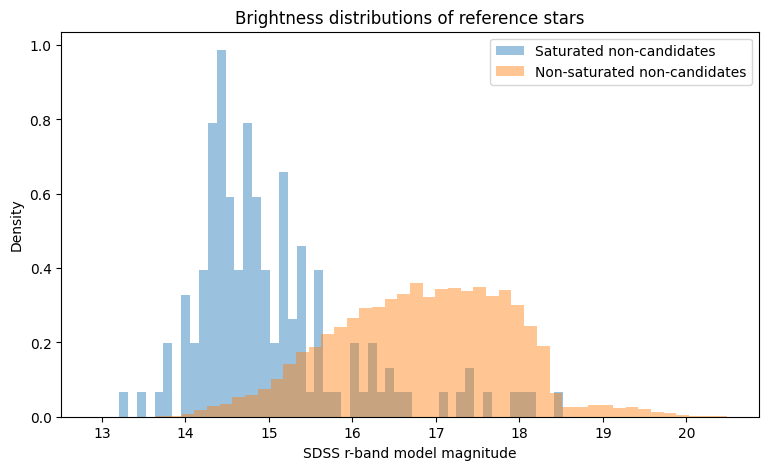

In [205]:
# Attach the reference population's r-band magnitudes
# to the previously retrieved i-band saturation flags.

reference_photometry = (
    clean_stars[["objid", "r"]]
    .copy()
)

reference_photometry["objid"] = (
    reference_photometry["objid"].astype(str)
)

brightness_df = (
    reference_i_flags
    .merge(
        reference_photometry,
        on="objid",
        how="left",
        validate="one_to_one"
    )
)

assert brightness_df["r"].notna().all()

brightness_df["group"] = (
    brightness_df["is_candidate"].map({
        True: "Consensus",
        False: "Non-candidate"
    })
    + " / "
    + brightness_df["i_saturated"].map({
        True: "Saturated",
        False: "Not saturated"
    })
)

summary_brightness = (
    brightness_df
    .groupby("group")["r"]
    .agg(["count", "median", "mean", "min", "max"])
)

display(summary_brightness)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for saturated, label in [
    (True, "Saturated non-candidates"),
    (False, "Non-saturated non-candidates")
]:
    subset = brightness_df[
        (~brightness_df["is_candidate"])
        & (brightness_df["i_saturated"] == saturated)
    ]

    plt.hist(
        subset["r"],
        bins=50,
        density=True,
        alpha=0.45,
        label=label
    )

plt.xlabel("SDSS r-band model magnitude")
plt.ylabel("Density")
plt.title("Brightness distributions of reference stars")
plt.legend()
plt.show()

In [206]:
import numpy as np
import pandas as pd

# Define r-band magnitude intervals
bins = [12, 14, 15, 16, 17, 18, 19, 21]

brightness_df["r_bin"] = pd.cut(
    brightness_df["r"],
    bins=bins,
    right=False
)

# Count candidates and saturation status in each bin
brightness_strata = (
    brightness_df
    .groupby(
        ["r_bin", "is_candidate", "i_saturated"],
        observed=False
    )
    .size()
    .unstack(
        ["is_candidate", "i_saturated"],
        fill_value=0
    )
)

# Display every combination explicitly
expected_columns = pd.MultiIndex.from_product(
    [[False, True], [False, True]],
    names=["is_candidate", "i_saturated"]
)

brightness_strata = brightness_strata.reindex(
    columns=expected_columns,
    fill_value=0
)

brightness_strata.columns = [
    "Noncandidate_not_saturated",
    "Noncandidate_saturated",
    "Candidate_not_saturated",
    "Candidate_saturated"
]

display(brightness_strata)

print(
    "\nTotal objects:",
    brightness_strata.to_numpy().sum()
)

,Noncandidate_not_saturated,Noncandidate_saturated,Candidate_not_saturated,Candidate_saturated
r_bin,,,,
"[12, 14)",25,8,1,2
"[14, 15)",1413,81,0,4
"[15, 16)",6454,33,0,1
"[16, 17)",11255,12,0,0
"[17, 18)",12058,6,0,0
"[18, 19)",3715,3,1,0
"[19, 21)",693,0,3,0



Total objects: 35768


In [207]:
import numpy as np
from statsmodels.stats.contingency_tables import StratifiedTable

# r-band strata containing saturated consensus candidates
selected_bins = [
    brightness_strata.index[0],
    brightness_strata.index[1],
    brightness_strata.index[2]
]

tables = []

for bin_label in selected_bins:
    row = brightness_strata.loc[bin_label]

    table = np.array([
        [
            row["Candidate_saturated"],
            row["Candidate_not_saturated"]
        ],
        [
            row["Noncandidate_saturated"],
            row["Noncandidate_not_saturated"]
        ]
    ], dtype=int)

    tables.append(table)

cmh = StratifiedTable(tables)

print("Brightness-adjusted CMH results")
print("-------------------------------")
print(f"Pooled odds ratio: {cmh.oddsratio_pooled:.3f}")
print(f"95% CI: {cmh.oddsratio_pooled_confint()}")
print(f"CMH p-value: {cmh.test_null_odds().pvalue:.6e}")

print("\nStrata included:")
for label, table in zip(selected_bins, tables):
    print(label, table.tolist())

Brightness-adjusted CMH results
-------------------------------
Pooled odds ratio: 27.705
95% CI: (4.312957701847302, 177.9683899937377)
CMH p-value: 2.196476e-11

Strata included:
[12, 14) [[2, 1], [8, 25]]
[14, 15) [[4, 0], [81, 1413]]
[15, 16) [[1, 0], [33, 6454]]


In [210]:
# Find the DataFrame containing our spectroscopic results

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        required = {"objid", "subclass", "zWarning", "snMedian"}

        if required.issubset(obj.columns):
            print(f"Found: {name}")
            print(f"Rows: {len(obj)}")
            print(f"Columns: {list(obj.columns)}")
            print()

Found: spectra
Rows: 12
Columns: ['objid', 'specobjid', 'class', 'subclass', 'z', 'zErr', 'zWarning', 'snMedian', 'plate', 'mjd', 'fiberID']

Found: spectra_validated
Rows: 12
Columns: ['objid', 'four_model_retention', 'specobjid', 'class', 'subclass', 'z', 'zErr', 'zWarning', 'snMedian', 'plate', 'mjd', 'fiberID']



In [211]:
# Combine spectroscopic validation with photometric quality

final_candidates = (
    spectra_validated[
        ["objid", "class", "subclass", "zWarning",
         "snMedian", "four_model_retention"]
    ]
    .copy()
)

final_candidates["objid"] = final_candidates["objid"].astype(str)

quality_columns = [
    "objid",
    "flagged_band_count",
    "i_priority_flags",
    "z_priority_flags"
]

final_candidates = final_candidates.merge(
    quality_summary[quality_columns],
    on="objid",
    how="left",
    validate="one_to_one"
)

# Identify important i-band quality warnings
severe_i_flags = {
    "SATURATED",
    "BAD_COUNTS_ERROR",
    "SATUR_CENTER"
}

final_candidates["i_band_warning"] = (
    final_candidates["i_priority_flags"].apply(
        lambda flags: bool(
            severe_i_flags.intersection(flags)
        )
    )
)

# Sort by Monte Carlo retention
final_candidates = final_candidates.sort_values(
    "four_model_retention",
    ascending=False
).reset_index(drop=True)

display(final_candidates)

print("Total candidates:", len(final_candidates))
print(
    "Candidates with i-band warnings:",
    final_candidates["i_band_warning"].sum()
)

# Save for the research paper
final_candidates.to_csv(
    "SDSS_final_candidates.csv",
    index=False
)

print("Saved: SDSS_final_candidates.csv")

,objid,class,subclass,zWarning,snMedian,four_model_retention,flagged_band_count,i_priority_flags,z_priority_flags,i_band_warning
0,1237671256369135631,STAR,M5,0,57.81644,1.000,1,"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],True
1,1237650760242626604,STAR,M0,0,49.46388,1.000,2,"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[COSMIC_RAY],True
2,1237649768643166631,STAR,K3,0,24.98715,1.000,2,[],[],False
3,1237670955177672769,STAR,M0,16,66.58027,1.000,2,"[COSMIC_RAY, INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],True
4,1237663231224906939,STAR,K5,16,64.88883,1.000,2,"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[COSMIC_RAY],True
5,1237668737371734581,STAR,K5,16,53.69095,1.000,4,"[INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],True
6,1237666214072614943,STAR,K5 (110281),0,24.84668,1.000,3,[DEBLEND_NOPEAK],[],False
7,1237646793309946474,STAR,K0V (10780),2,26.46480,0.991,1,"[COSMIC_RAY, INTERP_CENTER, PSF_FLUX_INTERP, SATURATED, SATUR_CENTER]",[],True
8,1237671124302430252,STAR,M0,0,49.71876,0.985,3,"[BAD_COUNTS_ERROR, DEBLEND_NOPEAK, INTERP_CENTER, SATURATED, SATUR_CENTER]",[],True
9,1237652934030721314,STAR,WD,0,19.62164,0.940,1,[],[],False


Total candidates: 12
Candidates with i-band warnings: 7
Saved: SDSS_final_candidates.csv
